# Inferring bodies of knowledge from ceramic chaînes opératoires

*Computational network archaeology on the Funnel Beaker West and Corded Ware vessels of Kroon (2024).*

A **chaîne opératoire** is the ordered sequence of techniques a potter used, e.g.

``Wet clay > Modelling > Coiling > Pressure > Scraping > Wet smoothing > Simple incision > Leather-hard > Dry > Open firing``.

Kroon (2024) recorded one chain for each of 276 vessels from the Netherlands, made by potters of the **Corded Ware** (CW, 3000–2350 BCE) and of the **Funnel Beaker West** (FBW, 4000–2800 BCE) in three phases.

**Questions**
1. **Attribution** – given the chain of a new vessel, which body of knowledge (BoK) or culture made it?
2. **Reconstruction** – given an incomplete chain, which steps are missing?
3. **Relations** – how different are the BoKs (Cultures), and what do they share?

**Approach.** Kroon compares BoKs (Cultures) through the edge weights $p(x_{t+1}\mid x_t)$ of a network of techniques. The earlier notebook `Presentation_topic_modelling.ipynb` (in `legacy/`) treats *triplets* of consecutive techniques as words, vessels as documents and BoKs as topics, and fits two topic models: **LDA** and the **hierarchical stochastic block model** (hSBM) of Gerlach, Peixoto & Altmann (2018). 

* Sections 4–6 replicate that notebook step by step with its own functions (same names, checked and corrected) and complete the hSBM with graph-tool's inference workflow. 
* Section 7 tests how solid the results are; 
* Section 8 gives the topic models richer data — vessel form, location and find context; 
* Section 9 replaces triplets by n-grams of every length; 
* Section 10 treats the chains as networks and sequences (n-gram networks, Markov models, reconstruction).

Random experiments including: survival and selection, missing steps, geography and maximum entropy (with the Maximum Caliber sketch) are in the auxiliary notebook [`new_attempts_experiments.ipynb`](new_attempts_experiments.ipynb).

**Main results** (details and caveats in the sections)
- **Replication.** The legacy topic-model notebook is reproduced step by step with its own functions. 
    * Scored in-sample as there, the hSBM classifies 0.61–0.62 of the vessels correctly, and its 4 pseudo-document groups largely coincide with the four BoKs (NMI 0.78).
    * Scored out-of sample , the accuracy drops to 0.50–0.54 for the four BoKs. 
- **Much of that separation comes from the bootstrap.** Pseudo-documents built from *randomly permuted* labels still yield clusters that "recover" them (hSBM NMI ≈ 0.35 at the no-resampling setting, ≈ 0.75 with 15 vessels per document). On single vessels the hSBM groups are only weakly related to BoK (NMI ≈ 0.15), and MDL rejects the overlapping model.
- **Honest accuracy is modest.** With whole sites held out, every technique-based model — LDA, both hSBM classifiers, naive Bayes, Markov — reaches 0.50–0.54 for the four BoKs (majority 0.34; ceiling 0.73, set by identical chains in different BoKs); CW vs FBW ≈ 0.80–0.82, meaning that the model can distinguish between the two macro-groups.
- **LDA vs hSBM.** The hSBM infers 24 topics at level 0, 4 at level 1. It reproduces the cultures' triplet distributions more closely than LDA's four (JS 0.006 vs 0.022 bits), and fold-in by description length is the principled way to place a new vessel in it. For attribution the two are within noise under 5-fold cross-validation (hSBM 0.52–0.53, LDA 0.50); LDA's probabilities are better calibrated.
- **Better attribution from the same chains (7.6).** Adding the transition probabilities to LDA lifts it to 0.56 (+0.06 ± 0.03); learning a weight for every transition (maximum entropy) gives the best-calibrated probabilities of all chain models.
- **Richer data (Section 8).** Given vessel form, region and grid cell as extra words, the tripartite hSBM rises from 0.52 to 0.60 with sites held out and LDA from 0.50 to 0.56; the metadata alone give 0.56. With the site type added, the metadata alone (0.73) beat LDA and match the hSBM; none of these topic-model gains exceeds 1.5 standard errors. All the evidence is combined better by a maximum-entropy classifier (0.69 without site type; auxiliary notebook [`new_attempts_experiments.ipynb`](new_attempts_experiments.ipynb)).
- **Survival and selection (auxiliary notebook [`new_attempts_experiments.ipynb`](new_attempts_experiments.ipynb).).** A survival probability that depends on the chain cancels from attribution, and for token-wise survival the fitted topics absorb it exactly. So no survival model can raise the best accuracy for vessels selected like the training ones, and survival cannot be identified from survivors. What does help LDA is to *use* the selection instead of discarding it: the survivor proportions give a small gain, and the find context as a selection model gives a large one (≈ 0.51 → 0.77 with sites held out, under a stated independence assumption). An oracle knowing each site's composition would reach ≈ 0.95: the information is in the selection, not in the chains.
- **Co-occurrence (7.7).** The culture is in *which* techniques a vessel uses: learned weights on that set (0.54) match order-aware models, and co-occurring pairs add nothing. The biterm topic model, built for short texts, needs no pseudo-documents but its unsupervised topics barely follow the BoKs (0.44).
- **Time and transfer (10.8).** Kroon's radiocarbon dates, calibrated with IntCal20, place the late flat graves beside CW for about 250 years. In that time they moved *away* from CW: no CW technique or bag of techniques was adopted.
- **n-grams.** For n ≥ 2 a bag of n-grams determines the chain . Accuracy hardly changes with n from n = 3 on (≈ 0.49–0.53), while bag-of-n-gram classifiers grow more over-confident as each step is counted n times. Walks on n-gram networks are order-n Markov chains (proved); held-out, pairs and triplets suffice and longer windows memorise.
- **Sequences and reconstruction.** Pairs of steps (Kroon's edge weights) carry almost all sequential information; a hidden step is recovered exactly for 67–75 % of held-out vessels (top-3 ≈ 95 %). Kroon's Wasserstein comparison ignores which edge is which; edge-aware distances agree that CW is farthest from late FBW.

**Roadmap** — 1 Data · 2 Representation · 3 Protocol · 4 LDA · 5 hSBM · 6 LDA vs hSBM · 7 Solidity: bootstrap, cross-validation, confounders, co-occurrence · 8 Topic models with richer data · 9 n-grams in the topic models · 10 Networks, n-gram networks, sequences and time · 11 Critical assessment · 12 Conclusions, data, references · *auxiliary notebook:* survival, missing steps, geography, maximum entropy

In [7]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message="unrecognized keyword arguments")  # graph-tool

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from chaine import data, markov, distances, sbm, reconstruction, maxcal
from chaine import topic_model as tm, classifiers as clf, evaluation as ev, plotting as pl
from chaine.data import BOKS

pl.setup()
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)
SEED = 0                                   # one seed for the split, the bootstrap, LDA and the hSBM
STOP_K = 0                                 # <- STOP TRIPLETS: the STOP_K most frequent training triplets are deleted
                                           #    before fitting (legacy: 5). STOP_K = 0 keeps every triplet; they are
                                           #    informative (4.1) and the choice moves accuracy by about 1 point (7.4).
N_FOLDS = 5                               # <- CROSS-VALIDATION: number of folds in Sections 7-10; each model trains on
                                           #    1 - 1/N_FOLDS of the sites. Sections 4-6 use one 80/20 split.
RUN_SBM = sbm.graph_tool_available()       # Sections 5-7 need graph-tool (conda-forge)
print("graph-tool available:", RUN_SBM)

graph-tool available: True


In [2]:
# Helpers defined in this notebook (legacy-style overlays; small numerical utilities)
from collections import Counter
from scipy.special import logsumexp
from scipy.stats import chi2_contingency, chisquare
EMP_COLOR, MODEL_COLOR = "#2a78d6", "#eb6834"      # as in the legacy notebook: C0 = empirical, C1 = model

def overlay_distributions(empirical, inferred, vocab, cultures, model_labels, title, js=None, token="triplet"):
    """Legacy-style comparison (Presentation_topic_modelling.ipynb, cells 18, 25, 80): for every culture the
    empirical distribution p(w | culture) and an inferred word distribution, drawn as overlapping
    semi-transparent horizontal bars over the full vocabulary, in vocabulary order."""
    y = np.arange(len(vocab))
    fig, axes = plt.subplots(1, len(cultures), sharey=True,
                             figsize=(4.0 * len(cultures) + 3.2, 0.14 * len(vocab) + 1.9))
    for i, (ax, c) in enumerate(zip(axes, cultures)):
        ax.barh(y, empirical[i], height=0.85, color=EMP_COLOR, alpha=0.5, label=f"empirical, {c}")
        ax.barh(y, inferred[i], height=0.85, color=MODEL_COLOR, alpha=0.5, label=model_labels[i])
        ax.set_title(pl.label(c) + ("" if js is None else f"\nJS = {js[i]:.3f} bits"), fontsize=10)
        ax.set_xlabel("probability"); ax.grid(axis="y", visible=False)
        ax.legend(loc="lower right", fontsize=7.5)
    axes[0].set_yticks(y, [pl.short(w) for w in vocab], fontsize=6.5)
    axes[0].set_ylim(len(vocab) - 0.5, -0.5)
    axes[0].set_ylabel(token)
    fig.suptitle(title, y=1.0, fontsize=11)
    fig.tight_layout()
    return fig

def softmax_rows(L):
    """Row-wise softmax of log-scores, computed stably."""
    return np.exp(L - logsumexp(L, axis=1, keepdims=True))

## 1 · Data

### 1.1 Chains and metadata
Source: Kroon (2024), DANS [doi:10.17026/AR/FAXIOW](https://doi.org/10.17026/AR/FAXIOW) (CC-BY-4.0); `scripts/prepare_data.py` builds `data/clean/`. The chains come from *Appendix C – Macroscopy paths*, which carries a vessel ID for each chain, so every vessel can be joined to its site and vessel form. The per-BoK files used in the legacy notebooks (`CW.csv`, …) contain exactly the same chains without IDs. One vessel (ID 79, CW) belongs to a site missing from Kroon's site table; it keeps its site ID for grouping.

In [3]:
df = data.load_vessels()
grammar = data.load_grammar(extra_chains=df["steps"])
vocab = sorted({x for s in df["steps"] for x in s})
y_bok = df["bok"].astype(str).to_numpy()
summary = df.groupby("bok", observed=True).agg(
    vessels=("vessel_id", "size"), sites=("site_id", "nunique"),
    distinct_chains=("chain", "nunique"), mean_length=("n_steps", "mean"))
summary.index = [pl.label(b) for b in summary.index]
print(f"{len(df)} vessels, {df['chain'].nunique()} distinct chains, {len(vocab)} distinct techniques")
summary

276 vessels, 101 distinct chains, 20 distinct techniques


,vessels,sites,distinct_chains,mean_length
CW · Corded Ware,89,65,48,10.461
EFG · FBW early,62,8,28,10.210
MI · FBW middle,95,14,55,10.611
LFG · FBW late,30,7,12,10.200


**How to read it.**
- *Shown:* for each BoK, the number of vessels, of find sites and of distinct chains, and the mean chain length (in steps).
- *Numbers:* CW has 89 vessels from 65 sites, mostly one or two per barrow. The FBW phases have 30–95 vessels from only 7–14 sites. Chains have about the same length in every BoK (10.2–10.6 steps), so length tells nothing about the BoK.
- *Evidence:* vessels of one site are correlated, so the effective sample size lies between the number of sites and the number of vessels. For early and late FBW that is between 8 and 62, and between 7 and 30.
- *Caveat:* late FBW has 30 vessels and 12 distinct chains, so every per-class number for it is noisy.

**The four labels form a hierarchy, not four peer cultures.** EFG, MI and LFG are the early, middle and late phases of FBW (the legacy `FBW.csv` is exactly their union, 62 + 95 + 30 = 187 vessels). More precisely, Kroon's Appendix A defines EFG and LFG as early and late *flat graves* — burial groups that follow each other in time — and MI vessels come almost all from megaliths (1.3, 10.8).

### 1.2 How much can a chain tell us? The ceiling
The 276 vessels have only 101 distinct chains, and identical chains occur in different BoKs. The best possible rule predicts, for each distinct chain, its most frequent label; its accuracy is a hard **ceiling** for every chain-only method.

In [4]:
distinct = {chain: set(b.astype(str)) for chain, b in df.groupby("chain")["bok"]}
shared = pd.DataFrame(0, index=BOKS, columns=BOKS)
for labels in distinct.values():
    for a in labels:
        for b in labels:
            shared.loc[a, b] += 1
ceiling = {"BoK (4 classes)": data.bayes_ceiling(df, "bok"),
           "culture (CW vs FBW)": data.bayes_ceiling(df, "culture")}
majority = {"BoK (4 classes)": df["bok"].value_counts(normalize=True).max(),
            "culture (CW vs FBW)": df["culture"].value_counts(normalize=True).max()}
print("Distinct chains shared between BoKs (diagonal = distinct chains in the BoK):")
display(shared)
pd.DataFrame({"majority baseline": majority, "chain-only ceiling": ceiling})

Distinct chains shared between BoKs (diagonal = distinct chains in the BoK):


,CW,EFG,MI,LFG
CW,48,10,15,6
EFG,10,28,16,10
MI,15,16,55,8
LFG,6,10,8,12


,majority baseline,chain-only ceiling
BoK (4 classes),0.344,0.732
culture (CW vs FBW),0.678,0.888


**How to read it.**
- *First table:* the diagonal counts the distinct chains used in each BoK; an off-diagonal entry counts the distinct chains found in *both* BoKs.
- *Second table:* the accuracy of always guessing the largest class (majority), and the best accuracy of any rule that maps a chain to a BoK (ceiling).
- *Numbers:* of the 48 distinct CW chains, 15 also occur in middle FBW and 10 in early FBW; late FBW shares 10 of its 12 chains with early FBW. A vessel carrying a shared chain cannot be attributed with certainty from the chain, whatever the model. Hence the ceilings: 0.73 for four BoKs and 0.89 for CW vs FBW, against 0.34 and 0.68 for the majority rule.
- *Caveat:* the ceiling holds for the chain alone. Evidence that is not the chain (form, place, context) can go beyond it.

### 1.3 Confounders: vessel form and burial context

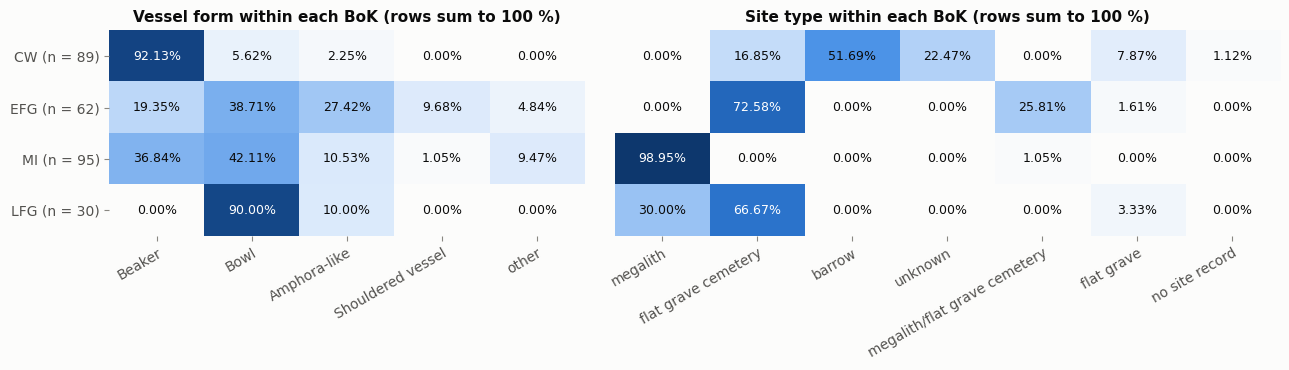

other forms: Collared flask 3, Jug 3, Bucket shape 3, Misc 2, Biberon 1
vessels per site type: megalith 103, flat grave cemetery 80, barrow 46, unknown 20, megalith/flat grave cemetery 17, flat grave 9, no site record 1


In [5]:
def shares(column, keep, missing):
    """Share of each category within each BoK, counting every vessel: categories outside `keep` are pooled
    as "other" and vessels without a value are shown as `missing`, so each row sums to 1."""
    x = df[column].fillna(missing)
    x = x.where(x.isin(keep + [missing]), "other")
    n = pd.crosstab(df["bok"], x).reindex(BOKS)
    n = n[[c for c in keep + ["other", missing] if c in n.columns]]
    return n.div(n.sum(axis=1), axis=0), n

forms = df["vessel_type"].value_counts().index[:4].tolist()        # the four commonest forms; the rest is "other"
sites = df["site_type"].value_counts().index.tolist()               # every site type, "unknown" included
vt, vt_n = shares("vessel_type", forms, "no record")
st, st_n = shares("site_type", sites, "no site record")
assert np.allclose(vt.sum(axis=1), 1) and np.allclose(st.sum(axis=1), 1) and vt_n.values.sum() == st_n.values.sum() == len(df)

rows = [f"{b} (n = {k})" for b, k in vt_n.sum(axis=1).items()]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
pl.heatmap(axes[0], vt.values, rows, vt.columns, fmt="{:.2%}", vmin=0, vmax=1)
axes[0].set_title("Vessel form within each BoK (rows sum to 100 %)")
pl.heatmap(axes[1], st.values, [""] * len(rows), st.columns, fmt="{:.2%}", vmin=0, vmax=1)
axes[1].set_title("Site type within each BoK (rows sum to 100 %)"); axes[1].tick_params(axis="y", left=False)
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")
fig.tight_layout(); pl.save(fig, "confounders"); plt.show()
other = df["vessel_type"][~df["vessel_type"].isin(forms)].value_counts()
print("other forms:", ", ".join(f"{f} {k}" for f, k in other.items()))
print("vessels per site type:", ", ".join(f"{s} {k}" for s, k in st_n.sum(axis=0).items()))

Every vessel is counted, so each row sums to 100 %.
- *Form:* 92 % of CW vessels are beakers and 90 % of late-FBW vessels are bowls. Early and middle FBW mix bowls (39 %, 42 %), beakers (19 %, 37 %) and amphora-like vessels (27 %, 11 %). "Other" pools five rare forms: 12 vessels (collared flask, jug and bucket shape 3 each, misc 2, biberon 1), 9 of them middle FBW.
- *Context:* 94 of the 95 middle-FBW vessels come from megaliths. CW comes from barrows (46), flat graves and flat-grave cemeteries (22) and "unknown" sites (20); early and late FBW come mostly from flat-grave cemeteries.
- *"Unknown"* is Kroon's own label (Appendix B): 20 CW vessels from 15 sites, kept in museum collections (inventory numbers from 1880 to 1962) without a recorded find context.
- *"No site record"* is vessel 79 (CW, context "Graf VII no 3"): its site 39 is missing from Kroon's site table and from the rest of the DANS deposit.
- *Consequence:* form alone separates CW from late FBW, and context alone separates middle FBW from the rest. Every accuracy below must be compared with these one-variable baselines (7.3, 7.5).

- **Form:** a classifier can score by recognising *how beakers are made* rather than *who made them*.
- **Context:** phase and burial context cannot be separated.
- **Clustering:** early and late FBW come from only 8 and 7 sites; vessels of one cemetery are not independent draws, so evaluation must hold out **whole sites**.

### 1.4 Where the vessels come from
Find spots from Kroon's site table (Appendix B): one marker per location and BoK, colour and shape by BoK, marker area proportional to the number of vessels. Open markers flag positions that the source marks as approximate. Hover over a marker for the site(s), site type, vessel counts and forms. The map is interactive in Jupyter and VS Code; static viewers such as GitHub's do not display it.

CW vessels come from many sites in Drenthe and Gelderland; the FBW phases come from few sites — the middle phase almost only from megaliths in Drenthe — the clustering by site noted in 1.3.

In [6]:
import plotly.graph_objects as go

geo = df.dropna(subset=["longitude", "latitude"])
approximate = geo["approximate_position"].astype(str).str.lower().eq("true")
SYMBOL = {"CW": "circle", "EFG": "square", "MI": "triangle-up", "LFG": "diamond"}

hover, approx_at = {}, {}                         # one description per location (sites may share coordinates)
for (lon, lat), g in geo.groupby(["longitude", "latitude"]):
    sites = "<br>".join(sorted({f"{n} (site {i})" for n, i in zip(g["site_name"], g["site_id"])}))
    counts = g["bok"].astype(str).value_counts().reindex(BOKS).dropna().astype(int)
    forms = g["vessel_type"].value_counts()
    approx_at[(lon, lat)] = bool(approximate[g.index].any())
    hover[(lon, lat)] = (f"<b>{sites}</b><br>{g['region'].iloc[0]} · {', '.join(sorted(g['site_type'].unique()))}"
                         f"<br>vessels: {' · '.join(f'{b} {k}' for b, k in counts.items())}"
                         f"<br>forms: {', '.join(f'{f} {k}' for f, k in forms.items())}"
                         f"<br>{lat:.3f}° N, {lon:.3f}° E ({'approximate' if approx_at[(lon, lat)] else 'exact'} position)")

points = geo.groupby(["longitude", "latitude", "bok"], observed=True).size().rename("n").reset_index()
points["approx"] = [approx_at[k] for k in zip(points["longitude"], points["latitude"])]
points["hover"] = [hover[k] for k in zip(points["longitude"], points["latitude"])]

fig = go.Figure()
for b in BOKS:
    for is_approx in (False, True):
        q = points[(points["bok"] == b) & (points["approx"] == is_approx)].sort_values("n", ascending=False)
        fig.add_trace(go.Scattergeo(
            lon=q["longitude"], lat=q["latitude"], mode="markers", name=pl.label(b),
            legendgroup=b, showlegend=not is_approx, text=q["hover"], customdata=q["n"],
            hovertemplate="%{text}<extra>" + b + ": %{customdata} vessels</extra>",
            marker=dict(size=7 * np.sqrt(q["n"]), color=pl.COLORS[b], opacity=0.85,
                        symbol=SYMBOL[b] + ("-open" if is_approx else ""),
                        line=dict(width=1.8 if is_approx else 0.8, color=pl.COLORS[b] if is_approx else "white"))))
fig.add_trace(go.Scattergeo(lon=[None], lat=[None], mode="markers", name="open marker: approximate position",
                            marker=dict(symbol="circle-open", size=10, color=pl.INK["muted"], line=dict(width=1.8))))
fig.update_geos(projection_type="mercator", resolution=50, lonaxis_range=[4.9, 7.4], lataxis_range=[51.8, 53.5],
                showland=True, landcolor="#f0efec", showocean=True, oceancolor="#e3edf7", showlakes=True,
                lakecolor="#e3edf7", showrivers=True, rivercolor="#c9dcef", showcountries=True,
                countrycolor=pl.INK["muted"], coastlinecolor=pl.INK["muted"], showframe=False)
fig.update_layout(height=680, margin=dict(l=0, r=0, t=50, b=70), paper_bgcolor=pl.INK["surface"],
                  font=dict(color=pl.INK["secondary"]),
                  legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.02, yanchor="top"),
                  title=dict(text=f"Find spots of {len(geo)} vessels at {geo.groupby(['longitude', 'latitude']).ngroups} locations",
                             font=dict(color=pl.INK["primary"])))
fig.show(renderer="plotly_mimetype+notebook_connected")
missing = df[df["longitude"].isna()]
print(f"{geo['site_id'].nunique()} sites, {int(approximate.groupby(geo['site_id']).first().sum())} with approximate positions; "
      f"not shown (no coordinates): vessels {', '.join(missing['vessel_id'])} (sites {', '.join(missing['site_id'])})")

85 sites, 41 with approximate positions; not shown (no coordinates): vessels 54, 79, 146 (sites 130, 39, 66)


**How to read it.** 273 of the 276 vessels have coordinates, at 85 of the 88 sites. CW vessels come from Drenthe (53) and Gelderland (28), mostly one barrow each. The FBW phases are concentrated in a few large cemeteries and megaliths in Drenthe and Overijssel. 41 positions are approximate (open markers), so read the map at the scale of tens of kilometres, not as distances between neighbouring sites.

## 2 · Representation: triplets as words

The legacy notebooks treat a chain as a bag of **triplets**, sliding windows of three consecutive steps (exactly the `clustered_paths_*.csv` files; `tests/test_core.py` checks the equality).

In [7]:
example = df["steps"].iloc[0]
print(" > ".join(example))
for g in data.ngrams(example, 3):
    print("   ", data.token(g))
bags = df.drop_duplicates("chain")["steps"].map(lambda s: tuple(sorted(data.ngrams(s, 3))))
print(f"\n{bags.nunique()} distinct triplet bags for {len(bags)} distinct chains")

Wet clay > Modelling > Coiling > Pressure > Scraping > Wet smoothing > Simple incision > Leather-hard > Dry > Open firing
    (Wet clay, Modelling, Coiling)
    (Modelling, Coiling, Pressure)
    (Coiling, Pressure, Scraping)
    (Pressure, Scraping, Wet smoothing)
    (Scraping, Wet smoothing, Simple incision)
    (Wet smoothing, Simple incision, Leather-hard)
    (Simple incision, Leather-hard, Dry)
    (Leather-hard, Dry, Open firing)

101 distinct triplet bags for 101 distinct chains


A bag of triplets determines the chain here (the triplets overlap like the pieces of a de Bruijn path), so little order is lost. The price is statistical: every interior step appears in up to **three** triplets, so the words of a document are strongly dependent. Models that treat them as independent evidence (LDA, naive Bayes, the SBM classifiers) count each step about three times and tend to be **over-confident** — checked with calibration metrics throughout. Section 9 repeats the analysis with n-grams of every length.

## 3 · One protocol for every model

The legacy notebook fitted its models on (almost) all vessels and then classified the same vessels. With 276 vessels from 88 sites, *how* the data are split matters more than which model is used. Write the data as $\mathcal D=\{(x_i,c_i,s_i)\}_{i=1}^{276}$: chain, BoK, site.

1. **Split by site.** Vessels of one site share potters, burial customs and recording, so a test vessel must have no site-mates in training.
   - The 88 sites are dealt into $K$ folds $F_1,\dots,F_K$ (`StratifiedGroupKFold`). Each fold is a set of *whole sites* and holds about $1/K$ of every BoK's vessels.
   - The **test sample** of fold $f$ is $\mathcal D_f=\{i: s_i\in F_f\}$, the vessels of its held-out sites. The training sample is $\mathcal T_f=\mathcal D\setminus\mathcal D_f$.
2. **Learn everything on $\mathcal T_f$ only:** vocabulary, stop triplets, pseudo-documents, topics and partitions, priors. The test vessels are only scored.
3. **Bootstrap inside each BoK, balanced.** Let $\mathcal T_{f,c}$ be the $n_c$ training vessels of BoK $c$. Pseudo-document $j=1,\dots,100$ of BoK $c$ concatenates the triplets of $g$ vessels drawn uniformly *with replacement* from $\mathcal T_{f,c}$:
$$\tilde d_{c,j}=x_{i_1}\oplus\dots\oplus x_{i_g},\qquad i_1,\dots,i_g\overset{\text{iid}}{\sim}\mathrm{Unif}(\mathcal T_{f,c}).$$
   Every BoK gets the same number of pseudo-documents (100), whatever $n_c$. Each training vessel therefore appears $100g/n_c$ times on average: at $g=7$, about 10 times for CW and middle FBW and 26 times for late FBW. Test vessels are never pooled; each enters alone, by fold-in.
4. **Score the test vessels**, $p(c\mid x_i)$ for $i\in\mathcal D_f$.

**One split to show the steps, cross-validation for the numbers.**
- Sections 4–6 run steps 1–4 on one fold of a 5-fold split (fold 1, seed 0), i.e. an 80/20 split: 224 training vessels from 71 sites, and 52 test vessels from the 17 held-out sites.
- Sections 7–10 *cross-validate* with $K=5$ folds (`N_FOLDS` in the setup cell). Every fold is the test sample once, so each vessel is predicted exactly once by a model that never saw its site. Three seeds (new folds, pseudo-documents and samplers) give 3 × 276 = 828 predictions; these are the numbers that count.
- For comparison, Section 7 also holds out single vessels instead of sites, and the topic models are also scored **in-sample**, as in the legacy notebook.

Every score goes into one registry `R`, always with the same metrics (explained below the split).

In [8]:
train_idx, test_idx = ev.splits(df, "site", 5, SEED)[0]
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
y_train, y_test = train_df["bok"].astype(str).to_numpy(), test_df["bok"].astype(str).to_numpy()
R = ev.Results()
pd.DataFrame({"training": train_df["bok"].value_counts().reindex(BOKS),
              "held-out sites": test_df["bok"].value_counts().reindex(BOKS)}).T.assign(
    sites=[train_df["site_id"].nunique(), test_df["site_id"].nunique()])

bok,CW,EFG,MI,LFG,sites
training,71,52,74,27,71
held-out sites,18,10,21,3,17


These are the vessels of each BoK in the training part and in the held-out sites of the single split used in Sections 4–6; the last column counts sites. Only 3 late-FBW vessels are held out, so per-class results on this split are anecdotal. The numbers that count are the cross-validated ones of Section 7.

**How to read the scores** (every table from here on). Each model gives each vessel a probability for each of the four BoKs.

| score | what it measures | reference values |
|---|---|---|
| accuracy | share of vessels whose most probable BoK is the true one | majority rule 0.34; chain-only ceiling 0.73 |
| balanced accuracy | mean over BoKs of the share of that BoK's vessels classified correctly; small BoKs count as much as large ones | any one-BoK rule 0.25 |
| macro-F1 | mean over BoKs of F1, the harmonic mean of precision and recall | majority rule 0.13 |
| log-loss | mean of $-\ln p(\text{true BoK})$; confident mistakes cost the most | uniform guess $\ln4=1.39$; class proportions ≈ 1.31–1.33 |
| Brier | mean squared distance between the probability vector and the one-hot truth | uniform guess 0.75 |
| ECE | predictions binned by confidence (10 bins); weighted mean of $\lvert$accuracy − confidence$\rvert$ | 0 = the probabilities mean what they say |

- $n$ counts predictions: in cross-validation 276 vessels × 3 seeds = 828.
- **Why more than accuracy?** Accuracy only counts how often the top choice is right. It ignores how sure the model was (a right answer at 30 % counts like one at 99 %), and large BoKs dominate it. Log-loss and the reliability diagram (7.3) judge the probabilities; balanced accuracy weighs every BoK equally.
- **Noise.** Resampling whole sites, one cross-validated accuracy is uncertain by about ± 0.04–0.05, and so is a difference between two models (computed in 7.3). Changing the seed moves accuracies by only ≈ 0.01, so the seeds are not the relevant uncertainty.

## 4 · Topic model I: LDA, replicated step by step

**Model** (Blei et al. 2003): documents $d$ (vessels), words $w$ (triplets), $K$ topics,
$$\theta_d\sim\mathrm{Dir}(\alpha),\quad \phi_k\sim\mathrm{Dir}(\beta),\quad z_{dn}\sim\mathrm{Cat}(\theta_d),\quad w_{dn}\sim\mathrm{Cat}(\phi_{z_{dn}}),$$
fitted by collapsed Gibbs sampling, $p(z=k\mid\cdot)\propto(n_{dk}+\alpha)\,\frac{n_{kw}+\beta}{n_k+V\beta}$.

Each step calls the function of the legacy notebook with the same name (`src/chaine/topic_model.py`); every docstring states what was checked and what was corrected. Legacy settings are kept — pseudo-documents of $g=7$ vessels (the legacy variable `resampled_5` actually used `group_size=7`), 100 per culture, $K=4$, $\alpha=\beta=1$, 200 Gibbs iterations — with one exception. The legacy notebook deleted the 5 most frequent triplets as "stop words"; here **every triplet is kept**. The switch is `STOP_K` in the setup cell (marked with `#`): `STOP_K = 0` keeps every triplet, `STOP_K = 5` restores the legacy corpus. 4.1 shows that the five carry information, and 7.4 that deleting them does not change accuracy beyond noise.

### 4.1 Documents, vocabulary and stop triplets

In [9]:
all_docs = tm.load_pottery_data(df)                                     # legacy cell 2
train_docs = [all_docs[i] for i in train_idx]
test_docs = [all_docs[i] for i in test_idx]
vocab_full, _ = tm.extract_vocabulary(train_docs)                       # legacy cell 2
train_c, removed = tm.remove_common_triplets(train_docs, k=STOP_K)      # legacy cell 3; STOP_K: setup cell
test_c, _ = tm.remove_common_triplets(test_docs, k=STOP_K, fit_docs=train_docs)
vocabulary, _ = tm.extract_vocabulary(train_c)
vocab_index = {w: i for i, w in enumerate(vocabulary)}
legacy_stop = tm.remove_common_triplets(train_docs, k=5)[1]           # the legacy's 5 "stop" triplets, for reference
print(f"vocabulary: {len(vocab_full)} triplets; {len(removed)} removed (STOP_K = {STOP_K}), {len(vocabulary)} kept")
tm.stop_triplet_test(train_docs, legacy_stop, BOKS)                     # are the legacy stop triplets uninformative?

vocabulary: 93 triplets; 0 removed (STOP_K = 0), 93 kept


,chi2,p_value,share CW,share EFG,share MI,share LFG
triplet,,,,,,
"(Wet clay, Modelling, Coiling)",11.292,1.025e-02,0.972,0.923,0.811,0.926
"(Modelling, Coiling, Pressure)",11.292,1.025e-02,0.972,0.923,0.811,0.926
"(Burnishing, Dry, Open firing)",60.966,3.654e-13,0.324,0.827,0.824,0.926
"(Leather-hard, Burnishing, Dry)",63.003,1.341e-13,0.282,0.827,0.770,0.926
"(Coiling, Pressure, Wet smoothing)",10.579,1.423e-02,0.549,0.481,0.459,0.185


- *Shown:* the five most frequent triplets, which the legacy pipeline removes as "stop words". For each: the χ² statistic and p-value of the test "used equally often by all four BoKs", and the share of each BoK's training vessels that contain it.
- *Numbers:*
  - The two opening triplets (wet clay → modelling → coiling → pressure) are in 81–97 % of the vessels of every BoK. They carry almost no information: p = 0.01, but the shares differ by at most 16 points.
  - The two burnishing triplets are in 28–32 % of CW vessels and 77–93 % of FBW vessels (p ≈ 10⁻¹³), so they carry strong information.
  - The fifth triplet is rarer in late FBW (19 % against 46–55 %).
- *Consequence:* removing them throws away the best CW-vs-FBW signal among the five. In accuracy it makes no measurable difference (+0.01 ± 0.01, 7.4), because burnishing also appears in other triplets. Here they are kept (`STOP_K = 0`).

Here every triplet is kept (`STOP_K = 0`). A frequent triplet is not necessarily an uninformative one: the two burnishing triplets above are frequent *and* informative. So: what is the whole vocabulary, which triplets carry information about the BoK, and is it right to delete the others?

**Information of a triplet.** Let $Y_w\in\{0,1\}$ say whether a vessel contains triplet $w$. Its information about the BoK $C$ is the mutual information
$$I(Y_w;C)=\sum_{y\in\{0,1\}}\sum_{c}p(y,c)\,\log_2\frac{p(y,c)}{p(y)\,p(c)}\ \text{bits},\qquad 0\le I(Y_w;C)\le H(C)\approx1.9\ \text{bits},$$
estimated on the training vessels.
- With few vessels the estimate is biased upwards, and more so for rare triplets. We subtract its mean under 999 random relabellings of the vessels ("MI − chance").
- We test it with the permutation p-value, corrected for testing all triplets at once: the Benjamini–Hochberg $q$-value, with $q<0.05$ counted as informative.

whole vocabulary: 96 triplets in the 276 vessels, 93 of them in the training vessels; 3 occur only in held-out vessels (1.1% of the held-out tokens)


,triplets,tokens,stop_triplets
class,,,
informative (q < 0.05),27,1445,5
no evidence of information,20,349,0
too rare to judge (< 5 vessels),46,78,0


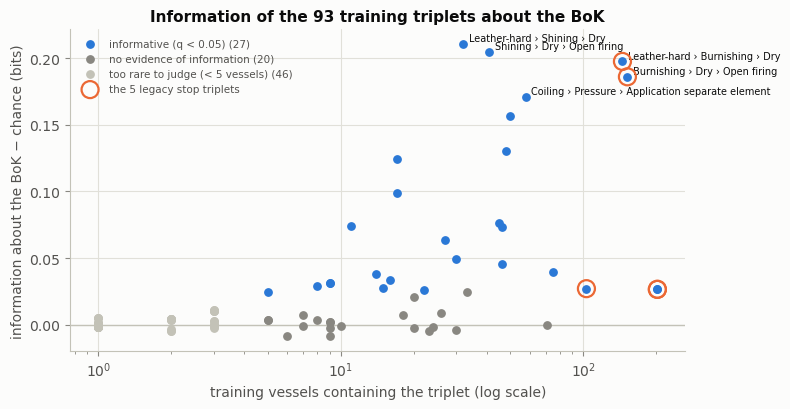

vessels  \
most informative     (Leather-hard, Shining, Dry)                                  32   
                     (Shining, Dry, Open firing)                                   41   
                     (Leather-hard, Burnishing, Dry)                              145   
                     (Burnishing, Dry, Open firing)                               152   
                     (Coiling, Pressure, Application separate element)             58   
                     (Pressure, Application separate element, Wet smoothing)       50   
legacy stop triplets (Burnishing, Dry, Open firing)                               152   
                     (Coiling, Pressure, Wet smoothing)                           103   
                     (Leather-hard, Burnishing, Dry)                              145   
                     (Modelling, Coiling, Pressure)                               202   
                     (Wet clay, Modelling, Coiling)                               202   

                                                                              MI (bits)  \
most informative     (Leather-hard, Shining, Dry)                                 0.221   
                     (Shining, Dry, Open firing)                                  0.215   
                     (Leather-hard, Burnishing, Dry)                              0.207   
                     (Burnishing, Dry, Open firing)                               0.196   
                     (Coiling, Pressure, Application separate element)            0.181   
                     (Pressure, Application separate element, Wet smoothing)      0.166   
legacy stop triplets (Burnishing, Dry, Open firing)                               0.196   
                     (Coiling, Pressure, Wet smoothing)                           0.037   
                     (Leather-hard, Burnishing, Dry)                              0.207   
                     (Modelling, Coiling, Pressure)                               0.037   
                     (Wet clay, Modelling, Coiling)                               0.037   

                                                                              MI − chance (bits)  \
most informative     (Leather-hard, Shining, Dry)                                          0.211   
                     (Shining, Dry, Open firing)                                           0.205   
                     (Leather-hard, Burnishing, Dry)                                       0.198   
                     (Burnishing, Dry, Open firing)                                        0.186   
                     (Coiling, Pressure, Application separate element)                     0.171   
                     (Pressure, Application separate element, Wet smoothing)               0.156   
legacy stop triplets (Burnishing, Dry, Open firing)                                        0.186   
                     (Coiling, Pressure, Wet smoothing)                                    0.027   
                     (Leather-hard, Burnishing, Dry)                                       0.198   
                     (Modelling, Coiling, Pressure)                                        0.027   
                     (Wet clay, Modelling, Coiling)                                        0.027   

                                                                                  q  \
most informative     (Leather-hard, Shining, Dry)                             0.006   
                     (Shining, Dry, Open firing)                              0.006   
                     (Leather-hard, Burnishing, Dry)                          0.006   
                     (Burnishing, Dry, Open firing)                           0.006   
                     (Coiling, Pressure, Application separate element)        0.006   
                     (Pressure, Application separate element, Wet smoothing)  0.006   
legacy stop triplets (Burnishing, Dry, Open firing)                           0.006   
                   

In [10]:
def triplet_information(docs, n_perm=999, seed=SEED):
    """For every triplet: in how many vessels it occurs, the mutual information (bits) between its presence and
    the BoK, that information minus its mean under random relabelling of the vessels (the small-sample bias),
    the permutation p-value, and the Benjamini–Hochberg q-value over all triplets."""
    words = sorted({t for d in docs for t in d["triplets"]})
    col = {w: j for j, w in enumerate(words)}
    Y = np.zeros((len(docs), len(words)))
    for i, d in enumerate(docs):
        Y[i, [col[t] for t in set(d["triplets"])]] = 1
    labels = np.array([BOKS.index(d["culture"]) for d in docs])

    def mi(lab):
        C = np.eye(len(BOKS))[lab]
        n11, n_c = Y.T @ C, C.sum(0)                                   # vessels with w in BoK c; vessels in BoK c
        joint = np.stack([n_c - n11, n11]) / len(lab)                  # p(absent/present, c), per triplet
        expected = joint.sum(2, keepdims=True) * (n_c / len(lab))      # p(absent/present) p(c)
        with np.errstate(divide="ignore", invalid="ignore"):
            return np.where(joint > 0, joint * np.log2(joint / expected), 0.0).sum((0, 2))

    obs = mi(labels)
    rng = np.random.default_rng(seed)
    null = np.array([mi(rng.permutation(labels)) for _ in range(n_perm)])
    p = (1 + (null >= obs).sum(0)) / (1 + n_perm)
    rank = np.argsort(p)
    q = np.empty_like(p)
    q[rank] = np.minimum.accumulate((p[rank] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    return pd.DataFrame({"vessels": Y.sum(0).astype(int), "MI (bits)": obs, "MI − chance (bits)": obs - null.mean(0),
                         "p": p, "q": np.minimum(q, 1)}, index=words)

whole = sorted({t for d in all_docs for t in d["triplets"]})
test_only = sorted(set(whole) - set(vocab_full))
unseen = np.mean([t not in set(vocab_full) for d in test_docs for t in d["triplets"]])
print(f"whole vocabulary: {len(whole)} triplets in the 276 vessels, {len(vocab_full)} of them in the training vessels; "
      f"{len(test_only)} occur only in held-out vessels ({unseen:.1%} of the held-out tokens)")

info = triplet_information(train_docs)
info["class"] = np.select([info["vessels"] < 5, info["q"] < 0.05],
                          ["too rare to judge (< 5 vessels)", "informative (q < 0.05)"], "no evidence of information")
info["legacy stop triplet"] = info.index.isin(legacy_stop)
display(info.groupby("class").agg(triplets=("vessels", "size"), tokens=("vessels", "sum"),
                                  stop_triplets=("legacy stop triplet", "sum")))

fig, ax = plt.subplots(figsize=(8, 4.2))
for cls, color in [("informative (q < 0.05)", pl.COLORS["CW"]), ("no evidence of information", pl.INK["muted"]),
                   ("too rare to judge (< 5 vessels)", pl.INK["axis"])]:
    s = info[info["class"] == cls]
    ax.scatter(s["vessels"], s["MI − chance (bits)"], s=28, color=color, label=f"{cls} ({len(s)})", zorder=3)
stop = info[info["legacy stop triplet"]]
ax.scatter(stop["vessels"], stop["MI − chance (bits)"], s=150, facecolors="none", edgecolors=pl.COLORS["EFG"],
           linewidths=1.6, label="the 5 legacy stop triplets", zorder=4)
for w, r in info.nlargest(5, "MI − chance (bits)").iterrows():
    ax.annotate(pl.short(w), (r["vessels"], r["MI − chance (bits)"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.axhline(0, color=pl.INK["axis"], lw=1); ax.set_xscale("log")
ax.set_xlabel("training vessels containing the triplet (log scale)"); ax.set_ylabel("information about the BoK − chance (bits)")
ax.set_title(f"Information of the {len(info)} training triplets about the BoK"); ax.legend(fontsize=7.5, loc="upper left")
fig.tight_layout(); plt.show()
info["rank"] = info["MI − chance (bits)"].rank(ascending=False).astype(int)
cols = ["vessels", "MI (bits)", "MI − chance (bits)", "q", "rank", "class"]
pd.concat({"most informative": info.nsmallest(6, "rank")[cols], "legacy stop triplets": stop.join(info["rank"])[cols]})

**How to read it.**
- *Whole vocabulary:* 96 distinct triplets in the 276 vessels. The models use the 93 that occur in training vessels. The 3 that occur only in held-out vessels make up 1.1 % of the held-out tokens. A model fitted without them knows nothing about them; adding them to the vocabulary would give them nearly the same smoothed probability under every topic, i.e. almost no effect (Lemma below).
- *Table:* the 93 training triplets fall into three classes:
  - informative ($q<0.05$): 27 triplets, carrying 1445 of the 1872 training tokens;
  - no evidence of information: 20 triplets (349 tokens);
  - too rare to judge (fewer than 5 vessels): 46 triplets (78 tokens).
- *Figure:* information against the number of vessels containing the triplet. The most informative triplets are the CW-vs-FBW contrasts: shining (0.21 bits), burnishing (0.20) and separately applied elements (0.17).
- *The legacy stop triplets are all informative.* The two burnishing triplets rank 3rd and 4th of 93. The other three rank 23rd–24th (0.03 bits): weak but real — for example, middle FBW opens with wet clay → modelling → coiling less often than the other BoKs. Frequency is not lack of information.

**Is it right to delete the less informative triplets?**

**Lemma (a word without information cancels).** If $p(w\mid c)$ is the same for every BoK (naive Bayes), or $\phi_k(w)$ is the same for every topic (LDA), deleting $w$ from a vessel does not change its attribution.

*Proof.*
- *Naive Bayes:* $p(c\mid x)\propto\pi_c\prod_n p(w_n\mid c)$. Each occurrence of $w$ multiplies every class by the same factor, which the normalisation removes.
- *LDA fold-in:* the topic mixture of a vessel with $N$ tokens is the fixed point of $\theta_k(N+K\alpha)=\sum_n r_{nk}+\alpha$, with responsibilities $r_{nk}=\theta_k\phi_k(w_n)/\sum_j\theta_j\phi_j(w_n)$. An occurrence of $w$ has $r_{nk}=\theta_k$: it adds $\theta_k$ to the right-hand side and, through $N$, $\theta_k$ to the left. The two cancel, so the fixed point is the same with or without $w$. $\square$

So deleting a triplet that truly carries no information is harmless at prediction time, and deleting an informative one throws evidence away. Deletion can still change the *fit*, because every topic must spend probability on frequent words. But "uninformative" is itself estimated from 224 vessels. The deletion must therefore be decided inside each training fold, and its value measured rather than assumed (7.4).

### 4.2 Bootstrap pseudo-documents and the document-term matrix
These are the pseudo-documents of Section 3, step 3: within each BoK, from the training vessels only, 100 per BoK, each pooling $g$ vessels drawn with replacement. Below, $g=3,7,15$; the legacy corpus is $g=7$.

In [11]:
resampled = {g: tm.create_resampled_documents(train_c, group_size=g, num_new_docs=100, seed=SEED)
             for g in [3, 7, 15]}                                       # legacy cell 5
tm.dataset_summary({"training vessels": train_c,
                    **{f"resampled, g = {g}": d for g, d in resampled.items()}}, vocab_index)   # legacy cell 6

,documents,vocabulary,non-zero entries,density,mean triplets / document,documents per culture
dataset,,,,,,
training vessels,224,93,1872,0.090,8.357,"{'CW': 71, 'EFG': 52, 'MI': 74, 'LFG': 27}"
"resampled, g = 3",400,93,6138,0.165,24.840,"{'CW': 100, 'EFG': 100, 'MI': 100, 'LFG': 100}"
"resampled, g = 7",400,93,9303,0.250,58.025,"{'CW': 100, 'EFG': 100, 'MI': 100, 'LFG': 100}"
"resampled, g = 15",400,93,12578,0.338,124.280,"{'CW': 100, 'EFG': 100, 'MI': 100, 'LFG': 100}"


- *Shown:* the training vessels and the three bootstrap corpora (100 pseudo-documents per BoK, each pooling $g$ vessels of one BoK). Columns: number of documents, vocabulary size, non-zero entries of the document–term matrix, density, mean triplets per document, documents per BoK.
- *Numbers:* a real vessel has 8.4 triplets (density 0.09); a $g=7$ pseudo-document has 58 (density 0.25). Pooling makes documents look rich, but the vocabulary stays at 93: no triplet is created, only repeated.
- *Caveat:* the BoK sizes 71, 52, 74 and 27 all become 100. Each late-FBW vessel is copied about 26 times, each CW or middle-FBW vessel about 10 times (7.1).

In [12]:
# can you write some samples of resampled documents for group_size=7 and group_size=25, and show the first 5 documents of each?
resampled_7 = tm.create_resampled_documents(train_c, group_size=7, num_new_docs=3, seed=SEED)
resampled_25 = tm.create_resampled_documents(train_c, group_size=25, num_new_docs=3, seed=SEED)

print("Resampled documents for group_size=7:")
for i, doc in enumerate(resampled_7):
    print(f"Document {i+1}: {doc}")

print("\nResampled documents for group_size=25:")
for i, doc in enumerate(resampled_25):
    print(f"Document {i+1}: {doc}")

Resampled documents for group_size=7:
Document 1: {'vessel_id': 'RESAMPLED_CW_1', 'original_vessels': ['314', '160', '142', '84', '86', '16', '50'], 'culture': 'CW', 'triplets': ['(Wet clay, Modelling, Coiling)', '(Modelling, Coiling, Pressure)', '(Coiling, Pressure, Wet smoothing)', '(Pressure, Wet smoothing, Simple incision)', '(Wet smoothing, Simple incision, Leather-hard)', '(Simple incision, Leather-hard, Dry)', '(Leather-hard, Dry, Open firing)', '(Wet clay, Modelling, Coiling)', '(Modelling, Coiling, Pressure)', '(Coiling, Pressure, Wet smoothing)', '(Pressure, Wet smoothing, Simple incision)', '(Wet smoothing, Simple incision, Simple impression)', '(Simple incision, Simple impression, Leather-hard)', '(Simple impression, Leather-hard, Shining)', '(Leather-hard, Shining, Dry)', '(Shining, Dry, Open firing)', '(Wet clay, Modelling, Coiling)', '(Modelling, Coiling, Pressure)', '(Coiling, Pressure, Wet smoothing)', '(Pressure, Wet smoothing, Simple incision)', '(Wet smoothing, Simp

**Reusable bootstrap corpora.** The next cell writes the pseudo-documents to `data/derived/`, with every triplet kept. The stop triplets are removed later, inside each model, so any `STOP_K` can be applied to these files.
- `pseudo_documents_training_split.csv`: the corpora of this section ($g=3,7,15$), built from the training vessels of the split of Section 3. They can be evaluated on its held-out sites.
- `pseudo_documents_all_vessels.csv`: the same construction ($g=7$) from all 276 vessels, like the legacy `bootstrap_documents_*.csv`. Use it for description only: no vessel is left to test on.

Columns: `source`, `g`, `seed`, `pseudo_document`, `bok`, `vessels` (the $g$ vessel IDs, `;`-separated, repeats possible), `n_triplets`, `triplets` (`|`-separated).

In [13]:
def pseudo_table(docs, source, g, seed):
    pdocs = tm.create_resampled_documents(docs, group_size=g, num_new_docs=100, seed=seed)
    return pd.DataFrame({"source": source, "g": g, "seed": seed, "pseudo_document": [d["vessel_id"] for d in pdocs],
                         "bok": [d["culture"] for d in pdocs], "vessels": [";".join(d["original_vessels"]) for d in pdocs],
                         "n_triplets": [d["num_triplets"] for d in pdocs], "triplets": [" | ".join(d["triplets"]) for d in pdocs]})

out_dir = ROOT / "data" / "derived"
out_dir.mkdir(exist_ok=True)
split_docs = pd.concat([pseudo_table(train_docs, "training vessels of the split of Section 3", g, SEED) for g in [3, 7, 15]])
all_vessel_docs = pseudo_table(all_docs, "all 276 vessels (description only)", 7, SEED)
split_docs.to_csv(out_dir / "pseudo_documents_training_split.csv", index=False)
all_vessel_docs.to_csv(out_dir / "pseudo_documents_all_vessels.csv", index=False)
# the same draws as the corpora above: only the stop triplets differ
assert all(split_docs.query("g == @g")["vessels"].tolist() == [";".join(d["original_vessels"]) for d in resampled[g]] for g in [3, 7, 15])
print(f"wrote {len(split_docs)} + {len(all_vessel_docs)} pseudo-documents to {out_dir.relative_to(ROOT)}/")
split_docs.head(3)

wrote 1200 + 400 pseudo-documents to data/derived/


,source,g,seed,pseudo_document,bok,vessels,n_triplets,triplets
0,training vessels of the split of Section 3,3,0,RESAMPLED_CW_1,CW,314;160;142,26,"(Wet clay, Modelling, Coiling) | (Modelling, Coiling, Pressure) | (Coiling, Pressure, Wet smoothing) | (Pr..."
1,training vessels of the split of Section 3,3,0,RESAMPLED_CW_2,CW,84;86;16,24,"(Wet clay, Modelling, Coiling) | (Modelling, Coiling, Pressure) | (Coiling, Pressure, Wet smoothing) | (Pr..."
2,training vessels of the split of Section 3,3,0,RESAMPLED_CW_3,CW,50;15;66,25,"(Wet clay, Modelling, Coiling) | (Modelling, Coiling, Pressure) | (Coiling, Pressure, Wet smoothing) | (Pr..."


In [14]:
corpus = resampled[7]                        # the corpus of Sections 4-6, for LDA and hSBM alike
corpus_culture = np.array([d["culture"] for d in corpus])
X, _ = tm.build_dtm_with_external_vocab(corpus, vocab_index)                        # legacy cell 6
lda_model = tm.LDA_manual(n_topics=4, alpha=1, beta=1, n_iter=200, random_state=SEED).fit(X, vocabulary)  # cells 14, 17
top = lda_model.get_top_words(vocabulary, n_words=4)
pd.DataFrame({f"topic {k}": [f"{pl.short(w)}  ({p:.2f})" for w, p in t] for k, t in enumerate(top)})

,topic 0,topic 1,topic 2,topic 3
0,Burnishing › Dry › Open firing (0.12),Modelling › Coiling › Pressure (0.12),Wet clay › Modelling › Coiling (0.11),Leather-hard › Burnishing › Dry (0.11)
1,Leather-hard › Burnishing › Dry (0.12),Wet clay › Modelling › Coiling (0.11),Modelling › Coiling › Pressure (0.11),Burnishing › Dry › Open firing (0.10)
2,Wet clay › Modelling › Coiling (0.11),Burnishing › Dry › Open firing (0.11),Shining › Dry › Open firing (0.07),Modelling › Coiling › Pressure (0.09)
3,Modelling › Coiling › Pressure (0.11),Leather-hard › Burnishing › Dry (0.10),Coiling › Pressure › Wet smoothing (0.06),Wet clay › Modelling › Coiling (0.09)


**How to read it.**
- *Shown:* for each LDA topic, its four most probable triplets with $\phi_k(w)$, the probability of the triplet under the topic.
- *Numbers:* with every triplet kept, the opening steps (wet clay → modelling → coiling → pressure, $\phi\approx0.09$–$0.12$) are among the top four of *every* topic: they occur in almost every vessel. Burnishing (leather-hard → burnishing → dry → open firing) tops the three FBW topics; the CW topic (topic 2, by the matching of 4.3) has shining → dry → open firing instead.
- *Why the legacy notebook deleted them:* frequent triplets fill the top-word lists of every topic. That is a problem of *display*, not of the model; the information is in the rest of the list.
- *Caveat:* top words show what is frequent in a topic, not what distinguishes it. The heatmap of 4.3 sorts every triplet by the topic in which it is most probable; there each topic has a clear signature.

### 4.3 Which topic is which culture?
The legacy notebook compared each topic $\phi_k$ with each culture's empirical triplet distribution by the Jensen–Shannon (JS) divergence, gave each culture its closest topic (`matching_empirical`), and overlaid the two distributions (cell 18; reproduced below over the full vocabulary). Done independently per culture, two cultures can claim the same topic; the corrected version finds the best **one-to-one** assignment (Hungarian algorithm).

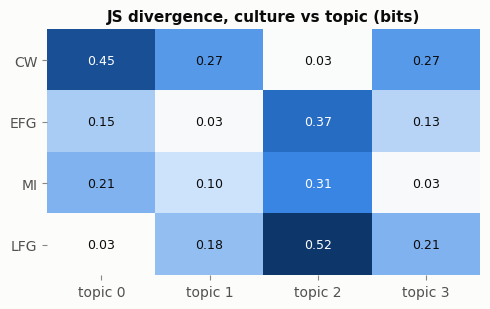

legacy argmin mapping : {'CW': 2, 'EFG': 1, 'MI': 3, 'LFG': 0}
one-to-one mapping    : {'CW': 2, 'EFG': 1, 'MI': 3, 'LFG': 0}


In [15]:
empirical = tm.get_empirical_word_distribution(train_c, vocabulary, BOKS)
legacy_map, J = tm.matching_empirical(empirical, lda_model.topic_word_dist, BOKS, one_to_one=False)  # cell 24
culture_mapping, _ = tm.matching_empirical(empirical, lda_model.topic_word_dist, BOKS)
fig, ax = plt.subplots(figsize=(5, 3.2))
pl.heatmap(ax, J, BOKS, [f"topic {k}" for k in range(4)], fmt="{:.2f}")
ax.set_title("JS divergence, culture vs topic (bits)")
fig.tight_layout(); plt.show()
print("legacy argmin mapping :", legacy_map)
print("one-to-one mapping    :", culture_mapping)


- *Heatmap:* the Jensen–Shannon divergence (bits) between each culture's empirical triplet distribution (rows) and each topic (columns). 0 means identical, 1 means no overlap.
- *Numbers:* each culture has one clearly closest topic, all at 0.03 bits: CW–topic 2, early FBW–topic 1, middle FBW–topic 3, late FBW–topic 0. The second-closest is at least 0.07 farther (middle FBW: 0.10, to the early-FBW topic). The legacy rule (closest topic per culture) and the one-to-one matching therefore give the same assignment.
- *Caveat:* the legacy rule can give two cultures the same topic (it did in the legacy run). Only one-to-one matching guarantees a classifier that can predict all four BoKs.

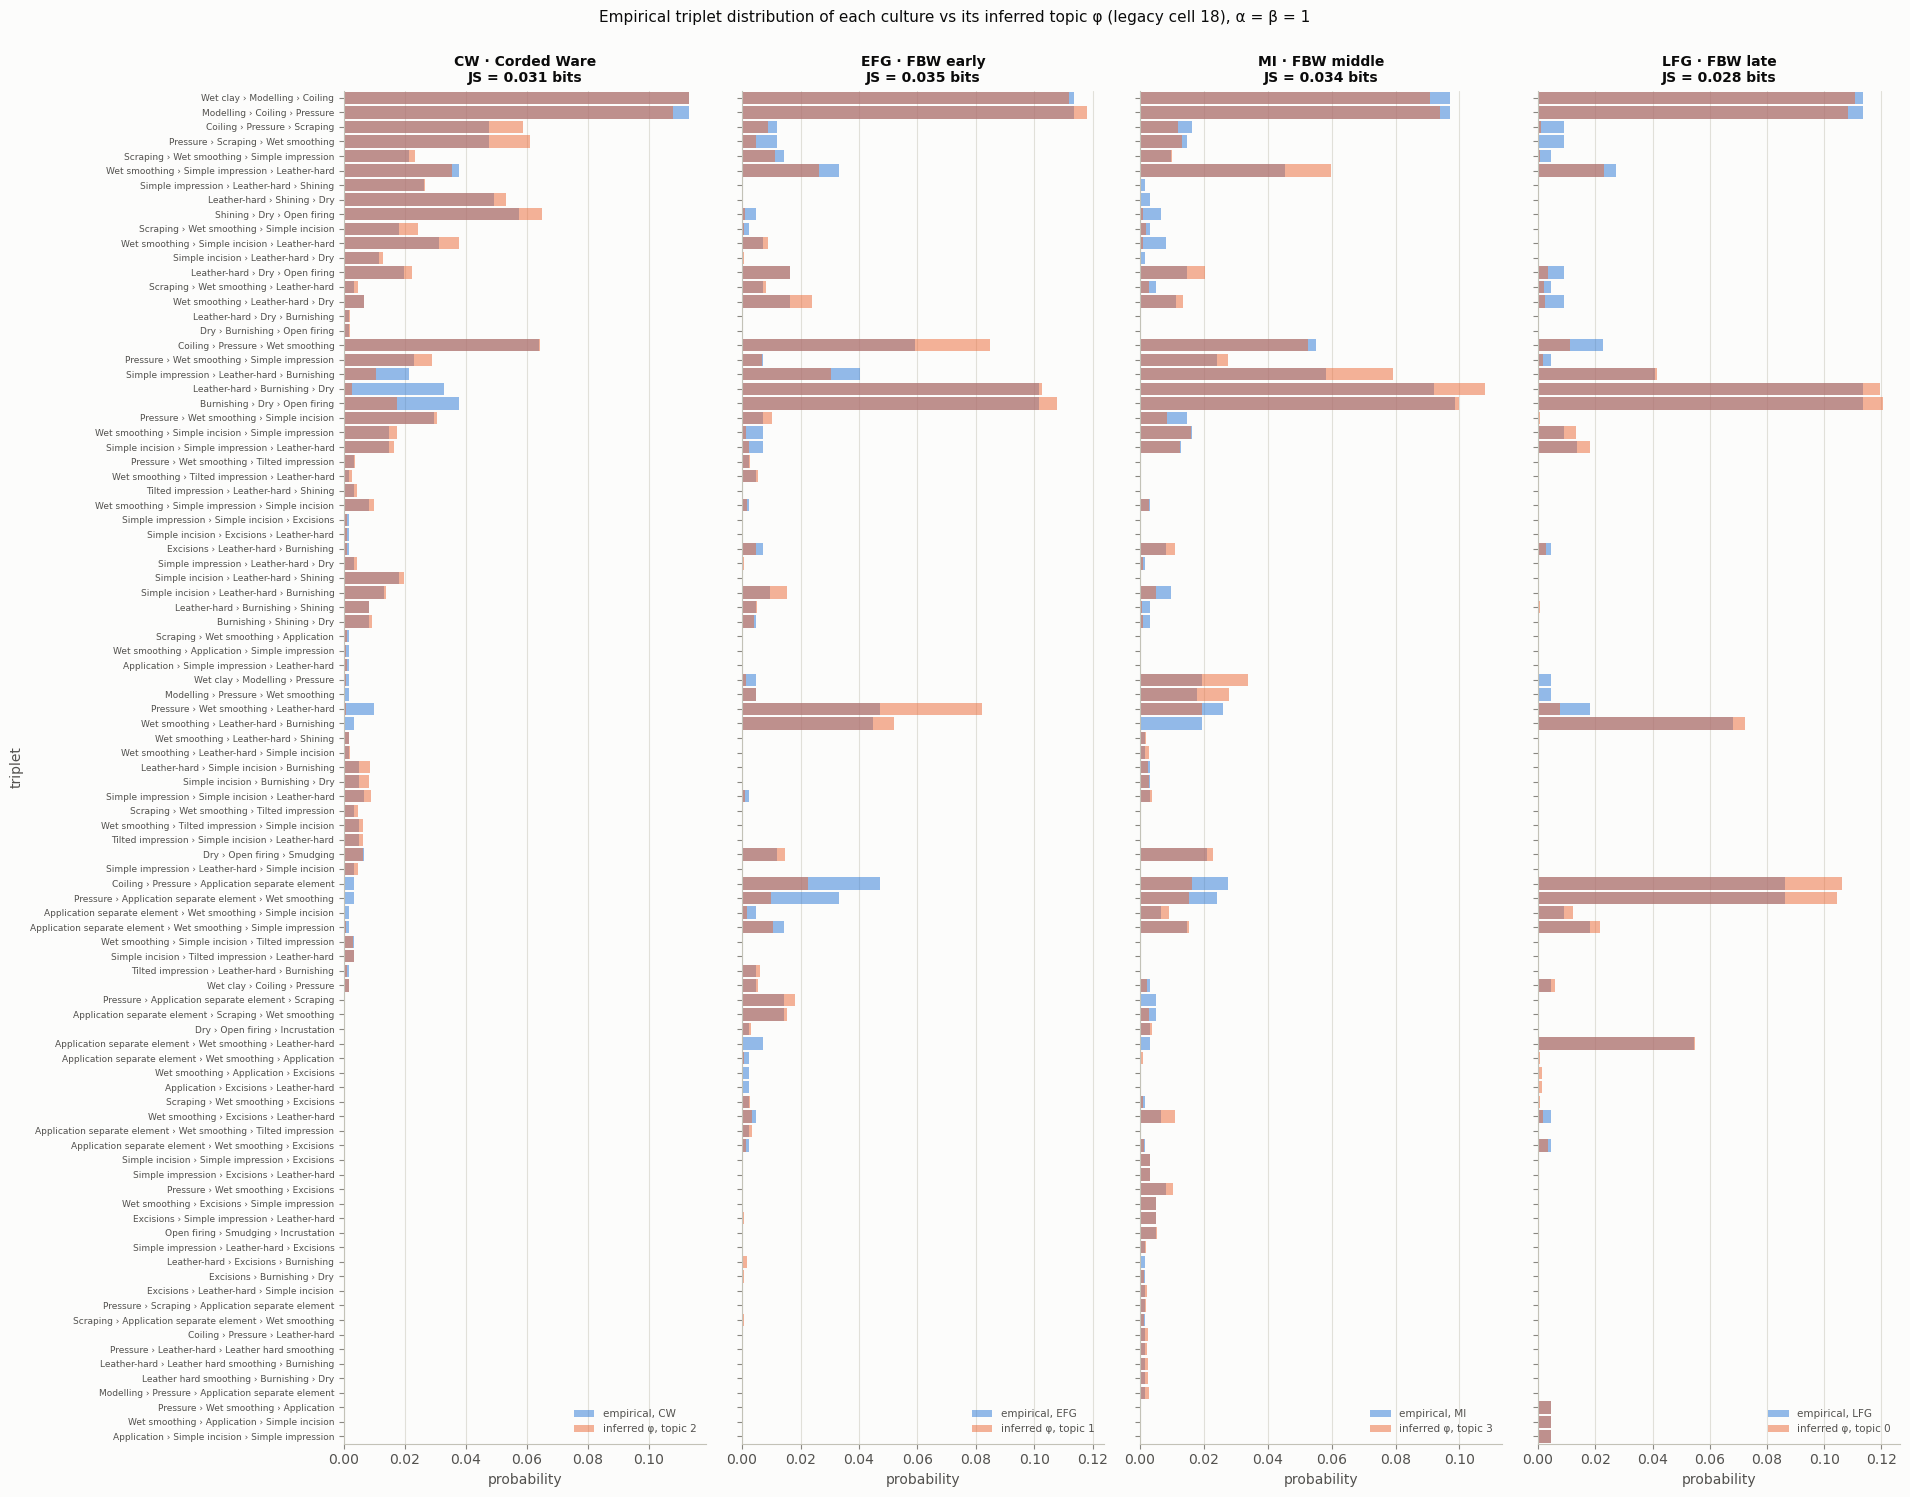

In [16]:
phi_matched = lda_model.topic_word_dist[[culture_mapping[c] for c in BOKS]]
js_matched = [tm.js_divergence(e, m) for e, m in zip(empirical, phi_matched)]
fig = overlay_distributions(empirical, phi_matched, vocabulary, BOKS,
                            [f"inferred φ, topic {culture_mapping[c]}" for c in BOKS],
                            "Empirical triplet distribution of each culture vs its inferred topic φ (legacy cell 18), α = β = 1",
                            js=js_matched)
plt.show()

**Topic–triplet matrix $\phi$** (the legacy `p_w_tw` heatmap).
- Columns: the four topics, each labelled with the BoK it was matched to.
- Rows: the triplets, grouped by the topic in which each is most probable, $\arg\max_k\phi_k(w)$ (marked •), and sorted within each group by that probability.
- Colour: $\phi_k(w)=p(\text{triplet }w\mid\text{topic }k)$; each column sums to 1.

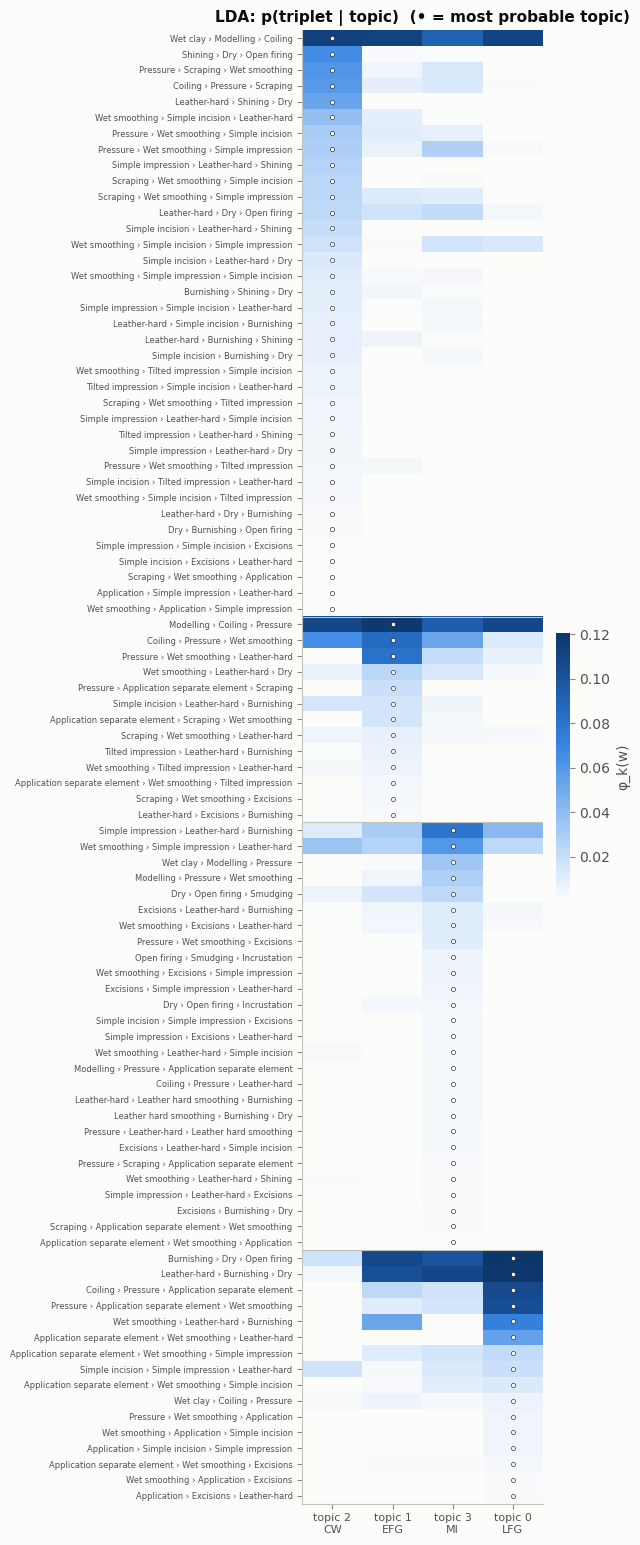

triplets most probable under the topic of {'CW': 37, 'EFG': 13, 'MI': 27, 'LFG': 16}


In [17]:
phi = lda_model.topic_word_dist                                    # K × V, each row sums to 1
cols = [culture_mapping[c] for c in BOKS]                          # topics in the order CW, EFG, MI, LFG
M = phi[cols].T                                                    # triplets × topics
best = M.argmax(1)                                                 # most probable topic of each triplet
rows = np.lexsort((-M.max(1), best))                               # grouped by that topic, most probable first
fig, ax = plt.subplots(figsize=(6.5, 0.15 * len(rows) + 1.6))
im = ax.imshow(M[rows], aspect="auto", cmap=pl.SEQ, interpolation="none")
ax.scatter(best[rows], np.arange(len(rows)), s=9, color="white", edgecolors=pl.INK["primary"], linewidths=0.4, zorder=3)
for b in np.flatnonzero(np.diff(best[rows])):
    ax.axhline(b + 0.5, color=pl.INK["axis"], lw=0.8)
ax.set_xticks(range(len(BOKS)), [f"topic {k}\n{c}" for c, k in zip(BOKS, cols)], fontsize=8)
ax.set_yticks(range(len(rows)), [pl.short(vocabulary[j]) for j in rows], fontsize=6)
ax.grid(False); ax.set_title("LDA: p(triplet | topic)  (• = most probable topic)")
fig.colorbar(im, ax=ax, fraction=0.05, label="φ_k(w)").outline.set_visible(False)
fig.tight_layout(); plt.show()
print("triplets most probable under the topic of", dict(zip(BOKS, np.bincount(best, minlength=len(BOKS)).tolist())))

**Reading.** Of the 93 triplets, 37 are most probable under the CW topic, 27 under middle FBW, 16 under late FBW and 13 under early FBW.
- Each topic is carried by a few triplets:
  - CW: shining and scraping;
  - early FBW: pressure → wet smoothing → leather-hard, and drying without surface treatment;
  - middle FBW: simple impression → burnishing, excisions, smudging;
  - late FBW: burnishing and separately applied elements.
- The opening triplets (top rows of the CW and early-FBW blocks) have weight in every column, and burnishing in all three FBW columns. The topics share triplets, and this overlap is what makes the FBW phases hard to tell apart (4.7).

One topic per culture fits every culture to within ≈ 0.03 bits. The fit is good; the topics are nevertheless close to each other, because the cultures share most techniques (4.7).

**The same LDA with α = 0.1 and β = 0.5**, one of the best-fitting settings of the grid in 4.6. A smaller α favours pseudo-documents dominated by a single topic; a smaller β favours topics concentrated on fewer triplets.

In [18]:
# USING DIFFERENT HYPERPARAMETERS (α = 0.1, β = 0.5) FOR LDA
corpus_mod_a_b = resampled[7]                        # the corpus of Sections 4-6, for LDA and hSBM alike
corpus_culture_mod_a_b = np.array([d["culture"] for d in corpus_mod_a_b])
X_mod_a_b, _ = tm.build_dtm_with_external_vocab(corpus_mod_a_b, vocab_index)                        # legacy cell 6
alph, bet = 0.1, 0.5
lda_model_mod_a_b = tm.LDA_manual(n_topics=4, alpha=alph, beta=bet, n_iter=200, random_state=SEED).fit(X_mod_a_b, vocabulary)  # cells 14, 17
top_mod_a_b = lda_model_mod_a_b.get_top_words(vocabulary, n_words=4)
pd.DataFrame({f"topic {k}": [f"{pl.short(w)}  ({p:.2f})" for w, p in t] for k, t in enumerate(top_mod_a_b)})

,topic 0,topic 1,topic 2,topic 3
0,Burnishing › Dry › Open firing (0.11),Wet clay › Modelling › Coiling (0.11),Burnishing › Dry › Open firing (0.10),Modelling › Coiling › Pressure (0.11)
1,Leather-hard › Burnishing › Dry (0.11),Modelling › Coiling › Pressure (0.11),Wet clay › Modelling › Coiling (0.09),Wet clay › Modelling › Coiling (0.11)
2,Modelling › Coiling › Pressure (0.11),Coiling › Pressure › Wet smoothing (0.07),Modelling › Coiling › Pressure (0.09),Leather-hard › Burnishing › Dry (0.11)
3,Wet clay › Modelling › Coiling (0.11),Shining › Dry › Open firing (0.06),Leather-hard › Burnishing › Dry (0.09),Burnishing › Dry › Open firing (0.10)


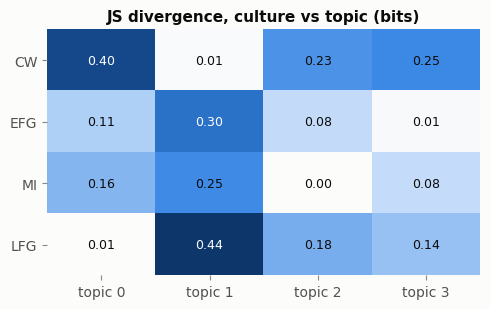

legacy argmin mapping : {'CW': 1, 'EFG': 3, 'MI': 2, 'LFG': 0}
one-to-one mapping    : {'CW': 1, 'EFG': 3, 'MI': 2, 'LFG': 0}


In [19]:
empirical_mod_a_b = tm.get_empirical_word_distribution(train_c, vocabulary, BOKS)
legacy_map_mod_a_b, J_mod_a_b = tm.matching_empirical(empirical_mod_a_b, lda_model_mod_a_b.topic_word_dist, BOKS, one_to_one=False)  # cell 24
culture_mapping_mod_a_b, _ = tm.matching_empirical(empirical_mod_a_b, lda_model_mod_a_b.topic_word_dist, BOKS)
fig, ax = plt.subplots(figsize=(5, 3.2))
pl.heatmap(ax, J_mod_a_b, BOKS, [f"topic {k}" for k in range(4)], fmt="{:.2f}")
ax.set_title("JS divergence, culture vs topic (bits)")
fig.tight_layout(); plt.show()
print("legacy argmin mapping :", legacy_map_mod_a_b)
print("one-to-one mapping    :", culture_mapping_mod_a_b)

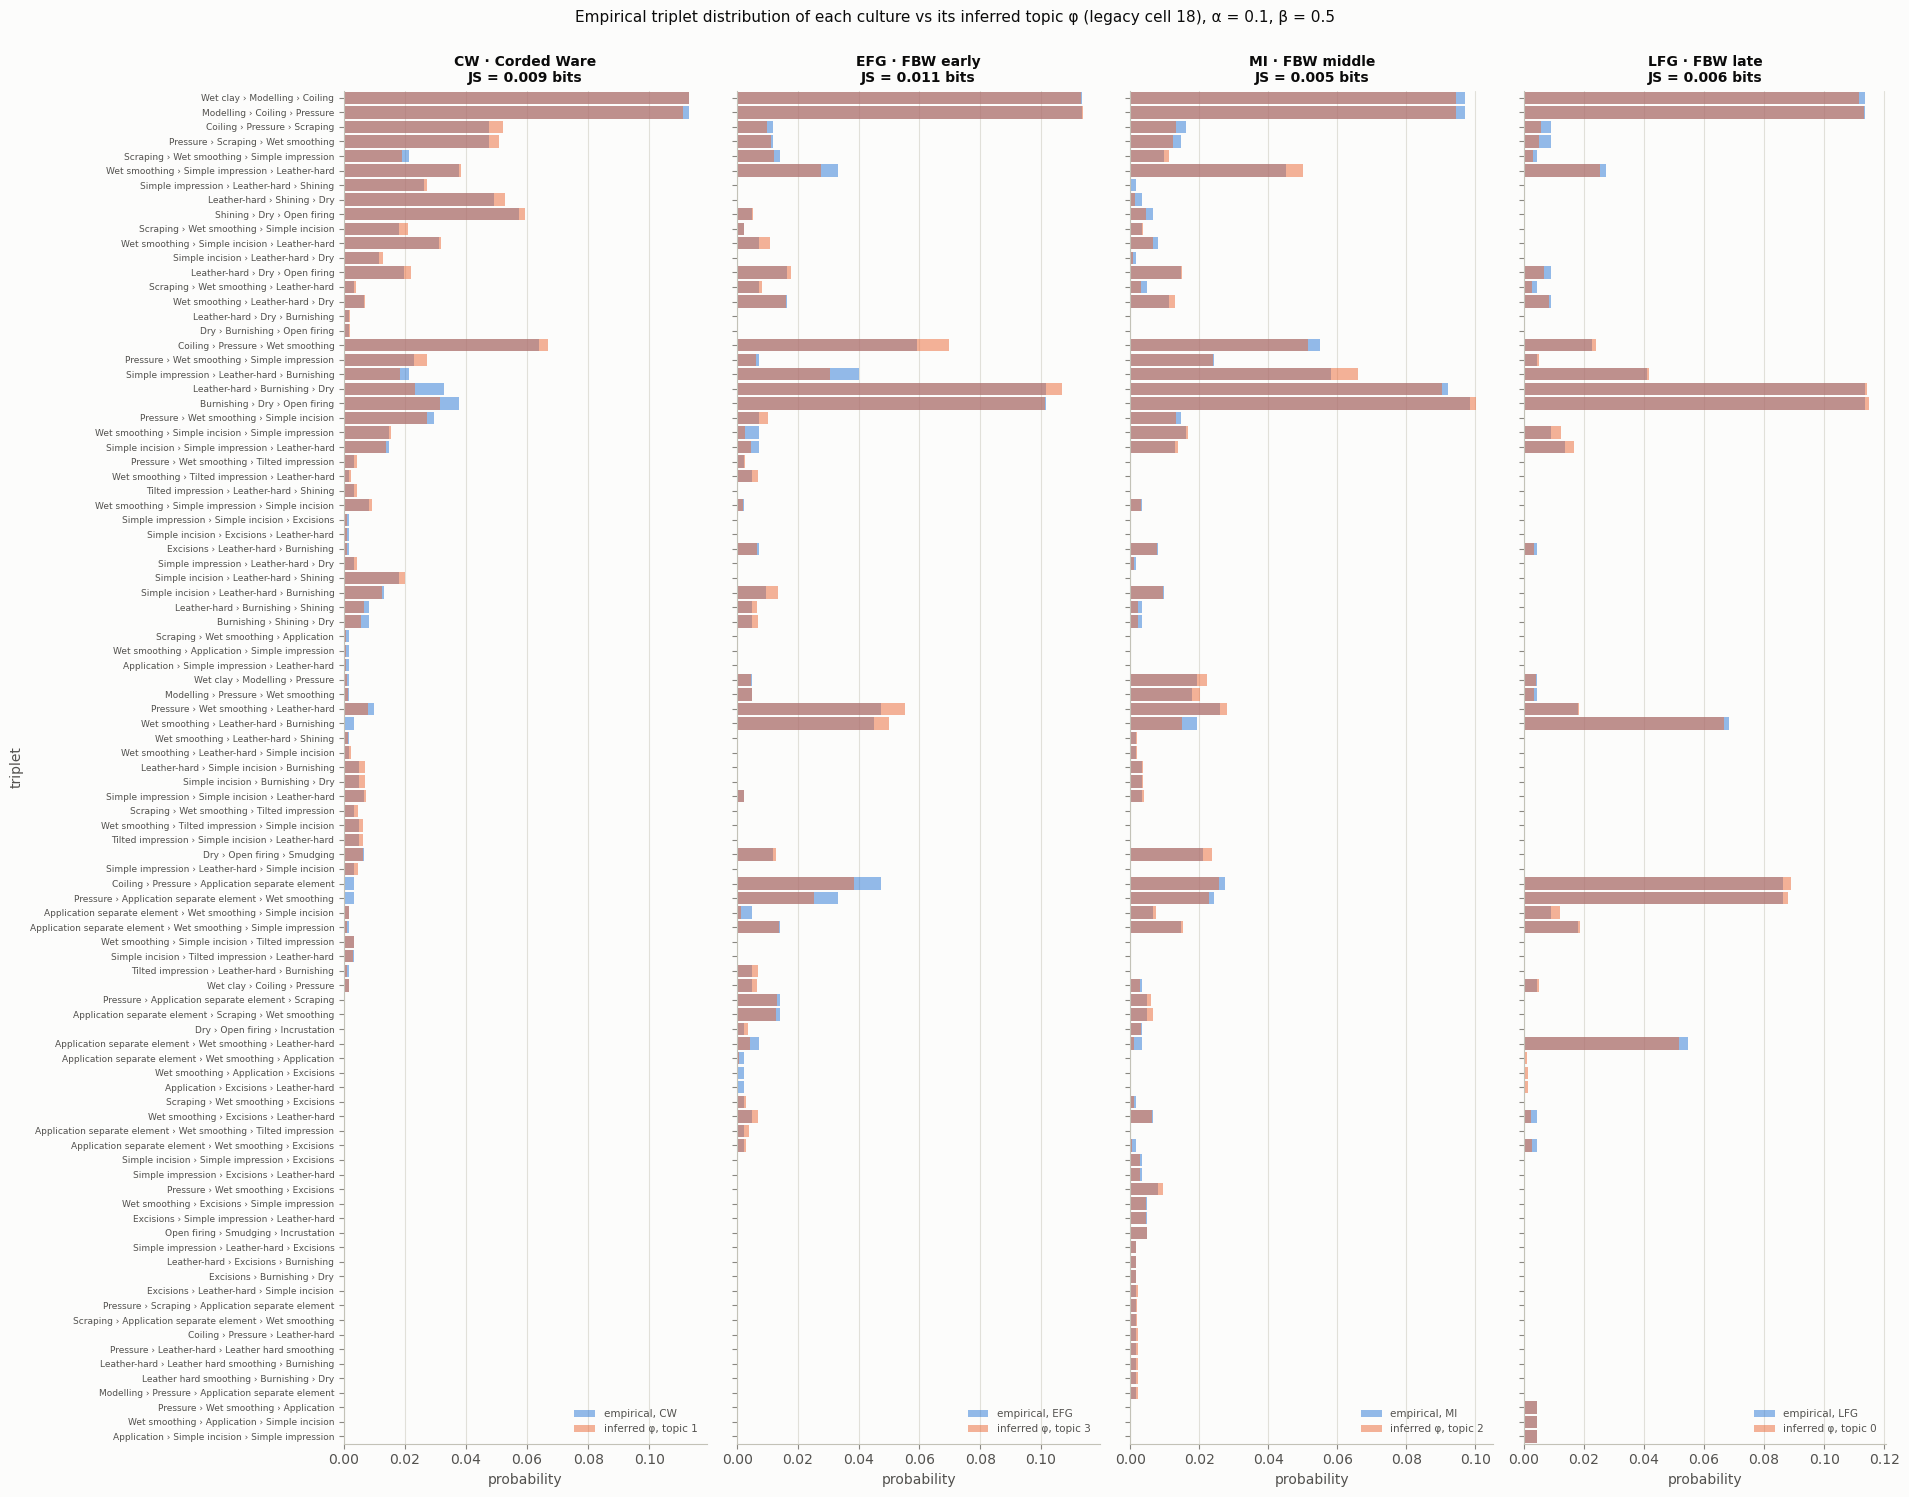

In [20]:
phi_matched_mod_a_b = lda_model_mod_a_b.topic_word_dist[[culture_mapping_mod_a_b[c] for c in BOKS]]
js_matched_mod_a_b = [tm.js_divergence(e, m) for e, m in zip(empirical_mod_a_b, phi_matched_mod_a_b)]
fig = overlay_distributions(empirical_mod_a_b, phi_matched_mod_a_b, vocabulary, BOKS,
                            [f"inferred φ, topic {culture_mapping_mod_a_b[c]}" for c in BOKS],
                            f"Empirical triplet distribution of each culture vs its inferred topic φ (legacy cell 18), α = {alph}, β = {bet}",
                            js=js_matched_mod_a_b)
plt.show()

**How to read it.** The same corpus and matching as above, with α = 0.1 and β = 0.5 instead of α = β = 1.
- *Top words:* still the opening and burnishing triplets (0.09–0.11); the CW topic (topic 1 here) again shows shining.
- *Fit:* each culture's matched topic is 2–4 times closer to its empirical triplet distribution (JS 0.007–0.012 bits in the grid of 4.6, against 0.026–0.037 with α = β = 1), and the one-to-one assignment is unchanged.
- *But a better fit is not a better prediction.* On the held-out sites this setting scores 0.52 against 0.50 (grid of 4.6, 52 vessels, within noise) with a worse log-loss (1.41 against 1.22). With a small α each pseudo-document is explained by essentially one topic, so the topics become the average triplet distributions of the four BoKs — exactly what the pooled pseudo-documents were built from.

### 4.4 Topic mixtures of the pseudo-documents
The legacy document–topic heatmap (cell 19): $\theta$ of every pseudo-document (left) and its mean per culture, $p(\text{topic}\mid\text{culture})$ (right); and how well the dominant topic of a pseudo-document recovers its culture (normalised mutual information, NMI: 0 = unrelated, 1 = identical).

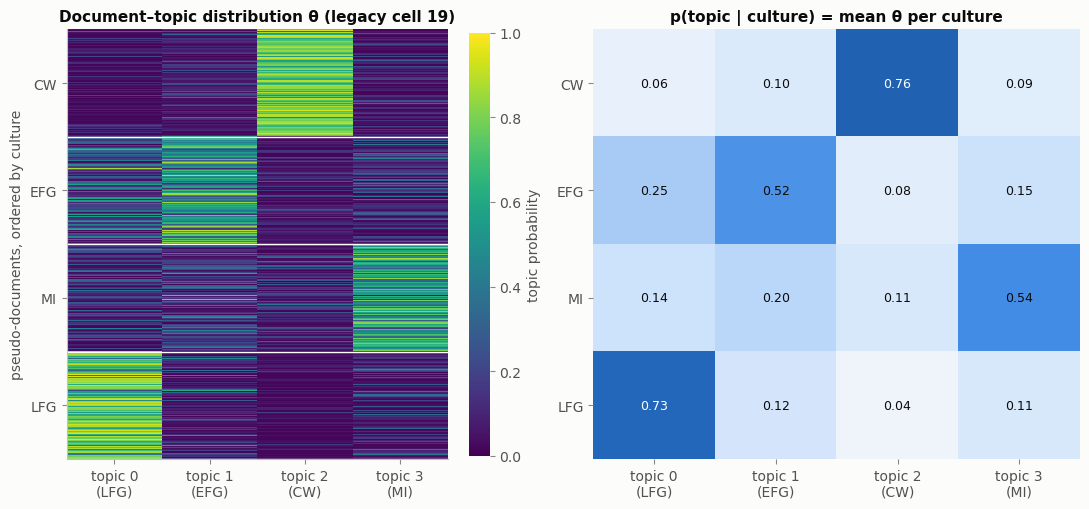

NMI(dominant topic, culture) on the pseudo-documents: 0.70


In [21]:
theta = lda_model.doc_topic_dist
p_topic_culture_lda = np.array([theta[corpus_culture == c].mean(0) for c in BOKS])
topic_names = [f"topic {k}\n({[c for c in BOKS if culture_mapping[c] == k][0]})" for k in range(4)]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1, 1.15]})
im = axes[0].imshow(theta, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="none")   # legacy cell 19
for c in BOKS:
    axes[0].axhline(np.where(corpus_culture == c)[0].max() + 0.5, color="white", lw=1)
axes[0].set_yticks([np.where(corpus_culture == c)[0].mean() for c in BOKS], BOKS)
axes[0].set_xticks(range(4), topic_names); axes[0].grid(False)
axes[0].set_ylabel("pseudo-documents, ordered by culture"); axes[0].set_title("Document–topic distribution θ (legacy cell 19)")
cb = fig.colorbar(im, ax=axes[0], fraction=0.05); cb.set_label("topic probability"); cb.outline.set_visible(False)
pl.heatmap(axes[1], p_topic_culture_lda, BOKS, topic_names, fmt="{:.2f}", vmin=0, vmax=1)
axes[1].set_title("p(topic | culture) = mean θ per culture")
fig.tight_layout(); plt.show()
nmi_lda = sbm.agreement(theta.argmax(1), corpus_culture)["NMI"]
print(f"NMI(dominant topic, culture) on the pseudo-documents: {nmi_lda:.2f}")


- *Shown:* the topic proportions $\theta_d$ of the 400 pseudo-documents, grouped by culture.
- *NMI:* the normalised mutual information between each document's dominant topic and its culture: 0 when the two partitions are unrelated, 1 when they are identical. At 0.70, the dominant topic usually, but not always, names the culture.
- *Caveat:* these are the training pseudo-documents, built by pooling vessels of one culture. Pooling alone produces NMI ≈ 0.2 even with meaningless labels (7.1).

Each culture's pseudo-documents are dominated by its own topic, but the FBW phases borrow from each other's topics — the same overlap seen above.

### 4.5 Cross-check with gensim
The legacy notebook also fitted gensim's variational LDA (cells 8–10). If both inference algorithms find the same topics on the same corpus, the topics are a property of the data rather than of the sampler.

In [22]:
try:
    from gensim import corpora
    from gensim.models import LdaModel
    dictionary = corpora.Dictionary([d["triplets"] for d in corpus])       # legacy cell 8
    bow = [dictionary.doc2bow(d["triplets"]) for d in corpus]
    gensim_lda = LdaModel(bow, id2word=dictionary, num_topics=4, alpha=1.0, eta=1.0,
                          iterations=1000, passes=20, random_state=SEED)  # legacy cell 9, same priors as above
    phi_gensim = np.zeros((4, len(vocabulary)))
    for k, row in enumerate(gensim_lda.get_topics()):
        for j, p in enumerate(row):
            phi_gensim[k, vocab_index[dictionary[j]]] = p
    pairing, Jg = tm.matching_empirical(lda_model.topic_word_dist, phi_gensim, list(range(4)))
    print("Gibbs topic -> gensim topic:", pairing)
    print("JS between paired topics (bits):", np.round([Jg[k, pairing[k]] for k in range(4)], 3),
          "| smallest JS between unpaired topics:", round(min(Jg[k, j] for k in range(4) for j in range(4) if j != pairing[k]), 3))
except ImportError:
    print("gensim not installed: cross-check skipped")

Gibbs topic -> gensim topic: {0: 3, 1: 2, 2: 0, 3: 1}
JS between paired topics (bits): [0.008 0.045 0.007 0.06 ] | smallest JS between unpaired topics: 0.086


Paired topics differ by 0.007–0.06 bits, unpaired topics by at least 0.09: variational and Gibbs inference pair the four topics one-to-one. The margin is smaller than with the legacy stop triplets removed (0.003–0.08 against ≥ 0.27), because with every triplet kept all topics share the frequent opening and burnishing triplets.

### 4.6 Hyperparameters: fit criterion vs prediction
The legacy grid (cell 25) scored each $(\alpha,\beta)$ by the JS divergence between each culture and its matched topic (`lda_best_fit`). That criterion is computed on the training corpus; next to it is the accuracy on the held-out sites.

In [23]:
grid = [(0.1, 0.5), (0.1, 1.0), (0.1, 2.0), (0.3, 0.5), (0.5, 1.0), (0.5, 2.0), (1.0, 0.5), (1.0, 1.0), (2.0, 2.0)]
rows = []
for a, b in grid:
    m = tm.LDA_manual(4, a, b, n_iter=100, random_state=SEED).fit(X, vocabulary)
    mapping, Jab = tm.matching_empirical(empirical, m.topic_word_dist, BOKS)
    s = ev.scores(y_test, tm.lda_culture_proba(m, test_c, vocabulary, mapping, BOKS))
    js = [Jab[i, mapping[c]] for i, c in enumerate(BOKS)]
    rows.append({"alpha": a, "beta": b, **{f"JS {c}": x for c, x in zip(BOKS, js)}, "mean JS": np.mean(js),
                 "held-out accuracy": s["accuracy"], "held-out log-loss": s["log_loss"]})
lda_best_fit = pd.DataFrame(rows).set_index(["alpha", "beta"])
lda_best_fit

JS CW  JS EFG  JS MI  JS LFG  mean JS  held-out accuracy  \
alpha beta                                                             
0.1   0.5   0.008   0.012  0.008   0.007    0.009              0.519   
      1.0   0.008   0.062  0.025   0.008    0.026              0.519   
      2.0   0.009   0.043  0.020   0.012    0.021              0.538   
0.3   0.5   0.014   0.016  0.017   0.011    0.014              0.442   
0.5   1.0   0.017   0.027  0.024   0.018    0.022              0.462   
      2.0   0.016   0.032  0.019   0.017    0.021              0.519   
1.0   0.5   0.029   0.123  0.061   0.026    0.060              0.500   
      1.0   0.026   0.037  0.036   0.026    0.031              0.500   
2.0   2.0   0.040   0.090  0.060   0.043    0.058              0.481   

            held-out log-loss  
alpha beta                     
0.1   0.5               1.407  
      1.0               1.426  
      2.0               1.412  
0.3   0.5               1.334  
0.5   1.0               1.252  
      2.0               1.204  
1.0   0.5               1.218  
      1.0               1.218  
2.0   2.0               1.252

The fit criterion prefers small $\alpha$ (mean JS 0.009–0.026 against 0.031–0.060 for $\alpha\ge1$). On this split held-out accuracy happens to be a little higher there too (0.52–0.54 against 0.48–0.50), but with 52 held-out vessels differences below about ±0.14 (two binomial standard errors) are noise, and the held-out log-loss is worse (1.41–1.43 against 1.22–1.25): a small $\alpha$ makes confident mistakes (7.6). The Gibbs sampler adds its own randomness (100 iterations here, 200 in 4.2). An in-sample fit criterion is not a model-selection criterion; Section 7 uses cross-validation instead.

### 4.7 Classifying new vessels
**How a new vessel is classified** (`classify_new_vessel`, legacy cells 28–31, corrected):
1. The topics $\phi$ stay fixed, as fitted by collapsed Gibbs sampling on the training pseudo-documents (4.2).
2. The vessel's topic mixture $\theta$ is *folded in* from its $N$ known triplets $w_1,\dots,w_N$. Starting from $\theta_k=1/K$, repeat 50 times:
$$r_{nk}=\frac{\theta_k\,\phi_k(w_n)}{\sum_j\theta_j\,\phi_j(w_n)},\qquad \theta_k=\frac{\sum_n r_{nk}+\alpha}{N+K\alpha}.$$
   This is EM for the most probable $\theta$ (MAP), and it is deterministic. A Gibbs fold-in would sample each $z_n$ with the same conditional; the majority vote of the $z_n$ estimates the same dominant topic, up to sampling noise.
3. Each topic stands for one BoK (one-to-one matching, 4.3), so $\hat p(c\mid x)=\theta_{k(c)}$, and the predicted BoK is $\arg\max_c\hat p(c\mid x)$.

**"Classified correctly"** means that the predicted BoK equals Kroon's label of the vessel. The test vessels are the 52 vessels of the 17 held-out sites, never used for the vocabulary, the pseudo-documents or the topics.

**The check.** The `assert` in the next cell recomputes the 52 predictions with the cross-validation pipeline of Section 7 (`clf.LDAPipeline`) and requires them to be identical. So the cross-validated numbers of Section 7 come from exactly this procedure, applied fold by fold.

First a few held-out vessels, then all of them; the pipeline is also scored in-sample, as in the legacy notebook. (The legacy version looked the mapping up the wrong way round and always returned "Topic_k".)

In [24]:
examples = []
for d in test_c[::10]:
    r = tm.classify_new_vessel(d["triplets"], lda_model, vocabulary, culture_mapping)
    examples.append({"vessel": d["vessel_id"], "true": d["culture"], "predicted": r["predicted_culture"],
                     "max probability": r["max_probability"], "confidence": r["confidence"]})
display(pd.DataFrame(examples).set_index("vessel"))

p_lda = tm.lda_culture_proba(lda_model, test_c, vocabulary, culture_mapping, BOKS)
# the cross-validation pipeline of Section 7 is exactly this procedure:
assert np.allclose(p_lda, clf.LDAPipeline(remove_top=STOP_K, seed=SEED).fit(train_df).predict_proba(test_df))
R.add("LDA", "held-out sites", y_test, p_lda)
R.add("LDA", "in-sample (legacy protocol)", y_bok, clf.LDAPipeline(remove_top=STOP_K, seed=SEED).fit(df).predict_proba(df))
R.table(models=["LDA"])

,true,predicted,max probability,confidence
vessel,,,,
13,CW,CW,0.659,High
150,CW,CW,0.437,Medium
19,EFG,LFG,0.404,Medium
104,MI,LFG,0.380,Low
247,MI,CW,0.374,Low
106,LFG,LFG,0.614,High


n  accuracy  balanced_acc  macro_F1  \
model protocol                                                             
LDA   held-out sites                52     0.442         0.491     0.410   
      in-sample (legacy protocol)  276     0.572         0.581     0.558   

                                   log_loss  brier    ECE  
model protocol                                             
LDA   held-out sites                  1.224  0.669  0.105  
      in-sample (legacy protocol)     1.112  0.587  0.094

**How to read it.**
- *First table:* six held-out vessels (every tenth) with the BoK predicted by the legacy `classify_new_vessel`, its probability, and the legacy confidence label (High ≥ 0.6, Medium ≥ 0.4, Low < 0.4). Three of the six are right, and the largest probability is 0.66: LDA rarely commits strongly.
- *Second table:* the same LDA scored on the 52 held-out vessels, and on all 276 vessels it was fitted on, as in the legacy notebook.
- *Evidence:* with 52 vessels, one standard error of accuracy is ≈ 0.07, so 0.44 vs 0.57 is only suggestive on this split. Cross-validation over all vessels gives 0.50 (7.3), confirming the gap.
- *Caveat:* in-sample scores reward memorising the training data. Only held-out scores estimate performance on a new site.

The `assert` above checks that the pipeline used for cross-validation in Section 7 gives exactly these predictions.

**Why a good fit is not a good classifier.** LDA reproduces each BoK's triplet distribution closely (4.3), yet classifies only about half of the held-out vessels. These are different tasks:
- *Fit* asks whether $\phi_{k(c)}\approx p(w\mid c)$, for each BoK on its own.
- *Classification* asks whether one vessel's few triplets tell the BoKs *apart*. That depends on how much the BoKs' distributions differ, and on how many triplets a vessel has.

For two BoKs $c,c'$ and a vessel of $N$ independent triplets, the error of the best rule choosing between them is bounded (Bhattacharyya):
$$P(\text{error})\le\sqrt{\pi_c\,\pi_{c'}}\;\rho_{cc'}^{\,N},\qquad \rho_{cc'}=\sum_w\sqrt{\phi_{k(c)}(w)\,\phi_{k(c')}(w)}\in[0,1].$$
Here $\rho=1$ means identical distributions (no information) and $\rho=0$ disjoint ones. The table gives $\rho$ for the fitted topics and the bound at the held-out vessels' median $N$.

In [25]:
phi_c = lda_model.topic_word_dist[[culture_mapping[c] for c in BOKS]]
N_med = int(np.median([sum(t in vocab_index for t in d["triplets"]) for d in test_c]))
prior_c = pd.Series(y_train).value_counts(normalize=True).reindex(BOKS).to_numpy()
rows = []
for a in range(len(BOKS)):
    for b in range(a + 1, len(BOKS)):
        rho = np.sqrt(phi_c[a] * phi_c[b]).sum()
        rows.append({"pair": f"{BOKS[a]}–{BOKS[b]}", "ρ per triplet": rho,
                     f"error bound, N = {N_med}": np.sqrt(prior_c[a] * prior_c[b]) * rho ** N_med,
                     "JS between the topics (bits)": tm.js_divergence(phi_c[a], phi_c[b])})
print(f"median number of known triplets in a held-out vessel: N = {N_med}")
pd.DataFrame(rows).set_index("pair")

median number of known triplets in a held-out vessel: N = 9


,ρ per triplet,"error bound, N = 9",JS between the topics (bits)
pair,,,
CW–EFG,0.691,9.702e-03,0.376
CW–MI,0.708,1.441e-02,0.360
CW–LFG,0.515,4.966e-04,0.561
EFG–MI,0.883,9.023e-02,0.150
EFG–LFG,0.822,2.856e-02,0.227
MI–LFG,0.791,2.408e-02,0.257


**Reading.**
- Per triplet the topics overlap substantially: $\rho$ goes from 0.52 (CW–late FBW) to 0.88 (early–middle FBW).
- If a vessel's $N=9$ triplets were independent draws from its BoK's topic, even this overlap would allow few errors: every pairwise bound is at most 0.09, and the six add up to 0.17. The observed error is about 0.5.
- The gap is therefore not in the fit of $\phi$, but in the model's assumption about a *vessel*:
  - **A vessel is one chain, not $N$ independent draws.** Each step sits in up to three triplets, so the evidence is closer to $N/3=3$ independent tokens. With $N=3$ the six pairwise bounds add up to ≈ 0.6, the size of the observed error.
  - **Identical chains occur in different BoKs**, which caps any chain-only rule at 0.73 (1.2).
  - **Held-out sites differ from the training sites**, whose average the topics describe.
- In short: LDA describes the *average* triplet use of each BoK well; a single vessel is far from that average.

## 5 · Topic model II: the hierarchical SBM with sbmtm and graph-tool

**Model** (Gerlach, Peixoto & Altmann 2018). The corpus is a bipartite multigraph: document nodes, word nodes, one edge per occurrence of a word in a document. A nested, degree-corrected stochastic block model partitions document nodes and word nodes into groups, and groups into groups at higher levels. Word groups are the **topics**; a document's share of edges into each word group, $p(t\mid d)$, plays the role of $\theta_d$. The partition $b$ minimises the **description length**
$$S(b) = -\log P(A\mid b) - \log P(b),$$
the number of nats needed to encode the network with the model (Peixoto 2014, 2017). The number of groups at every level is inferred, not fixed as $K$ in LDA.

The fit uses the legacy code `sbmtm.py` (vendored unchanged) on **the same pseudo-documents** as LDA (4.2). Beyond the legacy notebook, graph-tool's inference workflow is completed: several initialisations and a refinement of the partition (5.1), posterior uncertainty of the partition (5.4), the placement of new vessels by description length (5.5), and a test of the overlapping model (7.2).

### 5.1 Fitting: several starts and refinement
`sbmtm.fit` runs `minimize_nested_blockmodel_dl` once and truncates the hierarchy. That gives a good partition but not necessarily the best: graph-tool recommends several initialisations and merge–split MCMC sweeps at zero temperature (Peixoto 2020) to lower the description length further.

In [26]:
if RUN_SBM:
    tokens = [d["triplets"] for d in corpus]
    rows = []
    for s in range(3):
        m = sbm.fit_hsbm(tokens, seed=s)                 # sbmtm: make_graph(counts=True) + fit(overlap=False)
        before, after = sbm.refine(m, sweeps=50)         # merge-split sweeps at beta = inf
        rows.append({"seed": s, "S after sbmtm.fit (nats)": before, "S after refinement (nats)": after,
                     **{f"level {h['level']}": f"{h['doc_groups']} doc / {h['word_groups']} word groups"
                        for h in sbm.hierarchy(m) if h["doc_groups"] > 1}})
        if s == SEED:
            hsbm = m
    g = hsbm.g
    print(f"network: {hsbm.get_D()} document nodes, {hsbm.get_V()} word nodes, "
          f"{g.num_edges()} distinct edges, {int(g.ep['count'].a.sum())} tokens")
    display(pd.DataFrame(rows).set_index("seed"))

network: 400 document nodes, 93 word nodes, 9303 distinct edges, 23210 tokens


,S after sbmtm.fit (nats),S after refinement (nats),level 0
seed,,,
0,21760.762,21337.448,5 doc / 24 word groups
1,21705.961,21461.240,4 doc / 24 word groups
2,21685.241,21545.497,3 doc / 15 word groups


Refinement lowers the description length by 140–420 nats, and the starts disagree on the partition (seed 0: 5 document groups and 24 topics at level 0; seed 1: 4 and 24; seed 2: 3 and 15). A single call of `sbmtm.fit` should not be read as *the* partition. Seed 0 has the lowest description length and is used below — the same model the cross-validation pipeline builds. The standard hierarchy plot of Gerlach et al. (`sbmtm.plot`, graph-tool's `draw_hierarchy`), pseudo-documents on one side, triplets on the other, groups of groups in the middle:

l: 0, N: 493, B: 29
l: 1, N: 29, B: 4
l: 2, N: 4, B: 2
l: 3, N: 2, B: 1


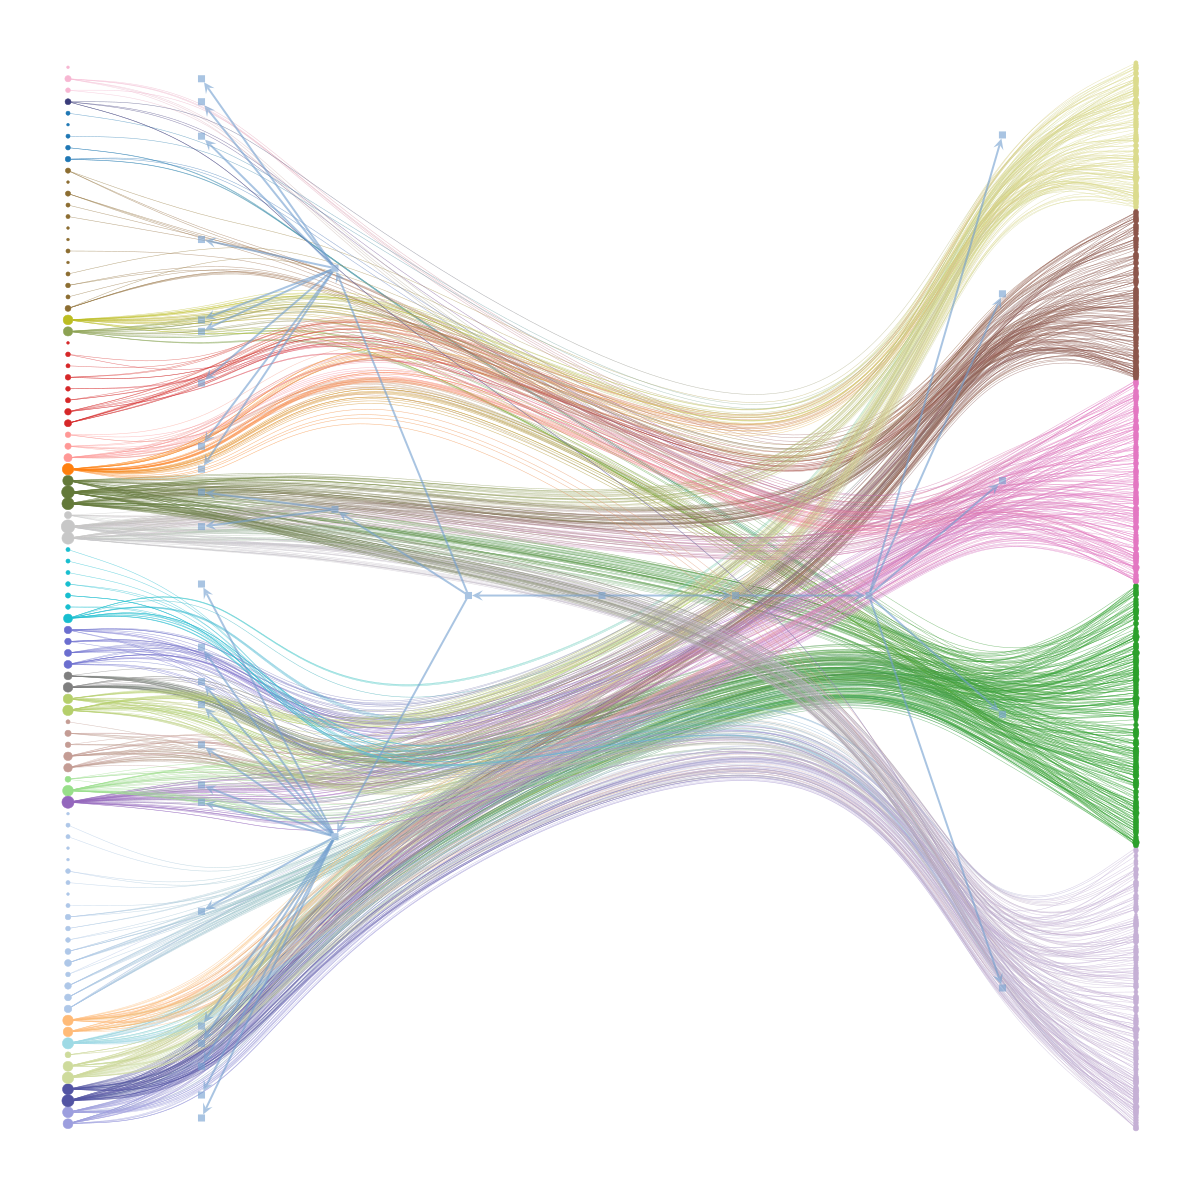

In [27]:
if RUN_SBM:
    hsbm.print_summary()
    path = ROOT / "figures" / "hsbm_hierarchy.png"
    hsbm.plot(filename=str(path), nedges=1000)
    display(Image(filename=str(path), width=520))

**How to read it.**
- *Printed lines:* graph-tool's summary of the nested partition: at level $l$, $N$ nodes are grouped into $B$ groups. On the LEFT the triplets on the RIGHT the resampled documents.

  - Level 0: the 493 nodes (400 pseudo-documents + 93 triplets) form 29 groups (5 document groups + 24 topics).
  - Level 1 groups these 29 into 4: all pseudo-documents in one group, and the triplets in 3 topics (used in 5.3).
  - Level 2 groups those into 2 — documents and triplets, which never mix — and the top level joins the two.
- *Figure:* the same tree, with pseudo-documents on one side, triplets on the other and the nested groups in between.

### 5.2 Document groups and cultures, level by level
The legacy notebook counted cultures per document cluster at level 0 (cell 49). Contingency tables and agreement with the cultures at every level of the hierarchy:

In [28]:
if RUN_SBM:
    rows, tables = [], {}
    for h in sbm.hierarchy(hsbm):
        if h["doc_groups"] == 1:
            continue
        part = sbm.doc_partition(hsbm, h["level"])
        tables[h["level"]] = pd.crosstab(pd.Series(part, name=f"group, level {h['level']}"),
                                         pd.Series(corpus_culture, name="culture"))[BOKS]
        rows.append({**h, **sbm.agreement(part, corpus_culture)})
    display(pd.DataFrame(rows).set_index("level"))
    for level, table in tables.items():
        display(table.T)

,doc_groups,word_groups,NMI,ARI
level,,,,
0,5,24,0.775,0.759


"group, level 0",0,1,2,3,4
culture,,,,,
CW,99,1,0,0,0
EFG,0,3,62,28,7
MI,0,72,2,26,0
LFG,0,0,0,1,99


**How to read it.**
- *First table:* the agreement between document groups and cultures: NMI (4.4) and the adjusted Rand index ARI (0 = chance agreement, 1 = identical partitions). Only level 0 has more than one document group; level 1 puts all pseudo-documents together.
- *Contingency table:* rows are cultures, columns are document groups; entries count pseudo-documents (100 per culture).
- *Numbers:* CW and late FBW are 99 % in their own group. Early FBW is 62 % in its own group and middle FBW 72 %; the rest of both sit together in group 3 (28 early + 26 middle): NMI 0.78, ARI 0.76.
- *Caveat:* these are pseudo-documents of known culture. Part of the separation is produced by the pooling (7.1).

The pseudo-documents separate largely by culture — CW and late FBW cleanly, early and middle FBW with one shared group — reproducing the legacy observation that "the documents are nicely separated between cultures". Section 7.1 measures how much of this separation the pooling produces by itself.

### 5.3 Topics and what the cultures share
`sbmtm.topics` lists the most probable triplets of each word group, $p(w\mid t)$. Averaging the documents' topic mixtures gives each culture's topic weights $p(t\mid c)$, and $p(w\mid c)=\sum_t p(w\mid t)\,p(t\mid c)$ is the model's triplet distribution for the culture. This replaces legacy cells 64–69 ("combination of topics"), which averaged rows of the group *membership* $p(t\mid w)$ — for a non-overlapping SBM 0/1 indicators — against a binarised empirical matrix, i.e. compared sets of words rather than distributions.

**Which level.** The hSBM is a hierarchy of topics: each level groups the topics of the level below. `LAYER` (first line of the next cell) chooses the level shown in 5.3: `LAYER = 0` gives the finest topics (24 here), `LAYER = 1` fewer, broader ones (3 here). Below: `LAYER = 1`. Section 6 always compares at level 0.

level 1: 3 topics


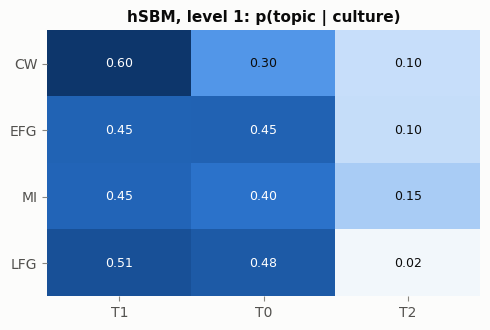

,most probable triplets,specificity (max / mean over cultures),most used by
topic,,,
T1,Coiling › Pressure › Wet smoothing | Coiling › Pressure › Application separate element | Simple impression...,1.200,CW
T0,Wet clay › Modelling › Coiling | Modelling › Coiling › Pressure | Burnishing › Dry › Open firing | Leather...,1.167,LFG
T2,Pressure › Wet smoothing › Simple impression | Scraping › Wet smoothing › Simple impression | Dry › Open f...,1.655,MI


In [29]:
LAYER = 1                                  # <- hierarchy level of the topics in 5.3: 0 = finest (most topics), 1 = fewer, broader topics
if RUN_SBM:
    topics = hsbm.topics(l=LAYER, n=4)                              # sbmtm
    p_t_c, p_w_c_hsbm = sbm.culture_topic_mixture(hsbm, corpus_culture, BOKS, level=LAYER)
    order = np.argsort(-p_t_c.max(0))
    print(f"level {LAYER}: {p_t_c.shape[1]} topics")
    fig, ax = plt.subplots(figsize=(max(5, 0.45 * p_t_c.shape[1] + 2), 3.4))
    pl.heatmap(ax, p_t_c[:, order], BOKS, [f"T{k}" for k in order], fmt="{:.2f}", vmin=0)
    ax.set_title(f"hSBM, level {LAYER}: p(topic | culture)"); fig.tight_layout(); plt.show()
    display(pd.DataFrame({
        "topic": [f"T{k}" for k in order],
        "most probable triplets": [" | ".join(pl.short(w) for w, _ in topics[k]) for k in order],
        "specificity (max / mean over cultures)": (p_t_c.max(0) / p_t_c.mean(0))[order],
        "most used by": [BOKS[i] for i in p_t_c[:, order].argmax(0)],
    }).set_index("topic"))

**Triplet–topic matrix of the hSBM** (the legacy `p_w_tw` heatmap), at level `LAYER`.
- Columns: the topics, ordered as in the table above and labelled with the BoK that uses them most.
- Rows: the triplets, grouped by topic.
- Colour: $p(w\mid t)$, the triplet's share of its topic's tokens.

The hSBM is non-overlapping: each triplet belongs to exactly one topic. Each row therefore has a single non-zero entry, and the matrix is block-diagonal.

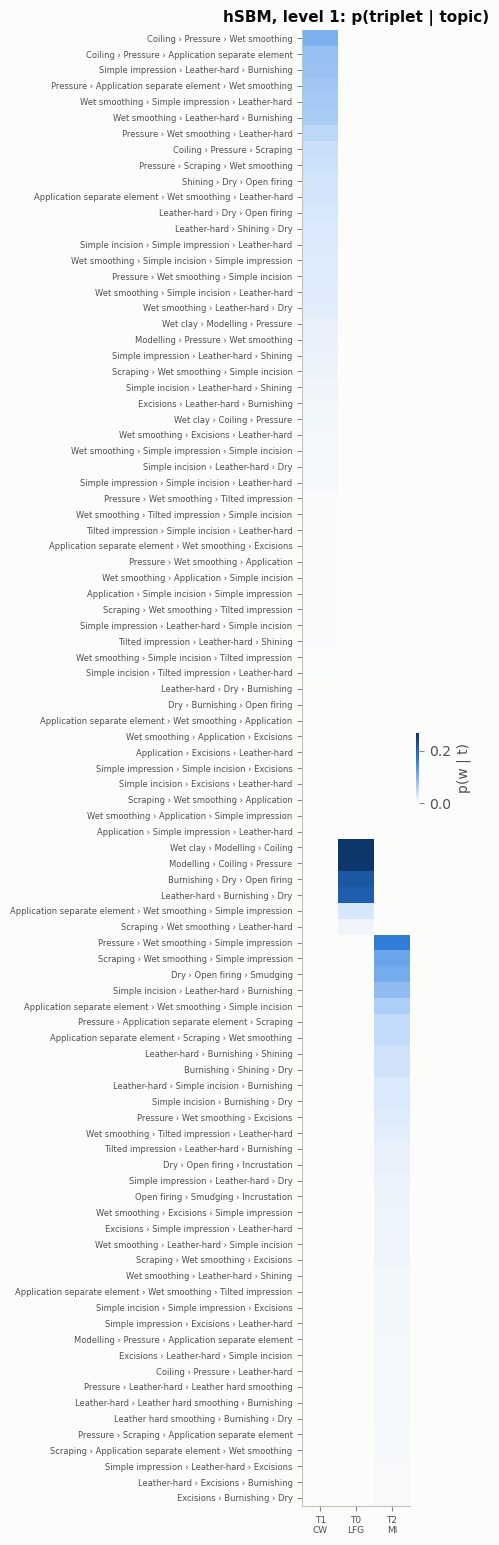

In [30]:
if RUN_SBM:
    pwt = hsbm.get_groups(LAYER)["p_w_tw"][:, order]                  # triplets × topics, columns as in the table
    owner = pwt.argmax(1)
    rows = np.lexsort((-pwt.max(1), owner))
    fig, ax = plt.subplots(figsize=(max(5, 0.38 * pwt.shape[1] + 3), 0.15 * len(rows) + 1.6))
    im = ax.imshow(pwt[rows], aspect="auto", cmap=pl.SEQ, interpolation="none")
    ax.set_xticks(range(pwt.shape[1]), [f"T{k}\n{BOKS[i]}" for k, i in zip(order, p_t_c[:, order].argmax(0))], fontsize=6.5)
    ax.set_yticks(range(len(rows)), [pl.short(hsbm.words[j]) for j in rows], fontsize=6)
    ax.grid(False); ax.set_title(f"hSBM, level {LAYER}: p(triplet | topic)")
    fig.colorbar(im, ax=ax, fraction=0.03, label="p(w | t)").outline.set_visible(False)
    fig.tight_layout(); plt.show()

**How to read it** (level 1, 3 topics).
- *Heatmap:* $p(\text{topic}\mid\text{culture})$, how much of each culture's triplet use goes to each topic. Columns are sorted by their largest entry.
- *Table:* for each topic its most probable triplets; its *specificity*, the largest $p(\text{topic}\mid\text{culture})$ divided by its mean over the four cultures (1 = used equally by all, 4 = used by one culture only); and the culture that uses it most.
- *The three topics* (triplet–topic matrix below):
  - **T0, the common core** (6 triplets): the opening steps and burnishing. Used by all, a little less by CW (0.30 against 0.40–0.48).
  - **T1, forming and finishing** (about 50 triplets): wet smoothing, scraping, shining, separately applied elements, simple impression → burnishing. The largest share everywhere, most in CW (0.60 against 0.45–0.51).
  - **T2, decoration** (about 40 triplets): impressions, incisions, excisions, smudging, incrustation. Most in middle FBW (0.15), almost absent in late FBW (0.02).
- *Evidence:* no level-1 topic belongs to one culture (specificity 1.2–1.7, out of 4). At this level the cultures differ only in the *proportions* of three shared topics.
- *Caveat:* T1 lumps CW's scraping and shining with FBW's applied elements: level 1 groups topics by how they connect to the pseudo-documents, and with a single document group at level 1 that is mostly by frequency, not by culture.

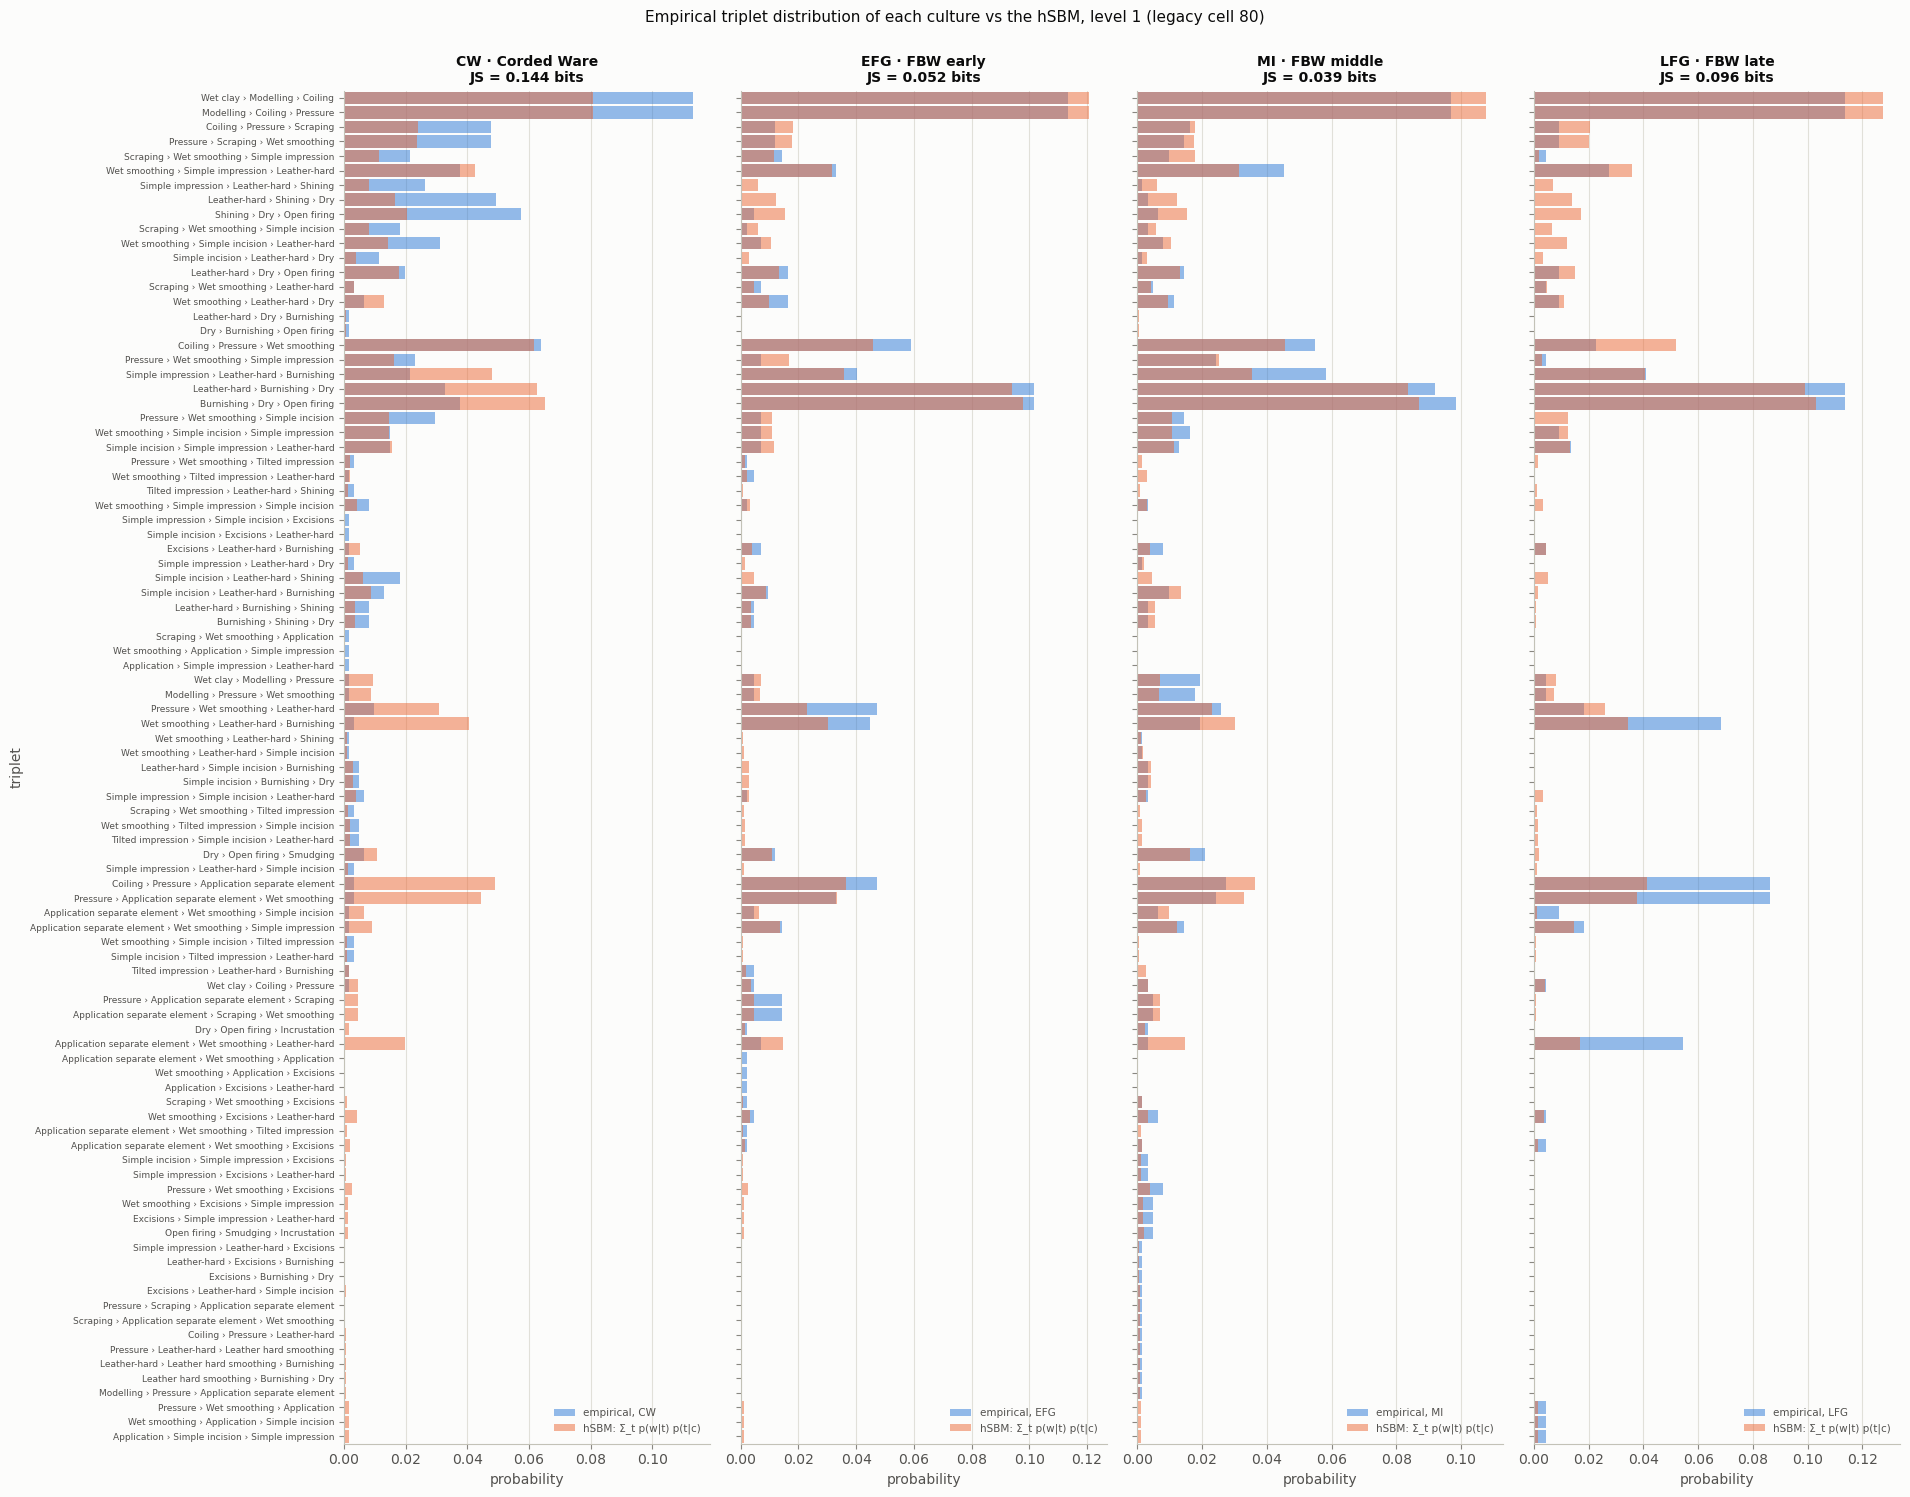

In [31]:
if RUN_SBM:
    position = {w: i for i, w in enumerate(hsbm.words)}
    p_w_c_sbm = np.zeros((len(BOKS), len(vocabulary)))
    for j, w in enumerate(vocabulary):
        if w in position:
            p_w_c_sbm[:, j] = p_w_c_hsbm[:, position[w]]
    js_sbm = [tm.js_divergence(e, m) for e, m in zip(empirical, p_w_c_sbm)]
    fig = overlay_distributions(empirical, p_w_c_sbm, vocabulary, BOKS, ["hSBM: Σ_t p(w|t) p(t|c)"] * len(BOKS),
                                f"Empirical triplet distribution of each culture vs the hSBM, level {LAYER} (legacy cell 80)", js=js_sbm)
    plt.show()

With 3 topics, $p(w\mid c)=\sum_t p(w\mid t)\,p(t\mid c)$ reproduces the cultures' triplet distributions only roughly: JS 0.04–0.14 bits (mean 0.08), against 0.006 with the 24 topics of level 0 and 0.022 for LDA's four (Section 6). The CW bars show why: CW's own triplets (shining, scraping) are diluted in T1 with FBW's applied elements. Level 1 is the coarse summary — one core shared by all, one block of forming and finishing, one of decoration; level 0 (`LAYER = 0`) is the faithful description, with topics specific to single cultures.

### 5.4 How certain is the partition? Posterior sampling
A single partition hides its uncertainty. graph-tool samples the posterior $P(b\mid A)\propto e^{-S(b)}$ by MCMC (`mcmc_equilibrate`) and aligns the group labels of the samples (`PartitionModeState`, Peixoto 2021). The marginal probability of each group for each node is the proper "soft membership" of a non-overlapping SBM — uncertainty about a node's group, not mixed membership (which is what the overlapping model of legacy cell 36 is about; see 7.2).

200 posterior samples: description length 21319 ± 19 nats; posterior entropy of the partition 117.0 nats
nodes whose group is uncertain (max marginal < 0.9): 130 of 400 pseudo-documents, 23 of 93 triplets


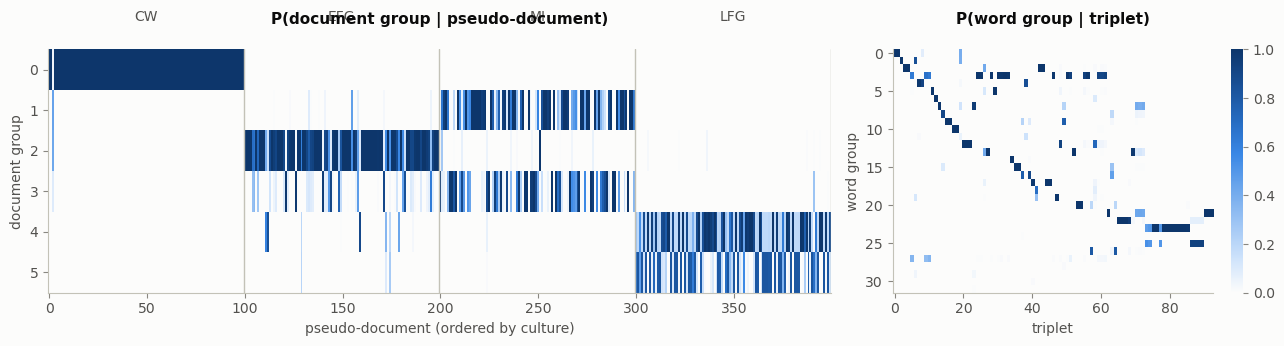

In [32]:
if RUN_SBM:
    pmode, dl = sbm.sample_partitions(hsbm, n_samples=200)
    doc_marg, word_marg = sbm.posterior_marginals(hsbm, pmode)
    print(f"200 posterior samples: description length {dl.mean():.0f} ± {dl.std():.0f} nats; "
          f"posterior entropy of the partition {pmode.posterior_entropy():.1f} nats")
    print(f"nodes whose group is uncertain (max marginal < 0.9): {(doc_marg.max(1) < 0.9).sum()} of "
          f"{len(doc_marg)} pseudo-documents, {(word_marg.max(1) < 0.9).sum()} of {len(word_marg)} triplets")
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
    axes[0].imshow(doc_marg.T, aspect="auto", cmap=pl.SEQ, vmin=0, vmax=1, interpolation="none")
    for c in BOKS:
        idx = np.where(corpus_culture == c)[0]
        axes[0].axvline(idx.max() + 0.5, color=pl.INK["axis"], lw=1)
        axes[0].text(idx.mean(), -1.2, c, ha="center", color=pl.INK["secondary"])
    axes[0].set_xlabel("pseudo-document (ordered by culture)"); axes[0].set_ylabel("document group")
    axes[0].set_title("P(document group | pseudo-document)", pad=18); axes[0].grid(False)
    im = axes[1].imshow(word_marg.T, aspect="auto", cmap=pl.SEQ, vmin=0, vmax=1, interpolation="none")
    axes[1].set_xlabel("triplet"); axes[1].set_ylabel("word group"); axes[1].set_title("P(word group | triplet)", pad=18)
    axes[1].grid(False); fig.colorbar(im, ax=axes[1], fraction=0.05).outline.set_visible(False)
    fig.tight_layout(); plt.show()

**How to read it.**
- *Numbers:*
  - 200 partitions sampled from the posterior have description lengths of 21319 ± 19 nats, at or slightly below the refined partition (21337 nats, 5.1): the refined partition is a typical one, and MCMC finds marginally better ones.
  - The posterior entropy of 117 nats means that about $e^{117}$ partitions are plausible, almost all differing only in where a few nodes go.
  - 130 of the 400 pseudo-documents and 23 of the 93 triplets have no group with marginal probability ≥ 0.9.
- *Figure:* each column is a node and each row a group; dark means probability near 1.

CW and early FBW are placed firmly. The uncertain pseudo-documents are middle FBW, which moves between its own group and the group it shares with early FBW, and late FBW, which the posterior often splits into two sub-groups. The words are almost all firmly assigned to one topic.

### 5.5 Classifying new vessels: two ways
**(a) Legacy cluster classifier** (cells 77, 84): name each document cluster after its majority culture (`compute_word_cluster_matrix`), score a new vessel by the likelihood of its triplets under each cluster (`classify_vessel_simple`).

**(b) Fold-in by description length** — the corrected version of the legacy `infer_new_doc_membership` (cell 86, never run): add the vessel as a new document node with its triplet edges, keep every other node's group fixed, and compute the description length $S_r$ of the whole hierarchy with the new node in each document group $r$. Then
$$P(r\mid\text{vessel}) \propto e^{-(S_r-\min_r S_r)},\qquad p(\text{culture}\mid\text{vessel})=\sum_r P(r\mid\text{vessel})\,p(\text{culture}\mid r).$$
This is the conditional posterior graph-tool's own MCMC samples from, so the classifier uses the fitted model itself rather than a word-count summary of it.

In [33]:
if RUN_SBM:
    test_tokens = [d["triplets"] for d in test_c]
    sbm_nb = sbm.SBMClassifier().fit(tokens, list(corpus_culture), BOKS, model=hsbm)
    print("document clusters (legacy naming):", sbm_nb.names)
    sbm_fi = sbm.SBMFoldInClassifier().fit(tokens, list(corpus_culture), BOKS, model=hsbm)
    dS, groups = next(sbm._fold_in_delta_s(hsbm, test_tokens[:1]))      # example: first held-out vessel
    P = np.exp(-(dS - dS.min())); P /= P.sum()
    print(f"\nvessel {test_c[0]['vessel_id']} (true: {test_c[0]['culture']}), four most probable groups:")
    display(pd.DataFrame({"S_r - min S (nats)": dS - dS.min(), "P(r | vessel)": P,
                          **{f"p({c} | r)": sbm_fi.p_class_given_group[:, i] for i, c in enumerate(BOKS)}},
                         index=[f"group {r}" for r in groups]).sort_values("P(r | vessel)", ascending=False).head(4))

document clusters (legacy naming): ['CW (C0, 99/99)', 'MI (C1, 72/76)', 'EFG (C2, 62/64)', 'EFG (C3, 28/55)', 'LFG (C4, 99/106)']

vessel 13 (true: CW), four most probable groups:


,S_r - min S (nats),P(r | vessel),p(CW | r),p(EFG | r),p(MI | r),p(LFG | r)
group 67,0.000,9.999e-01,1.000,0.000,0.000,0.000
group 274,9.088,1.130e-04,0.013,0.039,0.947,0.000
group 245,11.816,7.385e-06,0.000,0.969,0.031,0.000
group 351,11.965,6.365e-06,0.000,0.509,0.473,0.018


**How to read it.**
- *First line:* the 5 level-0 document groups, named by their majority culture (count of that culture / group size).
- *Table:* for one held-out CW vessel, the four cheapest document groups to place it in. Columns:
  - the extra description length of placing it there, $S_r-\min S$ (nats);
  - the resulting probability $P(r\mid\text{vessel})\propto e^{-(S_r-\min S)}$;
  - the culture composition $p(c\mid r)$ of the group.

  The attribution is $\sum_r P(r\mid\text{vessel})\,p(c\mid r)$.
- *Numbers:* a 9.1-nat gap means odds of $e^{9.1}\approx9000$ to 1 for the cheapest group.

The CW vessel is placed in the CW group with probability 0.9999; the next groups cost at least 9.1 nats more. Such sharp posteriors are typical — every token moves the description length by several nats — and they are one source of the over-confidence measured below.

In [34]:
if RUN_SBM:
    p_nb, p_fi = sbm_nb.predict_proba(test_tokens), sbm_fi.predict_proba(test_tokens)
    # the cross-validation pipelines of Section 7 are exactly these procedures:
    assert np.allclose(p_fi, clf.SBMPipeline("fold-in", remove_top=STOP_K, seed=SEED).fit(train_df).predict_proba(test_df))
    assert np.allclose(p_nb, clf.SBMPipeline("clusters", remove_top=STOP_K, seed=SEED).fit(train_df).predict_proba(test_df))
    R.add("hSBM, cluster classifier", "held-out sites", y_test, p_nb)
    R.add("hSBM, fold-in", "held-out sites", y_test, p_fi)
    for method, name in [("clusters", "hSBM, cluster classifier"), ("fold-in", "hSBM, fold-in")]:
        R.add(name, "in-sample (legacy protocol)", y_bok,
              clf.SBMPipeline(method, remove_top=STOP_K, seed=SEED).fit(df).predict_proba(df))
    display(R.table(models=["hSBM, cluster classifier", "hSBM, fold-in"]))

n  accuracy  \
model                    protocol                                     
hSBM, cluster classifier held-out sites                52     0.385   
                         in-sample (legacy protocol)  276     0.616   
hSBM, fold-in            held-out sites                52     0.500   
                         in-sample (legacy protocol)  276     0.605   

                                                      balanced_acc  macro_F1  \
model                    protocol                                              
hSBM, cluster classifier held-out sites                      0.502     0.399   
                         in-sample (legacy protocol)         0.637     0.592   
hSBM, fold-in            held-out sites                      0.575     0.495   
                         in-sample (legacy protocol)         0.629     0.590   

                                                      log_loss  brier    ECE  
model                    protocol                                             
hSBM, cluster classifier held-out sites                  2.354  0.923  0.416  
                         in-sample (legacy protocol)     0.928  0.491  0.148  
hSBM, fold-in            held-out sites                  1.465  0.699  0.223  
                         in-sample (legacy protocol)     0.921  0.487  0.133

**How to read it.**
- *Shown:* the two hSBM classifiers on the 52 held-out vessels and in-sample.
- *Evidence:* one standard error on 52 vessels is ≈ 0.07, so 0.38 vs 0.50 on this split is suggestive at most. Under cross-validation the two coincide (0.53 and 0.52, 7.3).
- *Caveat:* held out, the ECE is 0.22–0.42 and the log-loss 1.5–2.4: probabilities near 1 are often wrong.

On the held-out sites the fold-in classifier scores 0.50 and the legacy cluster classifier 0.38; in-sample (legacy protocol) 0.61 and 0.62, close to the legacy in-sample figure of 0.64 (why the two protocols differ so much: 7.3). Both `assert` lines check that the cross-validation pipelines give exactly these predictions.

## 6 · LDA vs hSBM on the same corpus and the same held-out sites

,LDA,"hSBM, cluster classifier","hSBM, fold-in"
number of topics,4 (fixed),"24 (inferred, level 0)","24 (inferred, level 0)"
document groups,none (mixtures),5 (level 0),5 (level 0)
"NMI(pseudo-document clusters, culture)",0.7,0.775,0.775
"mean JS, model vs empirical p(w | c) (bits)",0.022,0.006,0.006
held-out accuracy,0.442,0.385,0.5
held-out balanced accuracy,0.491,0.502,0.575
held-out log-loss,1.224,2.354,1.465
in-sample accuracy (legacy protocol),0.572,0.616,0.605


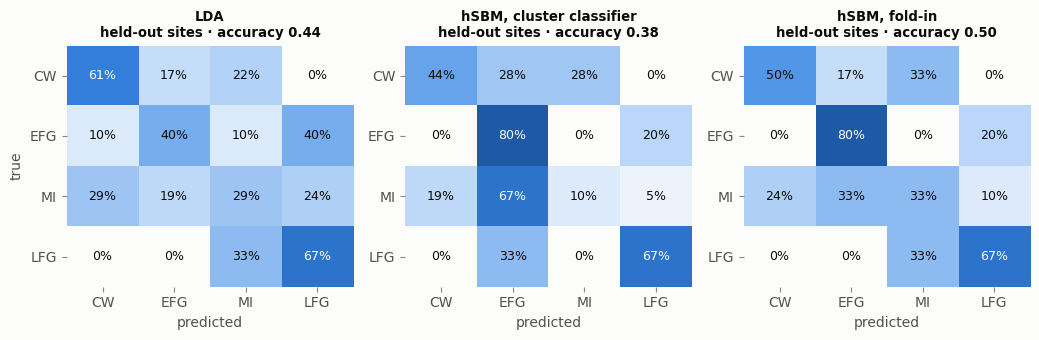

In [35]:
topic_models = ["LDA"] + (["hSBM, cluster classifier", "hSBM, fold-in"] if RUN_SBM else [])
held, insample = R.table("held-out sites"), R.table("in-sample (legacy protocol)")
lda_mix = p_topic_culture_lda @ lda_model.topic_word_dist                  # LDA's Σ_k p(w|k) p(k|c)
comparison = {"LDA": {
    "number of topics": "4 (fixed)", "document groups": "none (mixtures)",
    "NMI(pseudo-document clusters, culture)": nmi_lda,
    "mean JS, model vs empirical p(w | c) (bits)": np.mean([tm.js_divergence(e, m) for e, m in zip(empirical, lda_mix)]),
    "held-out accuracy": held.loc[("LDA", "held-out sites"), "accuracy"],
    "held-out balanced accuracy": held.loc[("LDA", "held-out sites"), "balanced_acc"],
    "held-out log-loss": held.loc[("LDA", "held-out sites"), "log_loss"],
    "in-sample accuracy (legacy protocol)": insample.loc[("LDA", "in-sample (legacy protocol)"), "accuracy"]}}
if RUN_SBM:
    h0 = sbm.hierarchy(hsbm)[0]
    _, p_w_c0 = sbm.culture_topic_mixture(hsbm, corpus_culture, BOKS, level=0)       # level 0, independent of LAYER
    pos0 = {w: i for i, w in enumerate(hsbm.words)}
    p_w_c0 = np.array([[p_w_c0[k, pos0[w]] if w in pos0 else 0.0 for w in vocabulary] for k in range(len(BOKS))])
    js_sbm0 = [tm.js_divergence(e, m) for e, m in zip(empirical, p_w_c0)]
    for name in topic_models[1:]:
        comparison[name] = {
            "number of topics": f"{h0['word_groups']} (inferred, level 0)",
            "document groups": f"{h0['doc_groups']} (level 0)",
            "NMI(pseudo-document clusters, culture)": sbm.agreement(sbm.doc_partition(hsbm), corpus_culture)["NMI"],
            "mean JS, model vs empirical p(w | c) (bits)": np.mean(js_sbm0),
            "held-out accuracy": held.loc[(name, "held-out sites"), "accuracy"],
            "held-out balanced accuracy": held.loc[(name, "held-out sites"), "balanced_acc"],
            "held-out log-loss": held.loc[(name, "held-out sites"), "log_loss"],
            "in-sample accuracy (legacy protocol)": insample.loc[(name, "in-sample (legacy protocol)"), "accuracy"]}
display(pd.DataFrame(comparison))
fig = pl.confusion_panel(R, [(m, "held-out sites") for m in topic_models]); plt.show()

On the same corpus and the same test vessels:
- **Structure.** The hSBM infers 24 topics and 5 document groups (level 0) where LDA is given 4 topics; its document clusters match the cultures better (NMI 0.78 against 0.70), and its implied triplet distributions are closer to the empirical ones (JS 0.006 vs 0.022 bits).
- **Attribution.** On 52 held-out vessels the three classifiers score 0.38–0.50 (± 0.07 each), 11–23 points below their in-sample scores.
- **Probabilities.** LDA's are the best calibrated (log-loss 1.22 vs 1.47 and 2.35).

Better description does not mean better attribution: the extra structure the hSBM finds lies mostly *within* cultures.

## 7 · How solid are these results?

Sections 4–6 test one split of 52 vessels (± 0.07). Seven checks:

| | question |
|---|---|
| 7.1 | Does the bootstrap create the structure the topic models find? |
| 7.2 | What does the hSBM find without the bootstrap? Does the overlapping model help? |
| 7.3 | What do the pipelines achieve under cross-validation, next to simple baselines? |
| 7.4 | How sensitive are they to the legacy choices ($g$, stop triplets)? |
| 7.5 | How much of the accuracy is vessel form? |
| 7.6 | Can the attribution be improved (prior, transitions, learned weights)? |
| 7.7 | Does co-occurrence carry more? Co-occurrence matrices and the biterm topic model |

### 7.1 Does the bootstrap create the cultures?
A pseudo-document pools $g$ vessels of one label (Section 3), so the label is written into the data before the unsupervised model sees it. The pseudo-documents are built in two ways, with the same function and the same training vessels:
- **Bootstrapped inside BoK**, as in Section 4: the $g$ vessels are drawn from one real BoK.
- **Bootstrapped among all**: the BoK labels are first shuffled at random among all training vessels (keeping 71, 52, 74 and 27 vessels per label), then the same bootstrap is run. Each "BoK" is now a random mix of all four, so there is no culture to find.

LDA and the hSBM never see the labels. We fit them, then measure how well their clusters match the labels used to build the pseudo-documents, with the NMI (0 = unrelated, 1 = identical). Anything above 0 for "bootstrapped among all" is produced by the procedure itself. Settings: $g$ = 1 (no pooling), 3, 7, 15; LDA with 100 Gibbs iterations; 3 seeds.

In [36]:
rows = []
for g in [1, 3, 7, 15]:
    for kind in ["Bootstrapped inside BoK", "Bootstrapped among all"]:
        for s in range(3):
            docs_s = train_c
            if kind == "Bootstrapped among all":            # BoK labels shuffled among all training vessels first
                shuffled = np.random.default_rng(100 + s).permutation([d["culture"] for d in train_c])
                docs_s = [{**d, "culture": c} for d, c in zip(train_c, shuffled)]
            pdocs = tm.create_resampled_documents(docs_s, g, 100, seed=s)
            labels_s = [d["culture"] for d in pdocs]
            Xs, _ = tm.build_dtm_with_external_vocab(pdocs, vocab_index)
            m = tm.LDA_manual(4, 1, 1, n_iter=100, random_state=s).fit(Xs, vocabulary)
            rows.append({"g": g, "labels": kind, "model": "LDA", "seed": s,
                         "NMI": sbm.agreement(m.doc_topic_dist.argmax(1), labels_s)["NMI"]})
            if RUN_SBM:
                h = sbm.fit_hsbm([d["triplets"] for d in pdocs], seed=s, refine_sweeps=50)
                rows.append({"g": g, "labels": kind, "model": "hSBM", "seed": s,
                             "NMI": sbm.agreement(sbm.doc_partition(h), labels_s)["NMI"]})
boot = pd.DataFrame(rows)
boot.groupby(["model", "labels", "g"])["NMI"].agg(["mean", "std"]).unstack("g")

mean                         std         \
g                                 1      3      7      15     1      3    
model labels                                                              
LDA   Bootstrapped among all   0.028  0.042  0.188  0.552  0.013  0.014   
      Bootstrapped inside BoK  0.143  0.372  0.690  0.895  0.022  0.029   
hSBM  Bootstrapped among all   0.099  0.109  0.354  0.750  0.023  0.028   
      Bootstrapped inside BoK  0.216  0.421  0.747  0.887  0.024  0.030   

                                             
g                                 7      15  
model labels                                 
LDA   Bootstrapped among all   0.009  0.159  
      Bootstrapped inside BoK  0.059  0.007  
hSBM  Bootstrapped among all   0.063  0.172  
      Bootstrapped inside BoK  0.024  0.047


- **"Among all" should stay at 0, and it rises with $g$.** The pseudo-documents of one label are all built from the same pool of vessels, each reused many times, so they resemble each other. The models find the *pools*, not cultures.
- **Only the gap is cultural signal.** Much of the separation of Section 5.2 (NMI 0.78) is made by the pooling: with labels shuffled it already reaches 0.35 at $g=7$ and 0.75 at $g=15$.
- **Limit:** NMI is measured on the training pseudo-documents and says nothing about held-out accuracy (7.3).

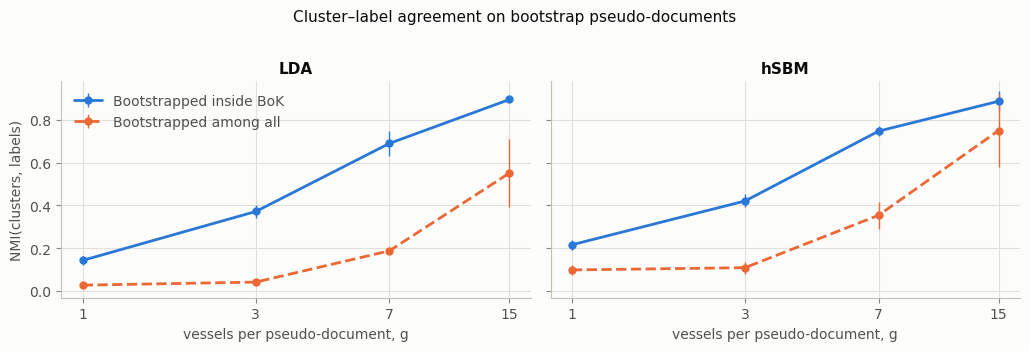

,CW,EFG,MI,LFG
training vessels,71.0,52.0,74.0,27.0
expected copies of each vessel (g = 7),9.9,13.5,9.5,25.9


In [37]:
models_run = boot["model"].unique()
fig, axes = plt.subplots(1, len(models_run), figsize=(5.2 * len(models_run), 3.4), sharey=True, squeeze=False)
for ax, name in zip(axes[0], models_run):
    for kind, color, ls in [("Bootstrapped inside BoK", pl.COLORS["CW"], "-"), ("Bootstrapped among all", pl.COLORS["EFG"], "--")]:
        s = boot[(boot["model"] == name) & (boot["labels"] == kind)].groupby("g")["NMI"]
        ax.errorbar(s.mean().index, s.mean(), yerr=s.std(), color=color, ls=ls, marker="o", ms=5,
                    capsize=0, elinewidth=1, label=kind)
    ax.set_xscale("log", base=2); ax.set_xticks([1, 3, 7, 15], [1, 3, 7, 15])
    ax.set_xlabel("vessels per pseudo-document, g"); ax.set_title(name)
axes[0][0].set_ylabel("NMI(clusters, labels)"); axes[0][0].legend(loc="upper left")
fig.suptitle("Cluster–label agreement on bootstrap pseudo-documents", y=1.02, fontsize=11)
fig.tight_layout(); pl.save(fig, "bootstrap_bias"); plt.show()
counts = pd.Series([d["culture"] for d in train_c]).value_counts().reindex(BOKS)
pd.DataFrame({"training vessels": counts, "expected copies of each vessel (g = 7)": 100 * 7 / counts}).round(1).T

### 7.2 Without the bootstrap: the hSBM on single vessels
- Each vessel is its own document: 2 326 tokens in all.
- Two models are fitted to the same network:
  - the non-overlapping hSBM (best of 5 starts, refined);
  - the **overlapping** hSBM of legacy cell 36, where each token chooses its own group, so a node can belong to several groups.
- Same network, so the description lengths are directly comparable: the lower one is the better model.
- On the bootstrap corpus the overlapping fit needs ≈ 13 000 nodes and did not finish in 15 minutes, the likely reason the legacy cell failed.

In [38]:
if RUN_SBM:
    single = [d["triplets"] for d in all_docs]
    fits = {"non-overlapping (5 starts, refined)": sbm.fit_hsbm(single, seed=SEED, n_init=5, refine_sweeps=50),
            "overlapping": sbm.fit_hsbm(single, seed=SEED, overlap=True)}
    rows = []
    for name, m in fits.items():
        for h in sbm.hierarchy(m):
            if h["doc_groups"] == 1 and h["level"] > 0:
                continue
            part = sbm.doc_partition(m, h["level"])
            rows.append({"model": name, "description length (nats)": m.mdl, **h,
                         "NMI with BoK": sbm.agreement(part, y_bok)["NMI"],
                         "NMI with culture": sbm.agreement(part, df["culture"])["NMI"]})
    display(pd.DataFrame(rows).set_index(["model", "level"]))

description length (nats)  \
model                               level                              
non-overlapping (5 starts, refined) 0                       5139.377   
                                    1                       5139.377   
overlapping                         0                       6091.855   

                                           doc_groups  word_groups  \
model                               level                            
non-overlapping (5 starts, refined) 0              10           16   
                                    1               4            7   
overlapping                         0               1            1   

                                           NMI with BoK  NMI with culture  
model                               level                                  
non-overlapping (5 starts, refined) 0             0.148             0.125  
                                    1             0.140             0.156  
overlapping                         0             0.000             0.000

**Reading.**
- The overlapping model collapses to a single group and costs ≈ 950 nats more: MDL rejects mixed membership.
- On single vessels the hSBM finds 10 vessel groups and 16 topics, only weakly related to BoK or culture (NMI ≈ 0.15). The clean separation of 5.2 needs the pooling.

### 7.3 Cross-validation with baselines
**Why folds.** Testing a model on vessels it was trained on flatters it (LDA: 0.57 in-sample vs 0.50 held out), and one split tests only 52 vessels (± 0.07). Cross-validation tests *every* vessel with a model that never saw it:
1. Deal the 88 sites into 5 folds (`N_FOLDS`), each with about a fifth of every BoK.
2. For each fold: refit every model from scratch on the other 4 folds, then predict the vessels of this fold.
3. After 5 folds, every vessel has exactly one prediction, from a model that never saw its site.
4. Repeat with 3 seeds (new folds, new bootstrap, new sampler) and pool the 3 × 276 = 828 predictions:
$$\text{accuracy}=\frac{1}{828}\sum_{r=1}^{3}\sum_{i=1}^{276}\mathbf 1\big[\arg\max_c\hat p^{(r)}(c\mid x_i)=c_i\big].$$

- **More folds, more accuracy?** Only slightly. Each model trains on $1-1/K$ of the sites: 80 % for $K=5$, 90 % for $K=10$. More folds mean a little more training data, at more cost and with smaller test folds; the method itself is not better. An earlier run with 10 folds (and the legacy stop triplets) gave accuracies within 0.02 of the ones below.
- **Seeds** move accuracies by only ≈ 0.01. The real uncertainty — which sites we happen to have — is ± 0.04–0.05 (end of 7.3).
- **Two protocols:** *sites* held out, the honest test for a new excavation; *vessels* held out, where site-mates may be in training, shown for comparison.

**Methods.** Only LDA and the two hSBM classifiers are topic models; the others are references, scored the same way. An accuracy means nothing alone: LDA's 0.50 is good against guessing the largest BoK (0.34), but not against vessel form alone (0.56).

| colour | method | what it uses | rule |
|---|---|---|---|
| grey | majority | nothing | always predict the largest BoK (middle FBW) → 0.34 |
| grey | vessel form only | form, no techniques | $p(\text{BoK}\mid\text{form})$, counted on the training vessels |
| blue | naive Bayes, triplets | the triplets directly, **no bootstrap** | $p(c\mid x)\propto\pi_c\prod_n p(w_n\mid c)$, with $p(w\mid c)$ the frequency of triplet $w$ in BoK $c$ |
| blue | Markov order 1 | the transitions (Kroon's edge weights) | $p(c\mid x)\propto\pi_c\prod_t p_c(x_{t+1}\mid x_t)$ |
| orange | LDA | the legacy pipeline (Section 4) | bootstrap pseudo-documents → 4 topics → topic matched to BoK → topic mixture of the new vessel |
| orange | hSBM, cluster classifier | the legacy pipeline (Section 5) | each document group named after its majority BoK; a vessel goes to the group under which its triplets are most likely |
| orange | hSBM, fold-in | our corrected version (5.5) | a vessel goes to the group where adding it costs the least description length |

The blue rows ask: does a topic model beat the simplest model that uses the same information without any bootstrap? Naive Bayes on triplets is LDA with one topic per BoK, counted directly.

In [39]:
def make_models(seed):
    m = {"majority": lambda: clf.Majority(),
         "vessel form only": lambda: clf.ColumnPrior("vessel_type"),
         "naive Bayes, triplets": lambda: clf.NaiveBayesNgram(),
         "Markov order 1": lambda: clf.MarkovClassifier(1, beta=2.0, grammar=grammar),
         "LDA": lambda: clf.LDAPipeline(remove_top=STOP_K, seed=seed)}
    if RUN_SBM:
        m["hSBM, cluster classifier"] = lambda: clf.SBMPipeline("clusters", remove_top=STOP_K, seed=seed)
        m["hSBM, fold-in"] = lambda: clf.SBMPipeline("fold-in", remove_top=STOP_K, seed=seed)
    return m

tables, pooled = [], {}
for seed in range(3):
    t, p = ev.compare(df, make_models(seed), n_splits=N_FOLDS, seed=seed, verbose=False)
    tables.append(t.assign(seed=seed))
    for (name, split), proba in p.items():
        pooled.setdefault((name, split), []).append(proba)
cv = pd.concat(tables)
for (name, split), probas in pooled.items():
    R.add(name, f"CV, {'sites' if split == 'site' else 'vessels'}", np.tile(y_bok, 3), np.vstack(probas))
cv_models = list(make_models(0))
R.table("CV, sites", cv_models)

,,n,accuracy,balanced_acc,macro_F1,log_loss,brier,ECE
model,protocol,,,,,,,
majority,"CV, sites",828,0.344,0.250,0.128,1.329,0.721,4.404e-04
vessel form only,"CV, sites",828,0.560,0.457,0.427,1.068,0.601,4.023e-02
"naive Bayes, triplets","CV, sites",828,0.501,0.433,0.431,1.417,0.699,2.451e-01
Markov order 1,"CV, sites",828,0.537,0.459,0.456,1.292,0.605,1.282e-01
LDA,"CV, sites",828,0.499,0.518,0.471,1.167,0.625,7.379e-02
"hSBM, cluster classifier","CV, sites",828,0.528,0.538,0.509,2.408,0.729,2.757e-01
"hSBM, fold-in","CV, sites",828,0.524,0.540,0.509,1.643,0.678,2.303e-01


**Reading** (sites held out, $n$ = 828; scores as in Section 3).
- **Accuracy:** every chain model 0.50–0.54 (Markov highest, LDA and naive Bayes lowest); form alone 0.56; majority 0.34.
- **Balanced accuracy:** the topic pipelines reach 0.52–0.54, the supervised chain models 0.43–0.46. The balanced pseudo-documents act as a uniform prior, which favours small BoKs.
- **Log-loss:** below 1.33 (the majority rule) the probabilities are informative. Naive Bayes (1.42) and both hSBM classifiers (1.64, 2.41) are worse than that, i.e. over-confident (reliability, below).

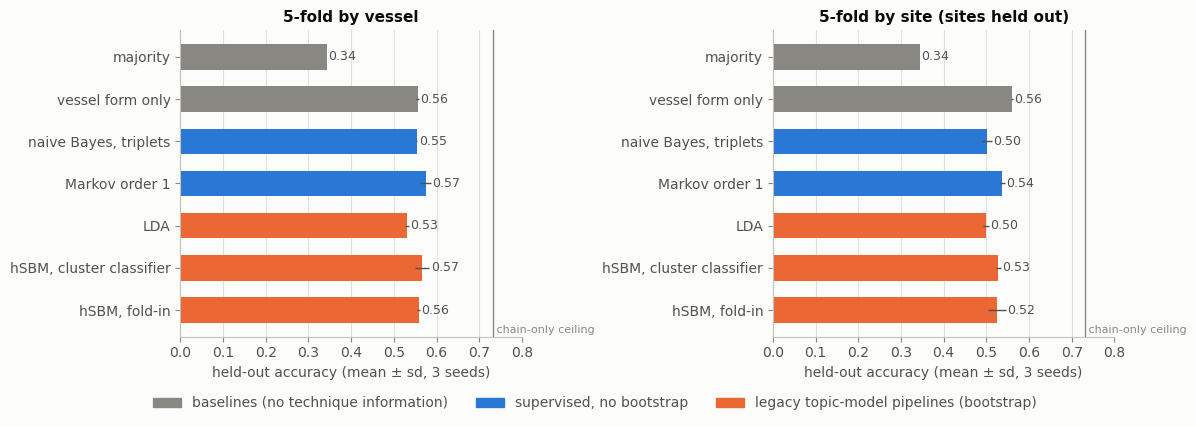

,,n,accuracy,balanced_acc,macro_F1,log_loss,brier,ECE
model,protocol,,,,,,,
majority,"CV, vessels",828,0.344,0.250,0.128,1.309,0.715,5.664e-06
vessel form only,"CV, vessels",828,0.556,0.452,0.422,1.046,0.591,3.210e-02
"naive Bayes, triplets","CV, vessels",828,0.553,0.529,0.531,1.235,0.604,1.816e-01
Markov order 1,"CV, vessels",828,0.575,0.540,0.544,1.139,0.559,6.961e-02
LDA,"CV, vessels",828,0.531,0.544,0.510,1.137,0.608,5.547e-02
"hSBM, cluster classifier","CV, vessels",828,0.566,0.567,0.551,2.277,0.667,2.428e-01
"hSBM, fold-in","CV, vessels",828,0.558,0.564,0.545,1.585,0.640,2.177e-01


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
colors = [pl.INK["muted"]] * 2 + [pl.COLORS["CW"]] * 2 + [pl.COLORS["EFG"]] * (len(cv_models) - 4)
for ax, split, title in zip(axes, ["stratified", "site"], [f"{N_FOLDS}-fold by vessel", f"{N_FOLDS}-fold by site (sites held out)"]):
    s = cv[cv["split"] == split].groupby("model")["accuracy"]
    pl.hbars(ax, cv_models, s.mean().reindex(cv_models).values, colors, xerr=s.std().reindex(cv_models).values,
             ref=ceiling["BoK (4 classes)"], ref_label="chain-only ceiling")
    ax.set_title(title); ax.set_xlabel("held-out accuracy (mean ± sd, 3 seeds)"); ax.set_xlim(0, 0.8)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=pl.INK["muted"], label="baselines (no technique information)"),
                    Patch(color=pl.COLORS["CW"], label="supervised, no bootstrap"),
                    Patch(color=pl.COLORS["EFG"], label="legacy topic-model pipelines (bootstrap)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); pl.save(fig, "cv_accuracy"); plt.show()
R.table("CV, vessels", cv_models)

**Figure `cv_accuracy`.**
- Bars: held-out accuracy, mean over the 3 seeds. Left panel: vessels held out; right panel: sites held out.
- Thin error bars: standard deviation over the seeds, ≈ 0.01. They are not the real uncertainty, which is ± 0.04–0.05.
- Vertical line: the chain-only ceiling, 0.73.
- Colours: as in the methods table.

**Table:** the scores with vessels held out. They are 3–5 points higher for the chain models (Markov 0.54 → 0.58, naive Bayes 0.50 → 0.55) and unchanged for form: that is what site-mates give away.

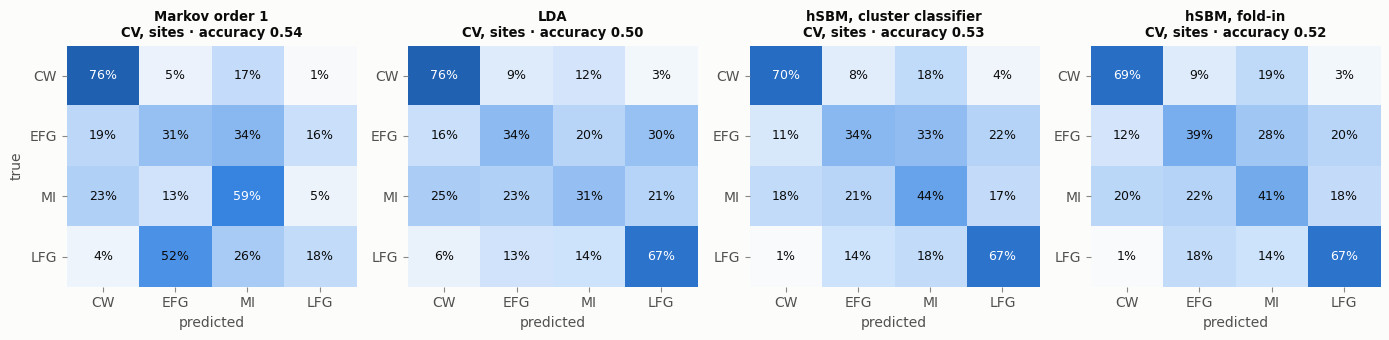

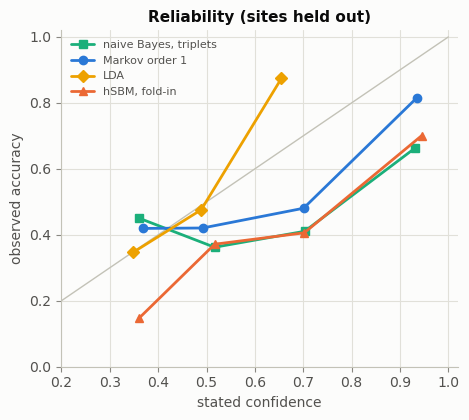

In [41]:
fig = pl.confusion_panel(R, [(m, "CV, sites") for m in ["Markov order 1"] + topic_models]); plt.show()
fig, ax = plt.subplots(figsize=(4.8, 4.3))
ax.plot([0, 1], [0, 1], color=pl.INK["axis"], lw=1)
for name, color, marker in [("naive Bayes, triplets", pl.COLORS["MI"], "s"), ("Markov order 1", pl.COLORS["CW"], "o"),
                            ("LDA", pl.COLORS["LFG"], "D")] + ([("hSBM, fold-in", pl.COLORS["EFG"], "^")] if RUN_SBM else []):
    y, p = R.proba[(name, "CV, sites")]
    conf, correct = p.max(1), p.argmax(1) == np.array([BOKS.index(v) for v in y])
    bins = np.clip((conf * 5).astype(int), 0, 4)
    keep = [b for b in range(5) if (bins == b).sum() >= 10]
    ax.plot([conf[bins == b].mean() for b in keep], [correct[bins == b].mean() for b in keep],
            color=color, marker=marker, ms=6, label=name)
ax.set_xlabel("stated confidence"); ax.set_ylabel("observed accuracy"); ax.set_xlim(0.2, 1.02); ax.set_ylim(0, 1.02)
ax.legend(loc="upper left", fontsize=8); ax.set_title("Reliability (sites held out)")
fig.tight_layout(); plt.show()

**Confusion matrices.** Rows are the true BoK and columns the predicted BoK; each row sums to 100 %, so the diagonal is each BoK's recall.
- CW is recognised best (69–76 %); middle FBW is called CW in 18–25 % of cases.
- The FBW phases are confused with each other: early FBW is right only 31–39 % of the time.
- Late FBW: the Markov model, whose prior follows the BoK sizes, recalls 18 % (and sends 52 % to early FBW); the topic models, trained on balanced pseudo-documents, recall 67 %. The price is middle FBW: Markov 59 %, the topic models 31–44 %.

**Reliability diagram: how it is computed.**
1. For each of the 828 predictions, take the stated confidence $\hat q_i=\max_c\hat p(c\mid x_i)$ and whether it is correct, $y_i=\mathbf 1[\arg\max_c\hat p(c\mid x_i)=c_i]$.
2. Sort the predictions into bins of width 0.2 by $\hat q_i$, and keep the bins with at least 10 predictions.
3. In each bin $b$: $x_b$ = mean stated confidence; $y_b$ = observed accuracy, the share of correct predictions.
4. Plot $y_b$ against $x_b$. The diagonal $y=x$ is perfect calibration.

**What it means.**
- **Calibrated** ($y_b\approx x_b$): of the vessels attributed with 70 % confidence, about 70 % are right, so the probabilities can be taken at face value.
- **Over-confident** ($y_b<x_b$, below the diagonal): the model claims more certainty than it has. Naive Bayes and the hSBM say 0.93–0.95 and are right 0.66 and 0.70 of the time; the Markov model says 0.94 and is right 0.82.
- **Under-confident** ($y_b>x_b$, above the diagonal): the model is right more often than it claims. LDA's top bin says 0.66 and is right 0.87.
- The ECE of Section 3 sums up the same picture in one number: $\mathrm{ECE}=\sum_b\frac{n_b}{n}\,\lvert y_b-x_b\rvert$, over 10 bins of width 0.1.

**Why LDA is under-confident.** Its "observed accuracy" in the diagram is not its overall accuracy, which is 0.50.
- Its three bins: 245 predictions at confidence ≈ 0.35 (right 35 %), 456 at ≈ 0.49 (48 %), 127 at ≈ 0.66 (87 %).
- LDA's fold-in gives $\theta_k=(n_k+\alpha)/(N+K\alpha)$ (4.7). Even if all $N$ tokens of a vessel point to one topic,
$$\max_c\hat p(c\mid x)\le\frac{N+\alpha}{N+K\alpha}=\frac{N+1}{N+4}\qquad(\alpha=1,\ K=4).$$
- A test vessel has $N\approx9$ triplets (at most 13), so LDA's confidence is capped near $10/13\approx0.77$, and never above 0.82; the largest observed is 0.74. The prior's 4 pseudo-counts weigh almost half as much as the vessel's own evidence.
- So LDA is cautious, not unusually accurate. Its low ECE hides this, because only 15 % of its predictions are in the confident bin. A temperature fitted on the training folds would sharpen its probabilities without changing its decisions. Lowering $\alpha$ lifts the cap; 7.6 tests it.

**In short.**
- The Markov chain is the best chain model (0.54); the topic-model pipelines reach 0.50–0.53. No chain model beats vessel form alone (0.56) beyond noise.
- Naive Bayes and the hSBM are over-confident, because they count overlapping triplets as independent evidence (Section 2). LDA is under-confident.
- The errors are mostly among the FBW phases, and the class balance decides which phase is favoured.

**Why did the legacy notebook report 64 %?** Its `evaluate_classifier_on_all_docs` (legacy cell 85) scored the hSBM cluster classifier on all 276 vessels. But the model had been fitted on `create_resampled_documents(all_docs, group_size=7)`: pseudo-documents built from those same vessels, each copied 10–26 times. Every test vessel was part of the training data, so the score is in-sample. The figure puts the legacy confusion matrix (counts copied from its output) next to ours:
- **Legacy, in-sample: 0.64.** Recall CW 75 %, early FBW 65 %, middle FBW 52 %, late FBW 70 %.
- **Here, the same protocol: 0.62.** Same model and protocol; the legacy figure is reproduced (recall 39–84 %).
- **Here, sites held out: 0.53.** Early FBW drops most (58 → 34 %), then CW (84 → 70 %).

So our accuracy is lower not because the model is worse, but because each vessel is scored by a model that never saw it or its site. The 9–11 points are what memorising the training vessels was worth. Two smaller differences: the legacy fit was unseeded (one random partition), and it removed the 5 stop triplets.

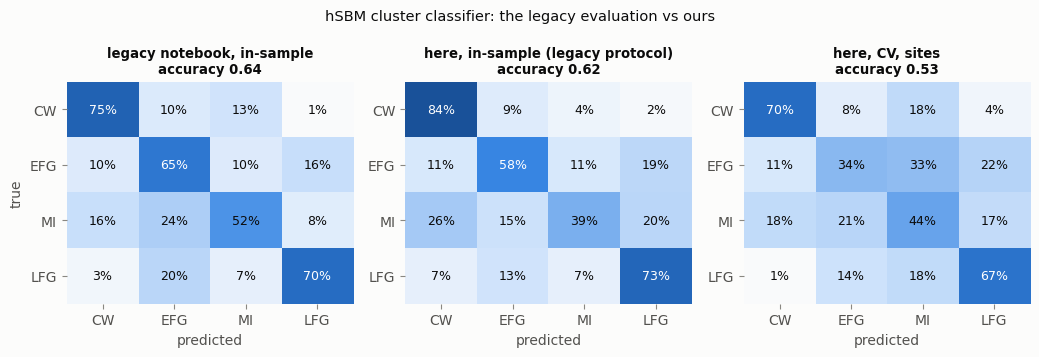

In [42]:
# Legacy evaluation (Old_code/Presentation_topic_modelling.ipynb, cell 85, `evaluate_classifier_on_all_docs`): the cluster
# classifier fitted on pseudo-documents built from ALL 276 vessels (g = 7), then scored on the same 276 vessels.
legacy_order = ["CW", "EFG", "LFG", "MI"]                      # row and column order of the legacy output
legacy_counts = pd.DataFrame([[67, 9, 1, 12], [6, 40, 10, 6], [1, 6, 21, 2], [15, 23, 8, 49]],
                             index=legacy_order, columns=legacy_order).loc[BOKS, BOKS].values
if RUN_SBM:
    acc = R.table()["accuracy"]
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))
    pl.confusion(axes[0], legacy_counts / legacy_counts.sum(1, keepdims=True))
    axes[0].set_title(f"legacy notebook, in-sample\naccuracy {np.trace(legacy_counts) / legacy_counts.sum():.2f}", fontsize=9.5)
    for ax, protocol in zip(axes[1:], ["in-sample (legacy protocol)", "CV, sites"]):
        pl.confusion(ax, R.confusion("hSBM, cluster classifier", protocol)); ax.set_ylabel("")
        ax.set_title(f"here, {protocol}\naccuracy {acc[('hSBM, cluster classifier', protocol)]:.2f}", fontsize=9.5)
    fig.suptitle("hSBM cluster classifier: the legacy evaluation vs ours", fontsize=10.5)
    fig.tight_layout(); plt.show()

**How large is the noise?** Vessels of one site resemble each other, so we resample *sites*:
- draw the 88 sites with replacement, 2000 times, and recompute every score; the spread of the recomputed values is the standard error (se);
- compare two models on the same draws (paired): $z$ = difference / se, and $|z|\gtrsim2$ means a difference beyond noise.

In [43]:
def site_bootstrap(models, pairs=(), protocol="CV, sites", B=2000, seed=SEED):
    """Uncertainty of cross-validated scores when whole sites are resampled with replacement (the vessels of a site
    move together). Each vessel's hit (0/1) and −ln p(true BoK) are first averaged over the 3 seeds. Paired
    differences use the same draws for both models."""
    names = list(dict.fromkeys(list(models) + [m for pair in pairs for m in pair]))
    y_idx = np.array([BOKS.index(c) for c in y_bok])
    hit, nll = {}, {}
    for m in names:
        p = R.proba[(m, protocol)][1].reshape(-1, len(df), len(BOKS))          # seeds × vessels × BoKs
        hit[m] = (p.argmax(2) == y_idx).mean(0)
        nll[m] = -np.log(np.clip(p[:, np.arange(len(df)), y_idx], 1e-6, 1)).mean(0)
    sites = list(df.groupby("site_id").indices.values())
    rng = np.random.default_rng(seed)
    draws = [np.concatenate([sites[k] for k in rng.integers(len(sites), size=len(sites))]) for _ in range(B)]
    se = lambda v: np.std([v[d].mean() for d in draws])
    single = pd.DataFrame({("accuracy", "mean"): {m: hit[m].mean() for m in models},
                           ("accuracy", "se"): {m: se(hit[m]) for m in models},
                           ("log-loss", "mean"): {m: nll[m].mean() for m in models},
                           ("log-loss", "se"): {m: se(nll[m]) for m in models}})
    paired = pd.DataFrame({f"{a}  −  {b}": {("Δ accuracy", "mean"): (hit[a] - hit[b]).mean(),
                                             ("Δ accuracy", "se"): se(hit[a] - hit[b]),
                                             ("Δ accuracy", "z"): (hit[a] - hit[b]).mean() / se(hit[a] - hit[b]),
                                             ("Δ log-loss", "mean"): (nll[a] - nll[b]).mean(),
                                             ("Δ log-loss", "se"): se(nll[a] - nll[b])} for a, b in pairs}).T
    return single, paired

pairs = [("LDA", "Markov order 1"), ("hSBM, fold-in", "LDA"), ("Markov order 1", "vessel form only"),
         ("Markov order 1", "majority"), ("vessel form only", "majority")]
single, paired = site_bootstrap(cv_models, [p for p in pairs if set(p) <= set(cv_models)])
print(f"{df['site_id'].nunique()} sites, 2000 bootstrap draws")
display(single.round(3))
paired.round(3)

88 sites, 2000 bootstrap draws


accuracy        log-loss       
                             mean     se     mean     se
majority                    0.344  0.082    1.329  0.073
vessel form only            0.560  0.049    1.068  0.060
naive Bayes, triplets       0.501  0.041    1.417  0.116
Markov order 1              0.537  0.044    1.292  0.135
LDA                         0.499  0.043    1.167  0.050
hSBM, cluster classifier    0.528  0.040    2.408  0.280
hSBM, fold-in               0.524  0.039    1.643  0.159

Δ accuracy               Δ log-loss       
                                          mean     se      z       mean     se
LDA  −  Markov order 1                  -0.039  0.056 -0.688     -0.125  0.123
hSBM, fold-in  −  LDA                    0.025  0.020  1.260      0.476  0.129
Markov order 1  −  vessel form only     -0.023  0.039 -0.592      0.224  0.117
Markov order 1  −  majority              0.193  0.078  2.482     -0.037  0.118
vessel form only  −  majority            0.216  0.096  2.246     -0.261  0.059

**Reading.**
- **se of accuracy:** ± 0.04 for the chain models; ± 0.08 for the majority rule, because the class mix varies between sites.
- **No chain model beats another, or form alone:** hSBM fold-in − LDA +0.03 ± 0.02 ($z$ = 1.3); LDA − Markov −0.04 ± 0.06; Markov − form −0.02 ± 0.04. (With 10 folds and the legacy stop triplets, the hSBM fold-in had beaten LDA by +0.05 ± 0.02, $z$ = 2.6; with every triplet kept the gap halves.)
- **Markov and form beat the majority rule** by 0.19–0.22 ($z$ ≈ 2.2–2.5).
- **Calibration differences are real:** the hSBM's log-loss is 0.48 ± 0.13 worse than LDA's ($z$ ≈ 3.7).
- **Caveat:** sites are treated as independent; if neighbouring sites share more, these standard errors are too small.

### 7.4 Sensitivity to the legacy choices
- (a) The pseudo-document size $g$ ($g=1$: no pooling) and the stop triplets, for LDA and the hSBM fold-in (sites held out, seed 0).
- (b) The deletion rule itself: frequency or information (4.1).

In [44]:
rows = []
other_k = 5 if STOP_K == 0 else 0                     # the other stop-triplet choice, at g = 7
for g, k in [(1, STOP_K), (3, STOP_K), (7, STOP_K), (15, STOP_K), (7, other_k)]:
    cand = {"LDA": lambda g=g, k=k: clf.LDAPipeline(g=g, remove_top=k, seed=SEED)}
    if RUN_SBM:
        cand["hSBM, fold-in"] = lambda g=g, k=k: clf.SBMPipeline("fold-in", g=g, remove_top=k, seed=SEED)
    for name, mk in cand.items():
        p = ev.cross_val_proba(df, mk, "site", N_FOLDS, SEED)
        rows.append({"model": name, "stop triplets removed": k, "g": g, **ev.scores(y_bok, p)})
pd.DataFrame(rows).set_index(["model", "stop triplets removed", "g"])[["accuracy", "balanced_acc", "log_loss", "ECE"]]

,,,accuracy,balanced_acc,log_loss,ECE
model,stop triplets removed,g,,,,
LDA,0,1,0.453,0.479,1.264,0.061
"hSBM, fold-in",0,1,0.489,0.484,1.795,0.087
LDA,0,3,0.475,0.487,1.217,0.037
"hSBM, fold-in",0,3,0.482,0.500,1.311,0.130
LDA,0,7,0.496,0.516,1.157,0.086
"hSBM, fold-in",0,7,0.500,0.527,1.616,0.244
LDA,0,15,0.514,0.530,1.152,0.120
"hSBM, fold-in",0,15,0.489,0.513,2.032,0.301
LDA,5,7,0.511,0.527,1.176,0.102


**Reading (a).** One seed, so each accuracy is uncertain by ± 0.04–0.05.
- **Pooling:** LDA rises from 0.45 at $g=1$ to 0.51 at $g=15$, about one standard error; the hSBM stays at 0.48–0.50. With 10 folds and the legacy stop triplets the trends were the other way round (LDA flat, hSBM rising): single-seed differences of this size are noise.
- **Larger $g$ makes the hSBM more over-confident** (log-loss 1.3 at $g=3$ → 2.0 at $g=15$; ECE 0.13 → 0.30).
- **Stop triplets:** removing the legacy five changes accuracy by +0.02 (LDA 0.50 → 0.51, hSBM 0.50 → 0.52) at $g=7$.

**(b) Frequency or information?** The LDA pipeline with five deletion rules, each decided on the training vessels of every fold:
- nothing removed;
- the 5 most frequent triplets removed (legacy);
- the 10, or the 30, least informative removed (MI − chance, 4.1);
- only the informative triplets kept ($q<0.05$).

Sites held out, 3 × 5-fold; each rule is paired against "nothing removed".

In [45]:
class LDASelect(clf.LDAPipeline):
    """The LDA pipeline of Section 4 with a different deletion rule, decided on the training vessels of each fold:
    an integer k removes the k triplets with the least information about the BoK (MI − chance, 4.1);
    "informative only" keeps just the triplets with q < 0.05."""
    def __init__(self, rule, seed=0):
        super().__init__(remove_top=0, seed=seed)
        self.rule = rule

    def fit(self, df):
        docs = tm.load_pottery_data(df)
        info = triplet_information(docs, seed=self.seed)
        if self.rule == "informative only":
            self.removed = list(info.index[info["q"] >= 0.05])
        else:
            self.removed = list(info.sort_values("MI − chance (bits)").index[:self.rule])
        drop = set(self.removed)
        docs = [{**d, "triplets": [t for t in d["triplets"] if t not in drop]} for d in docs]
        self.vocabulary, _ = tm.extract_vocabulary(docs)
        pdocs = tm.create_resampled_documents(docs, self.g, self.n_per_class, self.seed)
        X_, _ = tm.build_dtm_with_external_vocab(pdocs, {w: i for i, w in enumerate(self.vocabulary)})
        self.lda = tm.LDA_manual(len(self.classes), self.alpha, self.beta, self.n_iter, self.seed).fit(X_, self.vocabulary)
        emp = tm.get_empirical_word_distribution(docs, self.vocabulary, self.classes)
        self.mapping, _ = tm.matching_empirical(emp, self.lda.topic_word_dist, self.classes)
        return self

deletion = {"LDA, nothing removed": lambda s: LDASelect(0, s),
            "LDA, 5 most frequent removed (legacy)": lambda s: clf.LDAPipeline(remove_top=5, seed=s),
            "LDA, 10 least informative removed": lambda s: LDASelect(10, s),
            "LDA, 30 least informative removed": lambda s: LDASelect(30, s),
            "LDA, informative triplets only": lambda s: LDASelect("informative only", s)}
for name, make in deletion.items():
    probas = [ev.cross_val_proba(df, lambda: make(seed), "site", N_FOLDS, seed) for seed in range(3)]
    R.add(name, "CV, sites", np.tile(y_bok, 3), np.vstack(probas))
display(R.table("CV, sites", list(deletion))[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]])
_, paired_del = site_bootstrap([], [(name, "LDA, nothing removed") for name in list(deletion)[1:]])
paired_del.round(3)

,,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,protocol,,,,,
"LDA, nothing removed","CV, sites",0.499,0.518,0.471,1.167,0.074
"LDA, 5 most frequent removed (legacy)","CV, sites",0.510,0.524,0.486,1.180,0.085
"LDA, 10 least informative removed","CV, sites",0.522,0.536,0.496,1.157,0.058
"LDA, 30 least informative removed","CV, sites",0.504,0.521,0.480,1.173,0.074
"LDA, informative triplets only","CV, sites",0.452,0.483,0.434,1.205,0.094


Δ accuracy  \
                                                                     mean   
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed      0.011   
LDA, 10 least informative removed  −  LDA, nothing removed          0.023   
LDA, 30 least informative removed  −  LDA, nothing removed          0.005   
LDA, informative triplets only  −  LDA, nothing removed            -0.047   

                                                                              \
                                                                   se      z   
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed  0.010  1.082   
LDA, 10 least informative removed  −  LDA, nothing removed      0.008  2.931   
LDA, 30 least informative removed  −  LDA, nothing removed      0.012  0.395   
LDA, informative triplets only  −  LDA, nothing removed         0.021 -2.218   

                                                               Δ log-loss  \
                                                                     mean   
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed      0.013   
LDA, 10 least informative removed  −  LDA, nothing removed         -0.009   
LDA, 30 least informative removed  −  LDA, nothing removed          0.006   
LDA, informative triplets only  −  LDA, nothing removed             0.039   

                                                                       
                                                                   se  
LDA, 5 most frequent removed (legacy)  −  LDA, nothing removed  0.010  
LDA, 10 least informative removed  −  LDA, nothing removed      0.005  
LDA, 30 least informative removed  −  LDA, nothing removed      0.009  
LDA, informative triplets only  −  LDA, nothing removed         0.022

**Reading (b).**

| rule | accuracy | vs nothing removed |
|---|---|---|
| nothing removed | 0.50 | — |
| 5 most frequent (legacy) | 0.51 | +0.01 ± 0.01 ($z$ = 1.1) |
| 10 least informative | 0.52 | +0.02 ± 0.01 ($z$ = 2.9) |
| 30 least informative | 0.50 | +0.01 ± 0.01 ($z$ = 0.4) |
| informative only | 0.45 | −0.05 ± 0.02 ($z$ = −2.2) |

- Removing the 10 least informative gains 2 points here, as it did in an earlier 5-fold run; with 10 folds the same rule gave +0.01 ± 0.01 ($z$ = 1.0). A gain that depends on how the sites are dealt into folds is small at best.
- Keeping only the significant triplets loses 5 points: it drops the 46 rare ones, which no test can judge one by one but which together carry information.
- **So:** deleting triplets gains at most a point or two. Keep them, or delete only what is clearly uninformative, deciding it inside the training data. The switch is `STOP_K` in the setup cell; `STOP_K = 0` keeps every triplet.

### 7.5 Vessel form
**CW vs FBW**, the two-class question of the thesis, with sites held out ("site") and vessels held out ("stratified"):

In [46]:
two = ["CW", "FBW"]
t2, _ = ev.compare(df, {
    "majority": lambda: clf.Majority(two, "culture"),
    "vessel form only": lambda: clf.ColumnPrior("vessel_type", two, "culture"),
    "naive Bayes, triplets": lambda: clf.NaiveBayesNgram(classes=two, label="culture"),
    "Markov order 1": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar, classes=two, label="culture"),
    "Markov order 1 + form prior": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar, classes=two,
                                                                label="culture", prior_column="vessel_type"),
}, classes=two, label="culture", n_splits=N_FOLDS, seed=SEED, verbose=False)
print(f"chain-only ceiling: {ceiling['culture (CW vs FBW)']:.3f}")
t2.pivot(index="model", columns="split", values=["accuracy", "balanced_acc"])

chain-only ceiling: 0.888


accuracy            balanced_acc           
split                           site stratified         site stratified
model                                                                  
Markov order 1                 0.808      0.804        0.773      0.761
Markov order 1 + form prior    0.822      0.826        0.822      0.819
majority                       0.678      0.678        0.500      0.500
naive Bayes, triplets          0.801      0.822        0.779      0.789
vessel form only               0.804      0.804        0.835      0.835

**Reading.**
- Majority 0.68; chain models 0.80–0.82; chain + form 0.82–0.83.
- Form alone reaches 0.80, with the highest balanced accuracy (0.84).
- The differences among the non-trivial models (≤ 0.03) are within noise.

→ "Beaker or not" says about as much about CW as the whole chaîne opératoire.

**Does the chain add anything beyond form?** Four BoKs. In the Markov model, replace the prior $p(\text{BoK})$ by $p(\text{BoK}\mid\text{form})$: the gain over form alone is what the chain says *given* the form.

In [47]:
t3, _ = ev.compare(df, {
    "vessel form only": lambda: clf.ColumnPrior("vessel_type"),
    "Markov order 1": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar),
    "Markov order 1 + form prior": lambda: clf.MarkovClassifier(1, 2.0, grammar=grammar, prior_column="vessel_type"),
}, n_splits=N_FOLDS, seed=SEED, verbose=False)
t3.pivot(index="model", columns="split", values=["accuracy", "balanced_acc", "log_loss"])

accuracy            balanced_acc             \
split                           site stratified         site stratified   
model                                                                     
Markov order 1                 0.533      0.576        0.455      0.550   
Markov order 1 + form prior    0.580      0.616        0.547      0.610   
vessel form only               0.562      0.551        0.457      0.447   

                            log_loss             
split                           site stratified  
model                                            
Markov order 1                 1.288      1.079  
Markov order 1 + form prior    1.198      1.019  
vessel form only               1.064      1.048

**Reading** (chain + form minus form alone):

| | sites held out | vessels held out |
|---|---|---|
| accuracy | +0.02 | +0.07 |
| balanced accuracy | +0.09 | +0.16 |
| log-loss | +0.13 (worse) | −0.03 |

- The balanced-accuracy gain, which comes from the FBW phases, is the clearer signal; with sites held out, accuracy hardly changes.
- On unseen sites the combined probabilities are worse than form alone: the over-confident Markov likelihood sharpens wrong predictions too.

→ The chaîne opératoire carries information beyond form, mainly for separating the FBW phases. Chain and form are treated as independent given the BoK, which is an approximation.

### 7.6 Can the attribution be improved? The prior, the transitions, learned weights
Three changes, cross-validated like 7.3 (sites held out, 3 seeds × `N_FOLDS` folds):

1. **The Dirichlet prior at fold-in.** LDA's confidence is capped at $(N+\alpha)/(N+K\alpha)$ (7.3), because the prior adds $\alpha$ pseudo-counts to every topic. Lowering $\alpha$ at fold-in only, with the topics still fitted at $\alpha=1$, lifts the cap: for $N=9$, $\alpha=1$ gives $0.77$, $\alpha=0.3$ gives $0.91$ and $\alpha=0.1$ gives $0.97$.
   - In the code: `pipe.lda.alpha = a` after fitting changes the fold-in only; `clf.LDAPipeline(alpha=a)` changes the fit as well.
2. **Adding the transition probabilities.** LDA's bag of triplets and the Markov chain (Kroon's transitions) read the same chain in two ways. Combine them as a product of experts whose weights sum to 1:
$$\log\hat p(c\mid x)=w\,\log\hat p_{\rm LDA}(c\mid x)+(1-w)\,\log\hat p_{\rm Markov}(c\mid x)+\text{const},\qquad w=\tfrac12.$$
   - Weights summing to 1 avoid counting the same evidence twice; a plain product $\hat p_{\rm LDA}\,\hat p_{\rm Markov}$ would square it and be over-confident.
   - $w$ is fixed in advance, not tuned on the test vessels.
3. **Weighting the informative transitions.** Bayes' rule already weights each transition by how well it separates two BoKs:
$$\log\frac{\hat p(c\mid x)}{\hat p(c'\mid x)}=\log\frac{\pi_c}{\pi_{c'}}+\sum_t\underbrace{\log\frac{p_c(x_{t+1}\mid x_t)}{p_{c'}(x_{t+1}\mid x_t)}}_{\text{weight of the transition }x_t\to x_{t+1}}.$$
   A transition used alike by both BoKs has weight 0 (the Lemma of 4.1); one typical of $c$ has a large weight. So weighting by $p(x_{t+1}\mid x_t)$ *is* the Markov classifier of 7.3. Its weights are counted one BoK at a time, not chosen to separate the BoKs, and overlapping evidence is counted more than once.
   - **Learned weights** (maximum entropy, i.e. multinomial logistic regression): with $n_w(x)$ the number of times transition — or triplet — $w$ occurs in the vessel,
$$\log\hat p(c\mid x)=b_c+\sum_w n_w(x)\,\theta_{c,w}-\log Z(x),$$
     fitted on the training sites by maximising $\sum_i\log\hat p(c_i\mid x_i)-\frac1{2C}\sum_{c,w}\theta_{c,w}^2$. The strength $C$ of the Gaussian prior is chosen by an inner 5-fold cross-validation on log-loss.
   - With transitions as features, the Markov classifier is the special case $\theta_{c,(a,b)}=\log p_c(b\mid a)$ (up to start and end terms). Learned weights can shrink redundant or noisy evidence, which is what over-confidence comes from.

In [48]:
class LDAFoldAlpha(clf.LDAPipeline):
    """The LDA pipeline of Sections 4 and 7.3; only the Dirichlet prior α of the fold-in is changed after fitting."""
    def __init__(self, fold_alpha, seed=0):
        super().__init__(remove_top=STOP_K, seed=seed)
        self.fold_alpha = fold_alpha
    def fit(self, df):
        super().fit(df)
        self.lda.alpha = self.fold_alpha
        return self

class Blend:
    """Product of experts: log p = w log p_A + (1 − w) log p_B + const."""
    def __init__(self, a, b, w=0.5):
        self.a, self.b, self.w = a, b, w
    def fit(self, df):
        self.a.fit(df); self.b.fit(df)
        return self
    def predict_proba(self, df):
        return softmax_rows(self.w * np.log(np.clip(self.a.predict_proba(df), 1e-12, 1))
                            + (1 - self.w) * np.log(np.clip(self.b.predict_proba(df), 1e-12, 1)))

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

class LearnedWeights:
    """Maximum-entropy (multinomial logistic) classifier on n-gram counts: log p(c | x) = Σ_w n_w(x) θ_{c,w} − log Z(x).
    The weights θ are learned to separate the BoKs, with a Gaussian (L2) prior chosen by inner 5-fold CV on log-loss."""
    def __init__(self, n, seed=0):
        self.n, self.seed = n, seed
    def tokens(self, part):
        return data.documents(part, self.n)
    def _X(self, part):
        X_ = np.zeros((len(part), len(self.col)))
        for i, toks in enumerate(self.tokens(part)):
            for t in toks:
                if t in self.col:
                    X_[i, self.col[t]] += 1
        return X_
    def fit(self, part):
        self.col = {t: j for j, t in enumerate(sorted({t for d in self.tokens(part) for t in d}))}
        cv = StratifiedKFold(5, shuffle=True, random_state=self.seed)
        self.model = GridSearchCV(LogisticRegression(max_iter=5000), {"C": [0.03, 0.1, 0.3, 1, 3, 10]},
                                  scoring="neg_log_loss", cv=cv).fit(self._X(part), part["bok"].astype(str))
        return self
    def predict_proba(self, part):
        p = self.model.predict_proba(self._X(part))
        return p[:, [list(self.model.classes_).index(c) for c in BOKS]]

markov1 = lambda: clf.MarkovClassifier(1, beta=2.0, grammar=grammar)
improve = {"LDA (α = 1, as in 7.3)": lambda s: clf.LDAPipeline(remove_top=STOP_K, seed=s),
           "LDA, fold-in α = 0.3": lambda s: LDAFoldAlpha(0.3, s),
           "LDA, fold-in α = 0.1": lambda s: LDAFoldAlpha(0.1, s),
           "Markov order 1": lambda s: markov1(),
           "LDA × Markov (w = ½)": lambda s: Blend(clf.LDAPipeline(remove_top=STOP_K, seed=s), markov1()),
           "LDA with fold-in α = 0.1 × Markov (w = ½)": lambda s: Blend(LDAFoldAlpha(0.1, s), markov1()),
           "learned weights, transitions": lambda s: LearnedWeights(2, s),
           "learned weights, triplets": lambda s: LearnedWeights(3, s)}
for name, make in improve.items():
    probas = [ev.cross_val_proba(df, lambda: make(seed), "site", N_FOLDS, seed) for seed in range(3)]
    R.add(name, "CV, sites (7.6)", np.tile(y_bok, 3), np.vstack(probas))
display(R.table("CV, sites (7.6)", list(improve))[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]])
names = list(improve)
_, paired76 = site_bootstrap([], [(n, names[0]) for n in names[1:3] + names[4:]] + [(names[4], names[3]), (names[6], names[3])],
                             protocol="CV, sites (7.6)")
paired76.round(3)

,,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,protocol,,,,,
"LDA (α = 1, as in 7.3)","CV, sites (7.6)",0.499,0.518,0.471,1.167,0.074
"LDA, fold-in α = 0.3","CV, sites (7.6)",0.500,0.519,0.474,1.226,0.142
"LDA, fold-in α = 0.1","CV, sites (7.6)",0.489,0.510,0.468,1.436,0.260
Markov order 1,"CV, sites (7.6)",0.537,0.459,0.456,1.292,0.128
LDA × Markov (w = ½),"CV, sites (7.6)",0.559,0.544,0.533,1.113,0.101
LDA with fold-in α = 0.1 × Markov (w = ½),"CV, sites (7.6)",0.540,0.547,0.520,1.233,0.181
"learned weights, transitions","CV, sites (7.6)",0.535,0.451,0.450,1.044,0.062
"learned weights, triplets","CV, sites (7.6)",0.540,0.456,0.458,1.050,0.075


Δ accuracy  \
                                                                           mean   
LDA, fold-in α = 0.3  −  LDA (α = 1, as in 7.3)                           0.001   
LDA, fold-in α = 0.1  −  LDA (α = 1, as in 7.3)                          -0.010   
LDA × Markov (w = ½)  −  LDA (α = 1, as in 7.3)                           0.060   
LDA with fold-in α = 0.1 × Markov (w = ½)  −  LDA (α = 1, as in 7.3)      0.041   
learned weights, transitions  −  LDA (α = 1, as in 7.3)                   0.036   
learned weights, triplets  −  LDA (α = 1, as in 7.3)                      0.041   
LDA × Markov (w = ½)  −  Markov order 1                                   0.022   
learned weights, transitions  −  Markov order 1                          -0.002   

                                                                             \
                                                                         se   
LDA, fold-in α = 0.3  −  LDA (α = 1, as in 7.3)                       0.003   
LDA, fold-in α = 0.1  −  LDA (α = 1, as in 7.3)                       0.007   
LDA × Markov (w = ½)  −  LDA (α = 1, as in 7.3)                       0.026   
LDA with fold-in α = 0.1 × Markov (w = ½)  −  LDA (α = 1, as in 7.3)  0.017   
learned weights, transitions  −  LDA (α = 1, as in 7.3)               0.056   
learned weights, triplets  −  LDA (α = 1, as in 7.3)                  0.057   
LDA × Markov (w = ½)  −  Markov order 1                               0.036   
learned weights, transitions  −  Markov order 1                       0.011   

                                                                             \
                                                                          z   
LDA, fold-in α = 0.3  −  LDA (α = 1, as in 7.3)                       0.446   
LDA, fold-in α = 0.1  −  LDA (α = 1, as in 7.3)                      -1.370   
LDA × Markov (w = ½)  −  LDA (α = 1, as in 7.3)                       2.280   
LDA with fold-in α = 0.1 × Markov (w = ½)  −  LDA (α = 1, as in 7.3)  2.445   
learned weights, transitions  −  LDA (α = 1, as in 7.3)               0.649   
learned weights, triplets  −  LDA (α = 1, as in 7.3)                  0.721   
LDA × Markov (w = ½)  −  Markov order 1                               0.599   
learned weights, transitions  −  Markov order 1                      -0.217   

                                                                     Δ log-loss  \
                                                                           mean   
LDA, fold-in α = 0.3  −  LDA (α = 1, as in 7.3)                           0.059   
LDA, fold-in α = 0.1  −  LDA (α = 1, as in 7.3)                           0.269   
LDA × Markov (w = ½)  −  LDA (α = 1, as in 7.3)                          -0.054   
LDA with fold-in α = 0.1 × Markov (w = ½)  −  LDA (α = 1, as in 7.3)      0.066   
learned weights, transitions  −  LDA (α = 1, as in 7.3)                  -0.122   
learned weights, triplets  −  LDA (α = 1, as in 7.3)                     -0.117   
LDA × Markov (w = ½)  −  Markov order 1                                  -0.180   
learned weights, transitions  −  Markov order 1                          -0.248   

                                                                             
                                                                         se  
LDA, fold-in α = 0.3  −  LDA (α = 1, as in 7.3)                       0.033  
LDA, fold-in α = 0.1  −  LDA (α = 1, as in 7.3)                       0.066  
LDA × Markov (w = ½)  −  LDA (α = 1, as in 7.3)                       0.065  
LDA with fold-in α = 0.1 × Markov (w = ½)  −  LDA (α = 1, as in 7.3)  0.071  
learned weights, transitions  −  LDA (α = 1, as in 7.3)               0.065  
learned weights, triplets  −  LDA (α = 1, as in 7.3)                  0.066  
LDA × Markov (w = ½)  −  Markov order 1                               0.059  
learned weights, transitions  −  Markov order 1                       0.088

**Reading** (sites held out, 3 × 5-fold; Δ = paired site bootstrap against LDA with α = 1):

| model | accuracy | log-loss | ECE | Δ accuracy |
|---|---|---|---|---|
| LDA (α = 1) | 0.50 | 1.17 | 0.07 | — |
| fold-in α = 0.3 | 0.50 | 1.23 | 0.14 | +0.00 ± 0.00 |
| fold-in α = 0.1 | 0.49 | 1.44 | 0.26 | −0.01 ± 0.01 ($z$ = −1.4) |
| Markov order 1 | 0.54 | 1.29 | 0.13 | |
| LDA × Markov | **0.56** | 1.11 | 0.10 | +0.06 ± 0.03 ($z$ = 2.3) |
| fold-in α = 0.1 × Markov | 0.54 | 1.23 | 0.18 | +0.04 ± 0.02 ($z$ = 2.4) |
| learned weights, transitions | 0.54 | **1.04** | 0.06 | +0.04 ± 0.06 ($z$ = 0.6) |
| learned weights, triplets | 0.54 | 1.05 | 0.08 | +0.04 ± 0.06 ($z$ = 0.7) |

- **Lowering α** does not help: accuracy 0.49–0.50, and worse probabilities (log-loss 1.17 → 1.44, ECE 0.07 → 0.26). Removing the prior's caution turns an under-confident model into an over-confident one; α = 1 is the better compromise.
- **Adding the transitions** (LDA × Markov) gains 6 points over LDA and is the most accurate chain model here (0.56). Against the Markov chain alone it gains +0.02 ± 0.04 in accuracy and −0.18 ± 0.06 in log-loss.
- **Learned weights** make the same decisions as the Markov chain (transitions: −0.002 ± 0.011), but give the best probabilities of all chain models: log-loss 1.04, 0.25 ± 0.09 better than Markov ($z$ ≈ −2.8), ECE 0.06 — better even than vessel form alone (1.07). Learning the weights cures the over-counting, not the decisions. Triplets as features do no better than transitions. Their balanced accuracy (0.45) follows the class sizes, like Markov.
- **So:** the information is in the transitions. Weighting them well gives honest probabilities; combining them with LDA gives the best accuracy. Both stay within noise of vessel form alone (0.56) in accuracy.

### 7.7 Co-occurrence: matrices, classification and the biterm topic model
A chain forgets nothing; a **bag of techniques** forgets the order and keeps only which techniques were used together. No technique is repeated within a chain (Section 9), so vessel $v$ is a 0/1 vector $x_v$, with $x_{vi}=1$ if it uses technique $i$. The **co-occurrence matrix** of BoK $c$ is
$$C_c(i,j)=\frac1{n_c}\sum_{v\in c}x_{vi}\,x_{vj},$$
the share of its vessels that use both $i$ and $j$; the diagonal $C_c(i,i)$ is the share that uses $i$. Eight techniques are in (almost) every vessel and are left out of the figure.

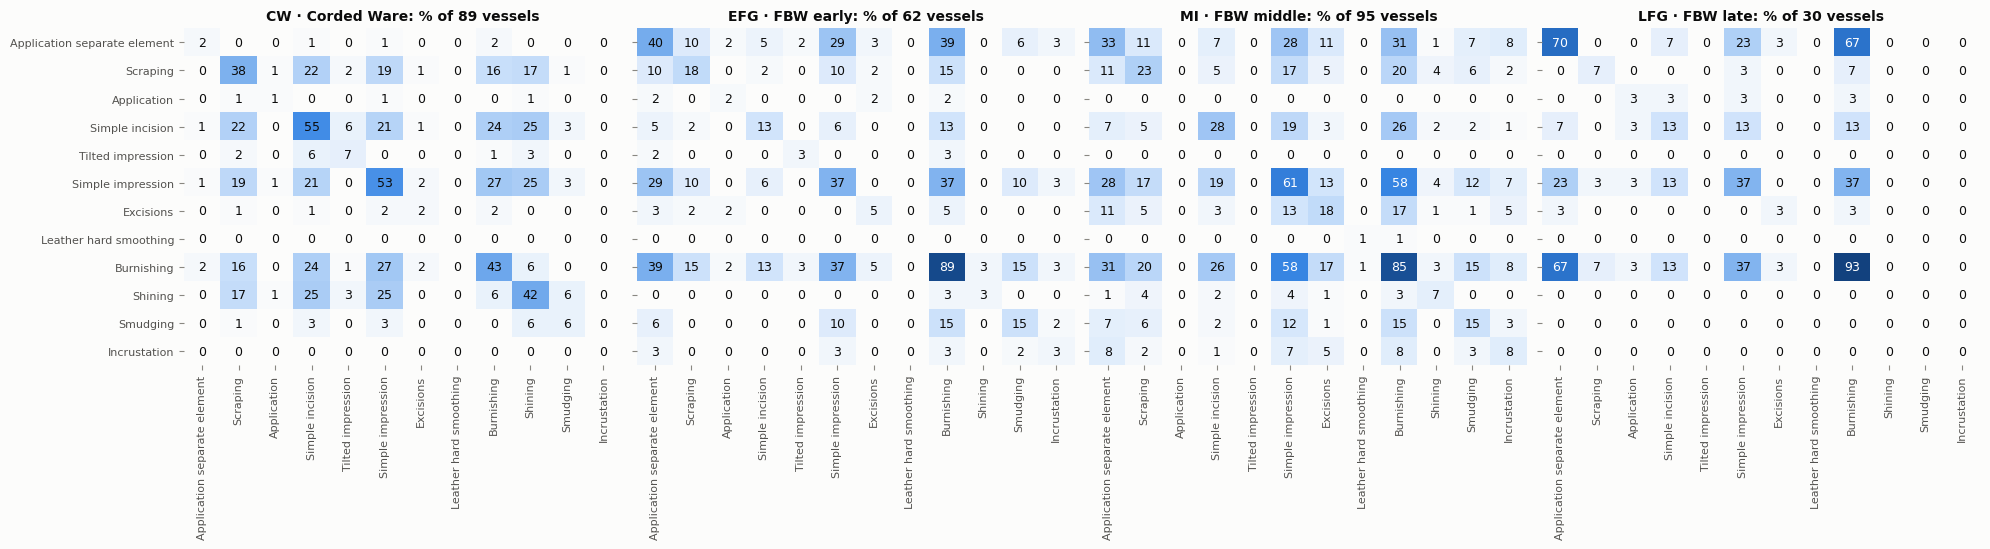

in (almost) every vessel, not shown: Coiling, Dry, Leather-hard, Modelling, Open firing, Pressure, Wet clay, Wet smoothing


In [49]:
in_vessel = pd.DataFrame([[t in set(s) for t in vocab] for s in df["steps"]], columns=vocab).astype(float)
always = [t for t in vocab if in_vessel[t].mean() > 0.9]                    # in (almost) every vessel
variable = [t for t in pl.technique_layout(df["steps"]) if t not in always]   # ordered by mean position in the chain
fig, axes = plt.subplots(1, 4, figsize=(20, 5.6), sharey=True)
for ax, b in zip(axes, BOKS):
    Xb = in_vessel.loc[y_bok == b, variable].to_numpy()
    pl.heatmap(ax, 100 * Xb.T @ Xb / len(Xb), variable, variable, fmt="{:.0f}", vmin=0, vmax=100)
    ax.set_title(f"{pl.label(b)}: % of {len(Xb)} vessels", fontsize=10)
    ax.tick_params(axis="x", rotation=90, labelsize=8); ax.tick_params(axis="y", labelsize=8)
fig.tight_layout(); pl.save(fig, "cooccurrence"); plt.show()
print("in (almost) every vessel, not shown:", ", ".join(always))

**How to read it.** Row $i$, column $j$: the % of the BoK's vessels that use both techniques; the diagonal is the % that use $i$.
- **Two surface treatments, two cultures.** CW polishes by *shining* (42 %), FBW by *burnishing* (85–93 %). In CW the two almost exclude each other: both on 6 % of vessels, where independence would give $0.43\times0.42\approx18$ %.
- **CW's bag:** shining, scraping and simple incision go together (shining with incision 25 %, with scraping 17 %).
- **FBW's bag:** burnishing with separately applied elements (39 % of early, 67 % of late flat graves) and with simple impression (37–58 %).
- **Burnishing in CW** (43 % of CW vessels) comes *without* FBW's companions: with applied elements on 2 % of CW vessels, with smudging on none, but with simple incision (24 %) and simple impression (27 %). If CW potters took burnishing from FBW, they took it alone and fitted it into their own chains — not as a bag (10.8 asks when).

**Does co-occurrence help classification?**

*Lemma.* For one vessel, the set of co-occurring pairs $\{(i,j): x_{vi}x_{vj}=1\}$ and the set of techniques determine each other (each technique is in some pair as soon as the vessel has two). *So pairs carry no information about a vessel beyond its set of techniques.* In a log-linear (maximum-entropy) classifier they can only add **interactions**:
$$\log\hat p(c\mid x)=b_c+\sum_i\theta_{ci}\,x_i+\sum_{i<j}\theta_{cij}\,x_ix_j-\log Z(x).$$
$\theta_{cij}\ne0$ means that "$i$ together with $j$" says something about the BoK that $i$ and $j$ separately do not. Three learned-weight models (7.6) separate the questions:
- **techniques (set):** which techniques, no order, no pairs;
- **techniques + co-occurring pairs:** adds the interactions $x_ix_j$;
- **transitions:** order (Kroon's edges), as in 7.6.

**The biterm topic model** (BTM; Yan, Guo, Lan & Cheng 2013) is a topic model built for short documents. A *biterm* is an unordered pair of words in the same document; a vessel with $N$ triplets has $N(N-1)/2$ biterms. BTM models the biterms of the whole corpus:
$$\theta\sim\mathrm{Dir}(\alpha),\quad\phi_k\sim\mathrm{Dir}(\beta),\quad z_b\sim\mathrm{Cat}(\theta),\quad w_{b1},w_{b2}\sim\mathrm{Cat}(\phi_{z_b}),$$
with one topic mixture $\theta$ for the whole corpus. Both words of a biterm share a topic, so the topics are learned from co-occurrence pooled over all vessels. That is BTM's answer to sparse documents — what the pseudo-documents did in the legacy notebook, but **without pooling vessels of one label**. A vessel's mixture is $p(z\mid v)=\sum_b p(z\mid b)\,p(b\mid v)$, with $p(z\mid b)\propto\theta_z\phi_z(w_{b1})\phi_z(w_{b2})$. Collapsed Gibbs sampling, $\alpha=50/K$, $\beta=0.01$ (`chaine.btm`). Two read-outs:
- **4 topics matched to the BoKs** one-to-one, as LDA (4.3): fully unsupervised, $\hat p(c\mid v)=p(z=k(c)\mid v)$;
- **8 topics + learned read-out:** a logistic regression from $\log p(z\mid v)$ to the BoK, fitted on the training vessels.

First BTM on all 276 single vessels, as a description (4 topics):

In [50]:
from chaine.btm import BTM
btm_all = BTM(4, n_iter=300, seed=SEED).fit(data.documents(df, 3))
theta_btm = btm_all.transform(data.documents(df, 3))
print(f"BTM on the 276 single vessels: {btm_all.n_biterms} biterms; "
      f"NMI(dominant topic, BoK) = {sbm.agreement(theta_btm.argmax(1), y_bok)['NMI']:.2f}")
display(pd.DataFrame({"share of biterms θ_k": btm_all.theta,
                      "most probable triplets": [" | ".join(pl.short(btm_all.vocab[i]) for i in np.argsort(-btm_all.phi[k])[:4])
                                                 for k in range(4)]}, index=[f"topic {k}" for k in range(4)]))
pd.crosstab(pd.Series(y_bok, name="BoK"), pd.Series(theta_btm.argmax(1), name="dominant BTM topic")).reindex(BOKS)

BTM on the 276 single vessels: 8912 biterms; NMI(dominant topic, BoK) = 0.18


,share of biterms θ_k,most probable triplets
topic 0,0.254,Coiling › Pressure › Wet smoothing | Modelling › Coiling › Pressure | Wet clay › Modelling › Coiling | Lea...
topic 1,0.119,Pressure › Wet smoothing › Leather-hard | Wet clay › Modelling › Coiling | Modelling › Coiling › Pressure ...
topic 2,0.198,Wet clay › Modelling › Coiling | Modelling › Coiling › Pressure | Shining › Dry › Open firing | Pressure ›...
topic 3,0.430,Burnishing › Dry › Open firing | Wet clay › Modelling › Coiling | Leather-hard › Burnishing › Dry | Modell...


dominant BTM topic,0,1,2,3
BoK,,,,
CW,22,12,47,8
EFG,8,25,1,28
MI,28,19,6,42
LFG,3,4,0,23


**How to read it.**
- *Topics:* the opening triplets (wet clay → modelling → coiling → pressure) are in every topic, because they are in every vessel. What differs is the rest: topic 2 is CW's (shining, scraping), topics 1 and 3 FBW's (burnishing).
- *Agreement with the BoKs:* NMI 0.18 between a vessel's dominant topic and its BoK — like the hSBM on single vessels (0.15, 7.2), far from the 0.70–0.78 of the pseudo-documents (4.4, 5.2). Without pooling vessels of one label, the strongest co-occurrence structure is not the BoK: 47 of the 89 CW vessels fall in topic 2, and 23 of the 30 late-flat-grave vessels in topic 3, but early and middle FBW are split between topics 0, 1 and 3.

In [51]:
import itertools
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

class LearnedSet(LearnedWeights):
    """Learned weights (7.6) on the set of techniques; with pairs=True also on every co-occurring pair x_i x_j."""
    def __init__(self, pairs=False, seed=0):
        super().__init__(1, seed)
        self.pairs = pairs
    def tokens(self, part):
        sets = [sorted(set(s)) for s in part["steps"]]
        return [t + ([f"{a} & {b}" for a, b in itertools.combinations(t, 2)] if self.pairs else []) for t in sets]

class BTMClassifier:
    """BTM on the training vessels themselves (no pseudo-documents). read="matched": K topics matched one-to-one to
    the BoKs as in 4.3; read="learned": logistic regression from log p(z | vessel) to the BoK."""
    def __init__(self, K=4, read="matched", seed=0):
        self.K, self.read, self.seed = K, read, seed
    def _theta(self, part):
        return self.btm.transform(data.documents(part, 3))
    def fit(self, part):
        self.btm = BTM(self.K, n_iter=150, seed=self.seed).fit(data.documents(part, 3))
        if self.read == "matched":
            emp = tm.get_empirical_word_distribution(tm.load_pottery_data(part), self.btm.vocab, BOKS)
            self.mapping, _ = tm.matching_empirical(emp, self.btm.phi, BOKS)
        else:
            cv = StratifiedKFold(5, shuffle=True, random_state=self.seed)
            self.lr = GridSearchCV(LogisticRegression(max_iter=5000), {"C": [0.1, 0.3, 1, 3, 10, 30]},
                                   scoring="neg_log_loss", cv=cv).fit(np.log(self._theta(part) + 1e-6), part["bok"].astype(str))
        return self
    def predict_proba(self, part):
        if self.read == "matched":
            p = self._theta(part)[:, [self.mapping[c] for c in BOKS]]
            return p / p.sum(1, keepdims=True)
        p = self.lr.predict_proba(np.log(self._theta(part) + 1e-6))
        return p[:, [list(self.lr.classes_).index(c) for c in BOKS]]

cooc = {"Markov order 1": lambda s: clf.MarkovClassifier(1, beta=2.0, grammar=grammar),
        "learned weights, techniques (set)": lambda s: LearnedSet(False, s),
        "learned weights, techniques + co-occurring pairs": lambda s: LearnedSet(True, s),
        "learned weights, transitions": lambda s: LearnedWeights(2, s),
        "BTM, 4 topics matched to BoKs": lambda s: BTMClassifier(4, "matched", s),
        "BTM, 8 topics + learned read-out": lambda s: BTMClassifier(8, "learned", s)}
for name, make in cooc.items():
    probas = [ev.cross_val_proba(df, lambda: make(seed), "site", N_FOLDS, seed) for seed in range(3)]
    R.add(name, "CV, sites (7.7)", np.tile(y_bok, 3), np.vstack(probas))
R.add("LDA (7.3)", "CV, sites (7.7)", *R.proba[("LDA", "CV, sites")])
display(R.table("CV, sites (7.7)", ["LDA (7.3)"] + list(cooc))[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]])
n7 = list(cooc)
_, paired77 = site_bootstrap([], [(n7[2], n7[1]), (n7[1], n7[3]), (n7[1], n7[0]), (n7[4], "LDA (7.3)"), (n7[5], "LDA (7.3)")],
                             protocol="CV, sites (7.7)")
paired77.round(3)

,,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,protocol,,,,,
LDA (7.3),"CV, sites (7.7)",0.499,0.518,0.471,1.167,0.074
Markov order 1,"CV, sites (7.7)",0.537,0.459,0.456,1.292,0.128
"learned weights, techniques (set)","CV, sites (7.7)",0.542,0.467,0.466,1.046,0.044
"learned weights, techniques + co-occurring pairs","CV, sites (7.7)",0.537,0.457,0.456,1.037,0.052
"learned weights, transitions","CV, sites (7.7)",0.535,0.451,0.450,1.044,0.062
"BTM, 4 topics matched to BoKs","CV, sites (7.7)",0.437,0.433,0.415,1.730,0.199
"BTM, 8 topics + learned read-out","CV, sites (7.7)",0.518,0.428,0.420,1.152,0.078


Δ accuracy  \
                                                                                             mean   
learned weights, techniques + co-occurring pairs  −  learned weights, techniques (set)     -0.005   
learned weights, techniques (set)  −  learned weights, transitions                          0.007   
learned weights, techniques (set)  −  Markov order 1                                        0.005   
BTM, 4 topics matched to BoKs  −  LDA (7.3)                                                -0.062   
BTM, 8 topics + learned read-out  −  LDA (7.3)                                              0.019   

                                                                                               \
                                                                                           se   
learned weights, techniques + co-occurring pairs  −  learned weights, techniques (set)  0.009   
learned weights, techniques (set)  −  learned weights, transitions                      0.019   
learned weights, techniques (set)  −  Markov order 1                                    0.023   
BTM, 4 topics matched to BoKs  −  LDA (7.3)                                             0.035   
BTM, 8 topics + learned read-out  −  LDA (7.3)                                          0.058   

                                                                                               \
                                                                                            z   
learned weights, techniques + co-occurring pairs  −  learned weights, techniques (set) -0.531   
learned weights, techniques (set)  −  learned weights, transitions                      0.390   
learned weights, techniques (set)  −  Markov order 1                                    0.212   
BTM, 4 topics matched to BoKs  −  LDA (7.3)                                            -1.746   
BTM, 8 topics + learned read-out  −  LDA (7.3)                                          0.334   

                                                                                       Δ log-loss  \
                                                                                             mean   
learned weights, techniques + co-occurring pairs  −  learned weights, techniques (set)     -0.009   
learned weights, techniques (set)  −  learned weights, transitions                          0.002   
learned weights, techniques (set)  −  Markov order 1                                       -0.246   
BTM, 4 topics matched to BoKs  −  LDA (7.3)                                                 0.563   
BTM, 8 topics + learned read-out  −  LDA (7.3)                                             -0.015   

                                                                                               
                                                                                           se  
learned weights, techniques + co-occurring pairs  −  learned weights, techniques (set)  0.009  
learned weights, techniques (set)  −  learned weights, transitions                      0.024  
learned weights, techniques (set)  −  Markov order 1                                    0.095  
BTM, 4 topics matched to BoKs  −  LDA (7.3)                                             0.111  
BTM, 8 topics + learned read-out  −  LDA (7.3)                                          0.081

**Reading** (sites held out, 3 × 5-fold; paired site bootstrap as in 7.3).
- **The set of techniques is enough.** Learned weights on *which* techniques a vessel uses — no order, no pairs — reach 0.54 and log-loss 1.05, the same as the transitions (difference +0.01 ± 0.02) and the Markov chain in accuracy, with much better probabilities than Markov (log-loss −0.25 ± 0.10). Section 9 found single techniques ($n=1$) the worst words; that holds for models that *count* tokens (naive Bayes, LDA, hSBM), not for learned weights.
- **Co-occurrence adds nothing.** Adding every co-occurring pair changes accuracy by −0.005 ± 0.009 and log-loss by −0.009 ± 0.009. No combination of techniques tells the BoK more than its techniques one by one (Lemma above), at this sample size.
- **BTM.** Matched to the BoKs without labels, BTM scores 0.44 (log-loss 1.73), below LDA's 0.50 (−0.06 ± 0.04, $z$ = −1.7; log-loss +0.56 ± 0.11): the bootstrap's label pooling is what made LDA's topics line up with the BoKs. With a learned read-out (8 topics → BoK) BTM reaches 0.52 (log-loss 1.15), as good as LDA (+0.02 ± 0.06) without any pseudo-documents, but no better than the learned weights on the techniques themselves.
- **So:** the information about the culture is in *which* techniques are used. Co-occurrence describes the bags (figure above) but carries no extra information for attribution.

## 8 · Topic models with richer data

Bootstrapping reshuffles the same information; it cannot add any. What *can* be added is other information about each vessel: its form, where it was found, and what kind of site it came from. The simplest way to give this to a topic model is as more words.

*Survival and selection, $P(X\mid S=1)$ (formerly this section), together with missing steps, geography and maximum entropy, are now in the auxiliary notebook [`new_attempts_experiments.ipynb`](new_attempts_experiments.ipynb).*

- **LDA.** Each vessel's document gets metadata tokens next to its triplets: `form=Beaker`, `region=Drenthe`, `cell=52.75N,6.50E` (a 0.25° grid cell, about 28 km north–south by 17 km east–west) and, optionally, `site type=megalith`. The legacy pipeline then runs unchanged: stop triplets, $g=7$ pseudo-documents, Gibbs LDA, Hungarian matching, fold-in.
- **hSBM.** Triplets and metadata are different kinds of thing, so they become different kinds of node. The result is a *tripartite* network, vessel – triplet – metadata (Hyland et al. 2021). graph-tool's `clabel`/`pclabel` keep the three kinds in separate groups at every level, and edges carry counts. A new vessel is placed by fold-in, as in 5.5: add it with its triplet and metadata edges, and choose the document group that costs the least description length.
- **Baseline.** Putting metadata into a topic model is worth something only if the model beats the metadata alone. So we also fit naive Bayes on the same metadata.
- **Caveat.** Site type is the find context. If phases were assigned partly by context, predicting them from it is circular (auxiliary notebook, 2.5). Results are reported with and without it.

All models are scored with whole sites held out (3 × 5-fold), as in 7.3.

**How the metadata enter, in formulas.** Vessel $i$ has triplets $w_{i1},\dots,w_{iN_i}$ and metadata tokens $m_{i1},\dots,m_{iM_i}$: form, region and grid cell, plus site type when it is used. A vessel has on average $N_i\approx8.4$ triplets (all kept, `STOP_K = 0`) and $M_i\approx3.0$ metadata tokens (4.0 with site type), so the metadata are about 3 of its 11 tokens.

- **Metadata alone (naive Bayes, the baseline).** One categorical distribution per field $f$ and BoK, Laplace-smoothed:
$$p(c\mid m_i)\propto\pi_c\prod_f\hat p_f(m_{if}\mid c),\qquad \hat p_f(v\mid c)=\frac{n_{f,v,c}+1}{n_{f,c}+V_f},$$
  where $n_{f,v,c}$ counts training vessels of BoK $c$ with value $v$, $n_{f,c}$ those with field $f$ recorded, and $V_f$ is the number of values of the field.
- **LDA.** The vocabulary becomes $\mathcal V=\mathcal V_T\cup\mathcal V_M$, and each topic is *one* distribution over both, $\sum_{w\in\mathcal V_T}\phi_k(w)+\sum_{v\in\mathcal V_M}\phi_k(v)=1$:
$$p(w_i,m_i\mid\theta_i,\phi)=\prod_{n=1}^{N_i}\sum_k\theta_{ik}\,\phi_k(w_{in})\;\prod_{j=1}^{M_i}\sum_k\theta_{ik}\,\phi_k(m_{ij}).$$
  One topic mixture $\theta_i$ explains techniques and metadata together, and a metadata token weighs exactly as much as a triplet. Pseudo-documents pool the triplets *and* the metadata of their $g=7$ vessels; a test vessel is folded in with both.
- **Tripartite hSBM.** The nodes are vessels, triplets and metadata values; $A_{iw}$ counts the occurrences of triplet $w$ in vessel $i$, and $A_{iv}=1$ if vessel $i$ has metadata value $v$.
  - A partition $b$ puts every node in a group, and every group holds nodes of one kind only, at every level (`clabel`, `pclabel`).
  - The nested degree-corrected SBM depends on the network only through the node degrees and the edge counts between groups, $e_{rs}=\sum_{ij}A_{ij}\,\delta_{b_i r}\,\delta_{b_j s}$. The partition minimises the description length $\Sigma(b)=-\ln P(A\mid b)-\ln P(b)$, as in Section 5.
  - A vessel group $r$ thus has one profile $e_{r\cdot}$ over the triplet groups (the topics) *and* the metadata groups. The metadata values are themselves grouped (8.1).
  - Fold-in, as in 5.5: $P(r\mid i)\propto e^{-\Delta\Sigma_r(i)}$, where $\Delta\Sigma_r(i)$ is the increase of description length when vessel $i$, with its triplet and metadata edges, joins vessel group $r$. Then $p(c\mid i)=\sum_r P(r\mid i)\,p(c\mid r)$.
- **The shared assumption.** All three treat triplets and metadata as independent given the latent class — the BoK $c$, the topic mixture $\theta_i$, or the group $r$. For place, the auxiliary notebook (5.1) finds no dependence between chain and location within a BoK; for form, the assumption is untested.

In [52]:
if RUN_SBM:
    import graph_tool.all as gt

def meta_tokens(row, fields):
    """The metadata of a vessel as extra words."""
    out = []
    if "form" in fields and isinstance(row.vessel_type, str):
        out.append(f"form={row.vessel_type}")
    if "region" in fields and isinstance(row.region, str) and row.region:
        out.append(f"region={row.region}")
    if "cell" in fields and np.isfinite(row.latitude):                  # 0.25° grid cell
        out.append(f"cell={np.floor(row.latitude / 0.25) * 0.25:.2f}N,{np.floor(row.longitude / 0.25) * 0.25:.2f}E")
    if "context" in fields and isinstance(row.site_type, str):
        out.append(f"site type={row.site_type}")
    return out

class MetaNB:
    """Baseline: naive Bayes on the metadata alone; one categorical distribution per field and culture (Laplace)."""
    def __init__(self, fields):
        self.fields = fields
    def fit(self, part):
        y = part["bok"].astype(str).to_numpy()
        toks = [meta_tokens(r, self.fields) for r in part.itertuples()]
        self.vocab = sorted({t for ts in toks for t in ts})
        n = np.ones((len(BOKS), len(self.vocab)))
        for ts, c in zip(toks, y):
            for t in ts:
                n[BOKS.index(c), self.vocab.index(t)] += 1
        field = np.array([t.split("=")[0] for t in self.vocab])
        for f in set(field):
            n[:, field == f] /= n[:, field == f].sum(1, keepdims=True)
        self.log_p = np.log(n)
        self.log_prior = np.log((pd.Series(y).value_counts().reindex(BOKS, fill_value=0).to_numpy() + 1) / (len(y) + len(BOKS)))
        return self
    def predict_proba(self, part):
        col = {t: j for j, t in enumerate(self.vocab)}
        return softmax_rows(np.array([self.log_prior + sum((self.log_p[:, col[t]] for t in meta_tokens(r, self.fields) if t in col),
                                                           np.zeros(len(BOKS))) for r in part.itertuples()]))

class RichLDA:
    """The LDA pipeline of Sections 4 and 7.3 with metadata tokens added to every vessel's document."""
    def __init__(self, fields, g=7, seed=0):
        self.fields, self.g, self.seed = fields, g, seed
    def _docs(self, part):
        return [{**d, "triplets": [t for t in d["triplets"] if t not in self.removed] + meta_tokens(r, self.fields)}
                for d, r in zip(tm.load_pottery_data(part), part.itertuples())]
    def fit(self, part):
        _, removed = tm.remove_common_triplets(tm.load_pottery_data(part), STOP_K)    # stop triplets, as before
        self.removed = set(removed)
        docs = self._docs(part)
        self.vocabulary, _ = tm.extract_vocabulary(docs)
        pseudo = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        X_, _ = tm.build_dtm_with_external_vocab(pseudo, {w: i for i, w in enumerate(self.vocabulary)})
        self.lda = tm.LDA_manual(4, 1.0, 1.0, 200, self.seed).fit(X_, self.vocabulary)
        self.mapping, _ = tm.matching_empirical(tm.get_empirical_word_distribution(docs, self.vocabulary, BOKS),
                                                self.lda.topic_word_dist, BOKS)
        return self
    def predict_proba(self, part):
        return tm.lda_culture_proba(self.lda, self._docs(part), self.vocabulary, self.mapping, BOKS)

class TriSBM:
    """Tripartite hSBM, vessel – triplet – metadata (kinds 0, 1, 2 kept apart by clabel/pclabel), fitted to the g = 7
    pseudo-documents; a new vessel is placed by fold-in (least description length among the document groups)."""
    def __init__(self, fields, g=7, seed=0, sweeps=50):
        self.fields, self.g, self.seed, self.sweeps = fields, g, seed, sweeps
    def fit(self, part):
        docs = tm.load_pottery_data(part)
        meta = {d["vessel_id"]: meta_tokens(r, self.fields) for d, r in zip(docs, part.itertuples())}
        pseudo = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        items = [[(1, w) for w in d["triplets"]] + [(2, m) for v in d["original_vessels"] for m in meta[v]] for d in pseudo]
        self.labels = [d["culture"] for d in pseudo]
        G = gt.Graph(directed=False); self.kind = G.new_vp("int"); self.count = G.new_ep("int")
        self.D = len(items); G.add_vertex(self.D); self.index = {}
        for d, its in enumerate(items):
            for it, c in Counter(its).items():
                if it not in self.index:
                    v = G.add_vertex(); self.kind[v] = it[0]; self.index[it] = int(v)
                self.count[G.add_edge(d, self.index[it])] = c
        self.G = G
        gt.openmp_set_num_threads(1); gt.seed_rng(self.seed + 1); np.random.seed(self.seed)   # seed_rng(0) would be random
        self.state = gt.minimize_nested_blockmodel_dl(G, state_args=dict(clabel=self.kind, pclabel=self.kind, eweight=self.count))
        for _ in range(self.sweeps):
            self.state.multiflip_mcmc_sweep(beta=np.inf, niter=10)
        b0 = np.asarray(self.state.get_bs()[0])[:self.D]
        self.groups = np.unique(b0)
        M_ = np.zeros((len(self.groups), len(BOKS)))
        for r, y in zip(b0, self.labels):
            M_[np.searchsorted(self.groups, r), BOKS.index(y)] += 1
        self.p_culture = M_ / M_.sum(1, keepdims=True)                    # p(culture | document group)
        return self
    def predict_proba(self, part):
        bs, out = [np.asarray(b) for b in self.state.get_bs()], []
        for toks, r in zip(data.documents(part), part.itertuples()):
            known = Counter(it for it in [(1, w) for w in toks] + [(2, m) for m in meta_tokens(r, self.fields)] if it in self.index)
            G = self.G.copy(); kind = G.copy_property(self.kind); count = G.copy_property(self.count)
            v = G.add_vertex(); kind[v] = 0
            for it, c in known.items():
                count[G.add_edge(v, self.index[it])] = c
            st = gt.NestedBlockState(G, bs=[np.append(bs[0], self.groups[0])] + bs[1:],
                                     state_args=dict(clabel=kind, pclabel=kind, eweight=count))
            dS = np.array([0.0] + [st.levels[0].virtual_vertex_move(int(v), int(g)) for g in self.groups[1:]])
            p = np.exp(-(dS - dS.min())); out.append(p / p.sum() @ self.p_culture)
        return np.array(out)

In [53]:
rich = {"metadata only: form, region, cell": lambda s: MetaNB(("form", "region", "cell")),
        "LDA + form, region, cell": lambda s: RichLDA(("form", "region", "cell"), seed=s),
        "metadata only: + site type": lambda s: MetaNB(("form", "region", "cell", "context")),
        "LDA + form, region, cell, site type": lambda s: RichLDA(("form", "region", "cell", "context"), seed=s)}
if RUN_SBM:
    rich["hSBM + form, region, cell"] = lambda s: TriSBM(("form", "region", "cell"), seed=s)
    rich["hSBM + form, region, cell, site type"] = lambda s: TriSBM(("form", "region", "cell", "context"), seed=s)
for name, make in rich.items():
    probas = [ev.cross_val_proba(df, lambda: make(seed), "site", N_FOLDS, seed) for seed in range(3)]
    R.add(name, "CV, sites", np.tile(y_bok, 3), np.vstack(probas))
rich_table = ["majority", "vessel form only", "LDA"] + (["hSBM, fold-in"] if RUN_SBM else []) + list(rich)
R.table("CV, sites", rich_table)[["accuracy", "balanced_acc", "macro_F1", "log_loss", "ECE"]]

,,accuracy,balanced_acc,macro_F1,log_loss,ECE
model,protocol,,,,,
majority,"CV, sites",0.344,0.250,0.128,1.329,4.404e-04
vessel form only,"CV, sites",0.560,0.457,0.427,1.068,4.023e-02
LDA,"CV, sites",0.499,0.518,0.471,1.167,7.379e-02
"hSBM, fold-in","CV, sites",0.524,0.540,0.509,1.643,2.303e-01
"metadata only: form, region, cell","CV, sites",0.558,0.435,0.422,1.336,1.900e-01
"LDA + form, region, cell","CV, sites",0.558,0.488,0.483,1.059,8.076e-02
metadata only: + site type,"CV, sites",0.725,0.572,0.568,0.923,1.695e-01
"LDA + form, region, cell, site type","CV, sites",0.635,0.542,0.543,0.950,1.399e-01
"hSBM + form, region, cell","CV, sites",0.600,0.516,0.516,2.610,2.883e-01


**How to read it.** These are scores with sites held out (3 × 5-fold, $n$ = 828); the columns are those of Section 3. The first four rows repeat 7.3 for reference. "Metadata only" is naive Bayes on the metadata tokens alone; rows with "+" add those tokens to the topic models. The paired test after the reading below says which differences are real.

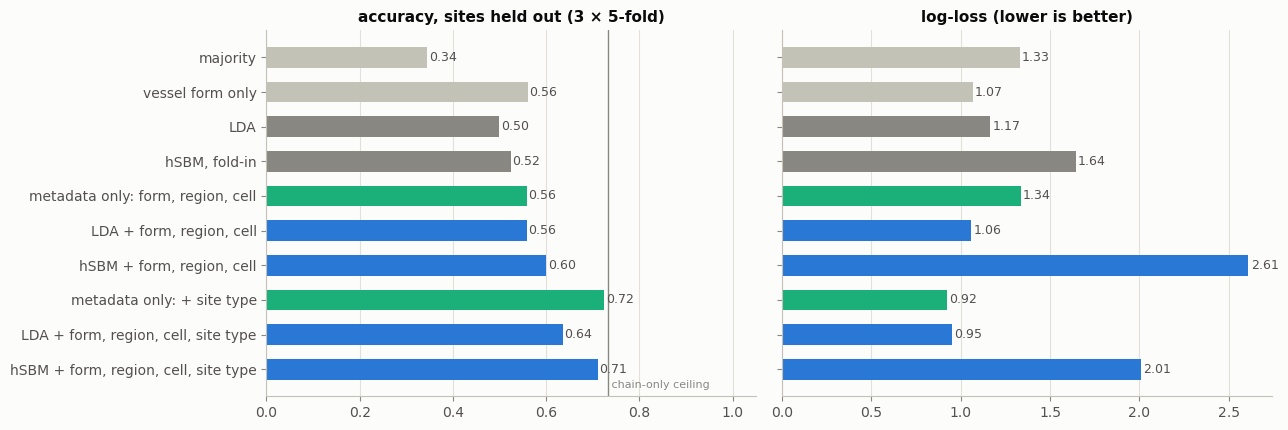

In [54]:
t = R.table("CV, sites", rich_table).droplevel("protocol")
order = ["majority", "vessel form only", "LDA"] + (["hSBM, fold-in"] if RUN_SBM else []) + \
        ["metadata only: form, region, cell", "LDA + form, region, cell"] + (["hSBM + form, region, cell"] if RUN_SBM else []) + \
        ["metadata only: + site type", "LDA + form, region, cell, site type"] + (["hSBM + form, region, cell, site type"] if RUN_SBM else [])
colors = [pl.INK["axis"]] * 2 + [pl.INK["muted"]] * (2 if RUN_SBM else 1) + \
         ([pl.COLORS["MI"]] + [pl.COLORS["CW"]] * (2 if RUN_SBM else 1)) * 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
pl.hbars(axes[0], order, t.loc[order, "accuracy"].values, colors, ref=ceiling["BoK (4 classes)"], ref_label="chain-only ceiling")
pl.hbars(axes[1], order, t.loc[order, "log_loss"].values, colors)
axes[0].set_xlim(0, 1.05); axes[0].set_title("accuracy, sites held out (3 × 5-fold)")
axes[1].set_title("log-loss (lower is better)"); axes[1].set_yticklabels([])
fig.tight_layout(); plt.show()

**Reading.**
- **Both topic models gain from the metadata, but only up to the metadata alone.** Form, region and cell lift LDA from 0.50 to 0.56 (log-loss 1.17 → 1.06) and the hSBM from 0.52 to 0.60; the metadata alone give 0.56. Neither gain exceeds noise (paired test below). The metadata are not too few — about 3 of a vessel's 11 tokens (formulas above) — but the topic models do not combine them better than counting them directly.
- **The hSBM's probabilities stay badly over-confident** (log-loss 2.6): fold-in picks one document group almost deterministically.
- **With the site type**, the metadata alone (0.73) clearly beat LDA (0.64) and match the hSBM (0.71). When one variable is this informative, mixing it with weak triplet evidence in an unsupervised model only adds noise.
- **The lesson.** Richer data help, where bootstrapping did not. But a topic model is not the best way to combine different kinds of evidence for attribution. The maximum-entropy classifier of the auxiliary notebook (Part 6) reaches 0.69 with transitions, location and form, and 0.77 with the site type as well, with calibrated probabilities. The topic models remain the better *description* (8.1).

**Which of these differences are real?** Paired site-bootstrap of the accuracy and log-loss differences (as in 7.3).

In [55]:
pairs8 = [("LDA + form, region, cell", "LDA"), ("LDA + form, region, cell", "metadata only: form, region, cell"),
          ("hSBM + form, region, cell", "hSBM, fold-in"), ("hSBM + form, region, cell", "metadata only: form, region, cell"),
          ("metadata only: + site type", "LDA + form, region, cell, site type"),
          ("metadata only: + site type", "hSBM + form, region, cell, site type")]
_, paired8 = site_bootstrap([], [p for p in pairs8 if set(p) <= set(rich_table)])
paired8.round(3)

Δ accuracy  \
                                                                          mean   
LDA + form, region, cell  −  LDA                                         0.059   
LDA + form, region, cell  −  metadata only: form, region, cell          -0.000   
hSBM + form, region, cell  −  hSBM, fold-in                              0.076   
hSBM + form, region, cell  −  metadata only: form, region, cell          0.042   
metadata only: + site type  −  LDA + form, region, cell, site type       0.089   
metadata only: + site type  −  hSBM + form, region, cell, site type      0.014   

                                                                            \
                                                                        se   
LDA + form, region, cell  −  LDA                                     0.056   
LDA + form, region, cell  −  metadata only: form, region, cell       0.043   
hSBM + form, region, cell  −  hSBM, fold-in                          0.063   
hSBM + form, region, cell  −  metadata only: form, region, cell      0.043   
metadata only: + site type  −  LDA + form, region, cell, site type   0.036   
metadata only: + site type  −  hSBM + form, region, cell, site type  0.033   

                                                                            \
                                                                         z   
LDA + form, region, cell  −  LDA                                     1.058   
LDA + form, region, cell  −  metadata only: form, region, cell      -0.000   
hSBM + form, region, cell  −  hSBM, fold-in                          1.213   
hSBM + form, region, cell  −  metadata only: form, region, cell      0.985   
metadata only: + site type  −  LDA + form, region, cell, site type   2.514   
metadata only: + site type  −  hSBM + form, region, cell, site type  0.436   

                                                                    Δ log-loss  \
                                                                          mean   
LDA + form, region, cell  −  LDA                                        -0.107   
LDA + form, region, cell  −  metadata only: form, region, cell          -0.277   
hSBM + form, region, cell  −  hSBM, fold-in                              0.967   
hSBM + form, region, cell  −  metadata only: form, region, cell          1.274   
metadata only: + site type  −  LDA + form, region, cell, site type      -0.027   
metadata only: + site type  −  hSBM + form, region, cell, site type     -1.084   

                                                                            
                                                                        se  
LDA + form, region, cell  −  LDA                                     0.042  
LDA + form, region, cell  −  metadata only: form, region, cell       0.247  
hSBM + form, region, cell  −  hSBM, fold-in                          0.600  
hSBM + form, region, cell  −  metadata only: form, region, cell      0.388  
metadata only: + site type  −  LDA + form, region, cell, site type   0.258  
metadata only: + site type  −  hSBM + form, region, cell, site type  0.330

**How to read it.** Paired differences with sites held out ($z$ = difference / se).
- *LDA:* the metadata change accuracy by +0.06 ± 0.06 ($z$ = 1.1) and improve the log-loss by 0.11 ± 0.04 ($z$ ≈ −2.5): clearly better probabilities, possibly better decisions. LDA + metadata does not differ from the metadata alone (0.00 ± 0.04).
- *hSBM:* +0.08 ± 0.06 over the hSBM on triplets ($z$ = 1.2), and +0.04 ± 0.04 over the metadata alone ($z$ = 1.0). Its log-loss is worse than the metadata alone by 1.3 ± 0.4.
- *With site type:* the metadata alone beat LDA (+0.09 ± 0.04, $z$ = 2.5) and match the hSBM (+0.01 ± 0.03).
- *What is solid:* the metadata improve LDA's probabilities, and no topic model beats the metadata alone in accuracy.

### 8.1 What the tripartite hSBM puts together
We fit the hSBM to the training vessels of Section 3, with form, region and grid cell as metadata. The table shows the metadata groups at level 0, and for each group the share of its edges that comes from each culture's pseudo-documents.

In [56]:
if RUN_SBM:
    tri = TriSBM(("form", "region", "cell"), seed=SEED).fit(train_df)          # training vessels of Section 3
    b0, kind = np.asarray(tri.state.get_bs()[0]), tri.kind.a
    tokens, share = {}, {}
    for (layer, w), v in tri.index.items():
        if layer == 2:
            tokens.setdefault(b0[v], []).append(w)
    for s, t_, c in tri.G.get_edges([tri.count]):
        d, m = (s, t_) if s < tri.D else (t_, s)
        if kind[m] == 2:
            share.setdefault(b0[m], np.zeros(len(BOKS)))[BOKS.index(tri.labels[d])] += c
    meta_groups = pd.DataFrame([{**dict(zip(BOKS, share[r] / share[r].sum())), "metadata in the group": ", ".join(sorted(tokens[r]))}
                                for r in tokens]).sort_values(BOKS, ascending=False, ignore_index=True)
    n_groups = [len(set(b0[np.asarray(kind) == k])) for k in (0, 1, 2)]
    print(f"level 0: {n_groups[0]} document groups, {n_groups[1]} triplet groups, {n_groups[2]} metadata groups; "
          f"share of each group's edges coming from the pseudo-documents of each culture:")
    display(meta_groups.style.format(precision=2).background_gradient(cmap=pl.SEQ, subset=BOKS, vmin=0, vmax=1))

level 0: 4 document groups, 25 triplet groups, 16 metadata groups; share of each group's edges coming from the pseudo-documents of each culture:


,CW,EFG,MI,LFG,metadata in the group
0,0.98,0.02,0.00,0.00,"cell=51.75N,5.50E, cell=52.00N,5.00E, cell=52.00N,5.50E, cell=52.25N,5.50E, cell=52.25N,5.75E, cell=52.25N,6.00E, cell=53.00N,6.00E, cell=53.00N,6.75E, region=Ede, region=Ermelo, region=Gelderland, region=Groningen, region=Noord-Holland"
1,0.71,0.00,0.29,0.00,"cell=53.00N,6.50E"
2,0.60,0.14,0.25,0.00,form=Beaker
3,0.50,0.50,0.00,0.00,"cell=52.00N,5.75E"
4,0.28,0.00,0.20,0.52,"cell=52.75N,6.00E"
5,0.24,0.00,0.53,0.23,"cell=52.75N,6.50E"
6,0.22,0.16,0.41,0.21,region=Drenthe
7,0.16,0.13,0.51,0.21,"cell=52.75N,6.75E"
8,0.06,0.50,0.21,0.23,form=Amphora-like
9,0.03,0.22,0.24,0.51,form=Bowl


**How to read it.**
- *Shown:* the 16 groups the hSBM forms from the metadata nodes (grid cells, regions, forms). For each group: the share of its edges coming from each culture's pseudo-documents, and its members.
- *Caveat:* these shares describe the training pseudo-documents, not the vessels. The bootstrap gives every culture the same weight, and pooling 7 vessels per document makes rare metadata look more culture-bound than they are.

The metadata sort themselves by culture:
- the cells and regions where only Corded Ware was found (Gelderland, Noord-Holland, Groningen, …) form one group whose edges come almost only from CW pseudo-documents (98 %);
- beakers form a group of their own (60 % CW, 25 % middle FBW);
- bowls lean to late FBW, and amphora-like vessels to early FBW;
- collared flasks and shouldered vessels, together with one grid cell, are early FBW (91 %);
- buckets, jugs and biberons are middle FBW (79 %);
- Drenthe, where all four occur, is shared by all.

This is what the hSBM does well: one picture shows which metadata and which technique groups go with which culture.

## 9 · From triplets to n-grams in the topic models

The words so far are triplets. For a chain $x_1\dots x_T$ and $n\ge1$, the $n$-grams are $g_t=(x_t,\dots,x_{t+n-1})$, $t=1,\dots,T-n+1$: $n=1$ single techniques, $n=2$ transitions (Kroon's edges), $n=3$ triplets, $n=4$ tetragrams, and so on. This section repeats the topic-model pipelines for $n=1,\dots,5$.

**Lemma (a bag of n-grams, n ≥ 2, determines the chain).** Kroon's grammar forbids repeating a technique within a chain, and every chain here satisfies it. Then for every $n\ge2$ the bag of $n$-grams determines the chain.

*Proof.* Without repeated techniques, no $(n-1)$-gram occurs twice in a chain. The leading $(n-1)$-gram of $g_t$, $t\ge2$, equals the trailing $(n-1)$-gram of $g_{t-1}$ and of no other $n$-gram; the leading $(n-1)$-gram $(x_1,\dots,x_{n-1})$ of $g_1$ is the trailing $(n-1)$-gram of none, since that would repeat $x_1$. So $g_1$ is the unique $n$-gram whose head is nobody's tail, and each successor is the unique $n$-gram whose head is the current tail. $\square$

For $n=1$ the bag is the *set* of techniques and forgets their order.

**Overcounting grows with n.** An interior step lies in $n$ different $n$-grams, so a bag-of-$n$-grams likelihood (naive Bayes, the SBM classifiers, the $\tau=1$ Bayes rules) counts each step up to $n$ times — a composite likelihood whose over-confidence should grow with $n$. LDA's fold-in $\theta$ is a normalised mixture, not a product over tokens, and should suffer less.

In [57]:
def ngram_docs(part, n):
    """Documents in the legacy format; the legacy key 'triplets' holds the n-gram tokens."""
    return [{"vessel_id": v, "culture": str(b), "triplets": t, "num_triplets": len(t)}
            for v, b, t in zip(part["vessel_id"], part["bok"], data.documents(part, n))]

assert all(len(set(s)) == len(s) for s in df["steps"])        # no technique repeats within a chain
site_folds_0 = ev.splits(df, "site", N_FOLDS, SEED)
rows = []
for n in range(1, 6):
    toks = data.documents(df, n)
    vessels_per_token = Counter(w for d in toks for w in set(d))
    unseen = []
    for tr, te in site_folds_0:
        seen = {w for i in tr for w in toks[i]}
        unseen += [w not in seen for i in te for w in toks[i]]
    rows.append({"n": n, "vocabulary V_n": len(vessels_per_token), "tokens per vessel": np.mean([len(d) for d in toks]),
                 "share of n-grams found in one vessel only": np.mean([v == 1 for v in vessels_per_token.values()]),
                 "distinct bags": len({tuple(sorted(d)) for d in toks}),
                 "held-out tokens unseen in training (sites)": np.mean(unseen)})
ngram_stats = pd.DataFrame(rows).set_index("n")
assert (ngram_stats.loc[2:, "distinct bags"] == df["chain"].nunique()).all()      # the Lemma, for n = 2..5
ngram_stats

,vocabulary V_n,tokens per vessel,share of n-grams found in one vessel only,distinct bags,held-out tokens unseen in training (sites)
n,,,,,
1,20,10.428,0.050,88,3.475e-04
2,52,9.428,0.192,101,3.843e-03
3,96,8.428,0.229,101,1.247e-02
4,164,7.428,0.335,101,3.317e-02
5,235,6.428,0.421,101,7.046e-02


**How to read it.** For each window length $n$ the columns give:
- the number of distinct $n$-grams $V_n$ (all vessels);
- the mean number of $n$-grams per vessel (chain length − $n$ + 1);
- the share of $n$-grams found in one vessel only;
- the number of distinct bags of $n$-grams;
- the share of held-out tokens never seen in training (sites held out).

The third and last columns measure the price of long windows: at $n=5$, 42 % of the $n$-grams are unique to one vessel, and 7 % of held-out tokens are unknown to the model.

With $n=1$, 101 chains collapse into 88 bags; for $n\ge2$ every chain keeps its own bag (Lemma).

The same pipelines as before, with $n$-gram tokens: the legacy LDA pipeline (Section 4) and the hSBM with fold-in by description length (Section 5), both without stop-word removal so that all $n$ are treated alike; naive Bayes on $n$-grams; and the sequence model with the same statistics — a Markov chain of order $n-1$, whose sufficient statistics are exactly the $n$-gram counts. With $n=3$ and the same stop-triplet setting (`STOP_K`), the $n$-gram classes reproduce the pipelines of Sections 4–5 exactly (asserted). Sites held out, seed 0.

In [58]:
class NgramLDA:
    """Legacy LDA pipeline (Section 4) on n-gram tokens; NgramLDA(3, remove_top=5) is clf.LDAPipeline."""
    def __init__(self, n, g=7, seed=SEED, n_iter=200, alpha=1.0, beta=1.0, remove_top=0):
        self.n, self.g, self.seed, self.n_iter = n, g, seed, n_iter
        self.alpha, self.beta, self.remove_top = alpha, beta, remove_top
    def fit(self, part):
        docs = ngram_docs(part, self.n)
        docs, self.removed = tm.remove_common_triplets(docs, self.remove_top) if self.remove_top else (docs, [])
        self.vocabulary, _ = tm.extract_vocabulary(docs)
        pdocs = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        X_, _ = tm.build_dtm_with_external_vocab(pdocs, {w: i for i, w in enumerate(self.vocabulary)})
        self.lda = tm.LDA_manual(len(BOKS), self.alpha, self.beta, self.n_iter, self.seed).fit(X_, self.vocabulary)
        self.empirical = tm.get_empirical_word_distribution(docs, self.vocabulary, BOKS)
        self.mapping, _ = tm.matching_empirical(self.empirical, self.lda.topic_word_dist, BOKS)
        return self
    def predict_proba(self, part):
        drop = set(self.removed)
        docs = [{**d, "triplets": [t for t in d["triplets"] if t not in drop]} for d in ngram_docs(part, self.n)]
        return tm.lda_culture_proba(self.lda, docs, self.vocabulary, self.mapping, BOKS)

class NgramSBM:
    """Legacy hSBM pipeline with fold-in by description length (Section 5) on n-gram tokens."""
    def __init__(self, n, g=7, seed=SEED, remove_top=0):
        self.n, self.g, self.seed, self.remove_top = n, g, seed, remove_top
    def fit(self, part):
        docs = ngram_docs(part, self.n)
        docs, self.removed = tm.remove_common_triplets(docs, self.remove_top) if self.remove_top else (docs, [])
        pdocs = tm.create_resampled_documents(docs, self.g, 100, self.seed)
        tokens_, self.labels = [d["triplets"] for d in pdocs], [d["culture"] for d in pdocs]
        self.model = sbm.fit_hsbm(tokens_, seed=self.seed, refine_sweeps=50)
        self.clf = sbm.SBMFoldInClassifier().fit(tokens_, self.labels, BOKS, model=self.model)
        return self
    def predict_proba(self, part):
        drop = set(self.removed)
        return self.clf.predict_proba([[t for t in d if t not in drop] for d in data.documents(part, self.n)])

# with n = 3 and the legacy stop triplets these are exactly the pipelines of Sections 4-5
assert np.allclose(NgramLDA(3, remove_top=STOP_K).fit(train_df).predict_proba(test_df), p_lda)
if RUN_SBM:
    assert np.allclose(NgramSBM(3, remove_top=STOP_K).fit(train_df).predict_proba(test_df), p_fi)

rows = []
for n in range(1, 6):
    cand = {"naive Bayes": lambda n=n: clf.NaiveBayesNgram(n=n),
            "Markov, order n − 1": lambda n=n: clf.MarkovClassifier(n - 1, beta=8.0, grammar=grammar),
            "LDA": lambda n=n: NgramLDA(n)}
    if RUN_SBM:
        cand["hSBM, fold-in"] = lambda n=n: NgramSBM(n)
    for name, make in cand.items():
        rows.append({"n": n, "model": name, **ev.scores(y_bok, ev.cross_val_proba(df, make, "site", N_FOLDS, SEED))})
ngram_cv = pd.DataFrame(rows)
ngram_cv.pivot(index="n", columns="model", values=["accuracy", "balanced_acc", "log_loss"]).round(3)

accuracy                                               balanced_acc  \
model      LDA Markov, order n − 1 hSBM, fold-in naive Bayes          LDA   
n                                                                           
1        0.453               0.457         0.373       0.482        0.417   
2        0.464               0.540         0.471       0.504        0.442   
3        0.496               0.522         0.500       0.493        0.516   
4        0.518               0.529         0.529       0.511        0.533   
5        0.504               0.518         0.522       0.500        0.520   

                                                    log_loss  \
model Markov, order n − 1 hSBM, fold-in naive Bayes      LDA   
n                                                              
1                   0.410         0.314       0.376    1.252   
2                   0.458         0.496       0.431    1.198   
3                   0.440         0.527       0.426    1.157   
4                   0.496         0.536       0.439    1.153   
5                   0.486         0.530       0.433    1.166   

                                                     
model Markov, order n − 1 hSBM, fold-in naive Bayes  
n                                                    
1                   1.115         1.308       1.084  
2                   1.218         1.321       1.188  
3                   1.321         1.616       1.407  
4                   1.440         2.042       1.586  
5                   1.573         2.416       1.759

**How to read it.**
- *Shown:* accuracy, balanced accuracy and log-loss of four models as the window $n$ grows (sites held out, seed 0, all 276 vessels).
- *Evidence:* with one seed and ± 0.04–0.05 per accuracy: at $n=1$ (order lost) the models are lowest (0.37–0.48); from $n=3$ to 5 all stay within 0.49–0.53. At $n=2$ the Markov chain (order 1) is already at 0.54, while LDA and the hSBM are still low (0.46–0.47).
- *Log-loss:* the trends are clearer than for accuracy. Naive Bayes goes 1.08 → 1.76 and the hSBM 1.31 → 2.42, steadily, while LDA stays at 1.15–1.25.

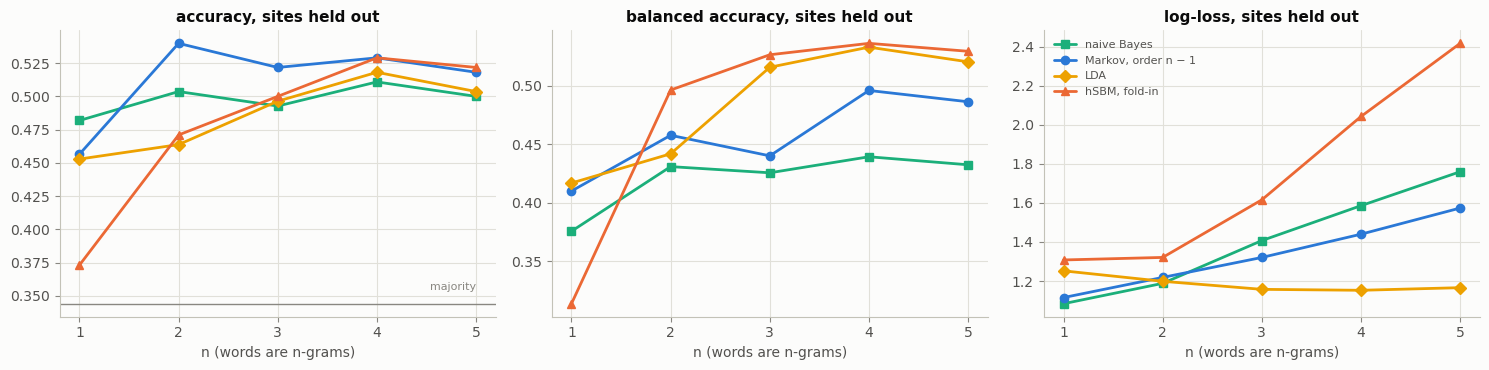

In [59]:
styles_n = {"naive Bayes": (pl.COLORS["MI"], "s"), "Markov, order n − 1": (pl.COLORS["CW"], "o"),
            "LDA": (pl.COLORS["LFG"], "D"), "hSBM, fold-in": (pl.COLORS["EFG"], "^")}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric, title in zip(axes, ["accuracy", "balanced_acc", "log_loss"], ["accuracy", "balanced accuracy", "log-loss"]):
    for name, part in ngram_cv.groupby("model", sort=False):
        color, marker = styles_n[name]
        ax.plot(part["n"], part[metric], color=color, marker=marker, ms=6, label=name)
    ax.set_xticks(range(1, 6)); ax.set_xlabel("n (words are n-grams)"); ax.set_title(f"{title}, sites held out")
axes[0].axhline(majority["BoK (4 classes)"], color=pl.INK["muted"], lw=1)
axes[0].text(5, majority["BoK (4 classes)"] + 0.01, "majority", ha="right", color=pl.INK["muted"], fontsize=8)
axes[2].legend(fontsize=8); fig.tight_layout(); plt.show()

- **Order matters, a little.** Unigrams ($n=1$, order lost) are worst for these counting models (with learned weights the set of techniques does as well as the transitions, 7.7); from $n=3$ on, accuracy stays within a few points (≈ 0.49–0.53), below the variation between seeds and splits seen in Section 7. No window length is clearly best, and none approaches the ceiling.
- **Overcounting.** As predicted, the log-loss of naive Bayes and of the hSBM classifier grows steadily with $n$ — each step is counted $n$ times — while LDA's stays flat.
- **Sparsity.** Larger $n$ means more specific but rarer words (table above); the sequence model with the same statistics (Markov order $n-1$) does as well as any bag model, with far fewer assumptions.

How the fitted models themselves change with $n$ (training split of Section 3): the fit of LDA's matched topics to the empirical distributions, and the structure the hSBM infers.

In [60]:
rows, lda_by_n = [], {}
for n in range(1, 6):
    m = NgramLDA(n).fit(train_df); lda_by_n[n] = m
    phi_n = m.lda.topic_word_dist[[m.mapping[c] for c in BOKS]]
    row = {"n": n, "V_n (training)": len(m.vocabulary),
           "LDA: mean JS(matched φ, empirical) (bits)": np.mean([tm.js_divergence(e, f) for e, f in zip(m.empirical, phi_n)])}
    if RUN_SBM:
        h = NgramSBM(n).fit(train_df)
        levels = [lv for lv in sbm.hierarchy(h.model) if lv["doc_groups"] > 1]
        row.update({"hSBM topics, level 0": levels[0]["word_groups"], "hSBM document groups, level 0": levels[0]["doc_groups"],
                    "hSBM NMI(level-0 groups, culture)": sbm.agreement(sbm.doc_partition(h.model), h.labels)["NMI"],
                    "hSBM levels": len(levels)})
    rows.append(row)
pd.DataFrame(rows).set_index("n")

,V_n (training),"LDA: mean JS(matched φ, empirical) (bits)","hSBM topics, level 0","hSBM document groups, level 0","hSBM NMI(level-0 groups, culture)",hSBM levels
n,,,,,,
1,20,0.009,5,2,0.561,1
2,51,0.031,14,3,0.787,1
3,93,0.032,24,5,0.775,1
4,152,0.038,36,22,0.620,3
5,212,0.048,42,52,0.502,3


LDA's matched topics fit the empirical distributions a little worse as the vocabulary grows. The hSBM infers more topics as $n$ grows (5 → 42), and its pseudo-document groups match the cultures best for pairs and triplets (NMI ≈ 0.78); for $n\ge4$ the sparse words split each culture into many small groups.

The legacy overlay (Section 4.3) for single techniques ($n=1$) and pairs ($n=2$): empirical distribution of each culture vs its matched LDA topic.

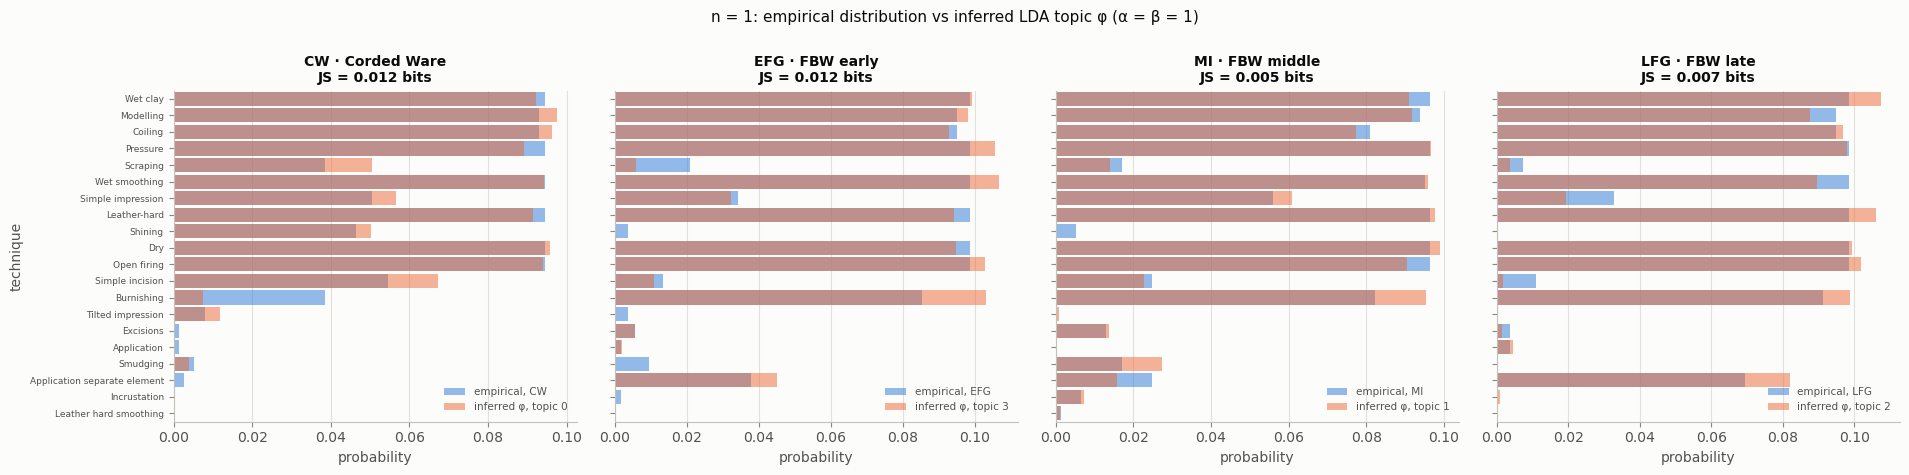

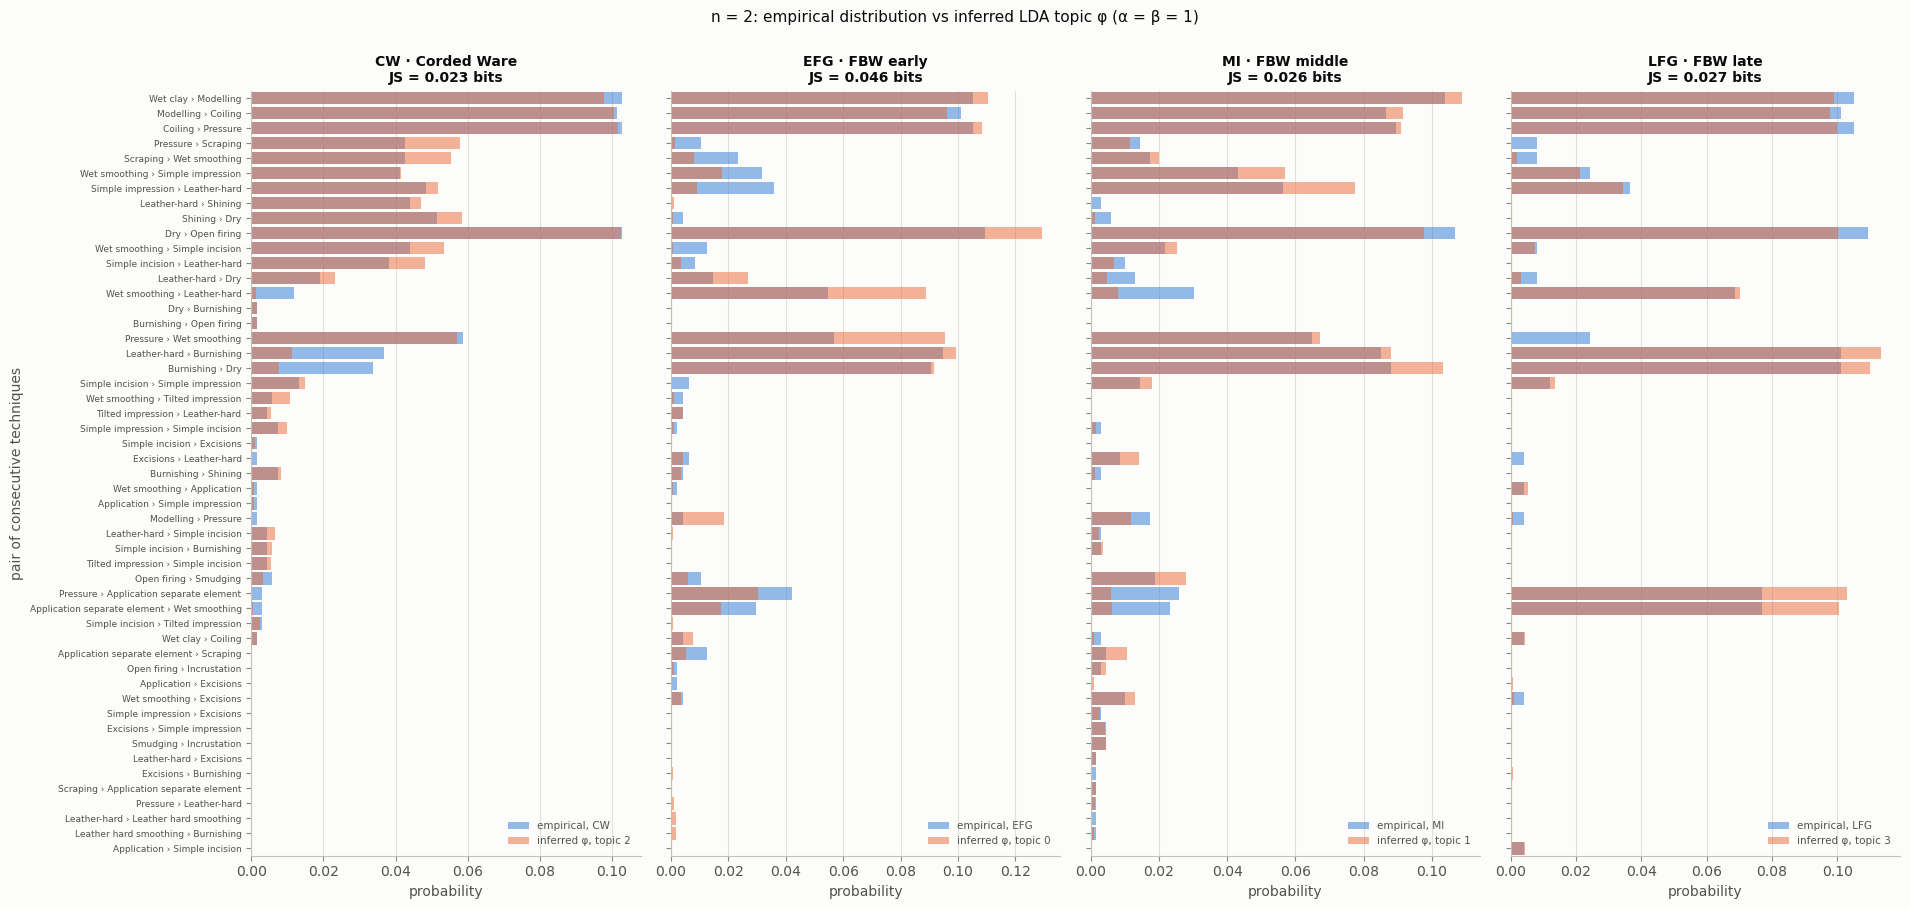

In [61]:
for n, token in [(1, "technique"), (2, "pair of consecutive techniques")]:
    m = lda_by_n[n]
    phi_n = m.lda.topic_word_dist[[m.mapping[c] for c in BOKS]]
    fig = overlay_distributions(m.empirical, phi_n, m.vocabulary, BOKS,
                                [f"inferred φ, topic {m.mapping[c]}" for c in BOKS],
                                f"n = {n}: empirical distribution vs inferred LDA topic φ (α = β = 1)",
                                js=[tm.js_divergence(e, f) for e, f in zip(m.empirical, phi_n)], token=token)
    plt.show()

## 10 · Networks, n-gram networks and sequences

Bags of n-grams ignore the order of the n-grams. Networks and sequence models keep it and give a probability to every whole chain, which is also what reconstruction needs.

### 10.1 The technique network of each BoK
Nodes are techniques ordered left to right by their average position in the chains; an arrow's width is the share of chains using that transition; grey nodes are not used by the BoK.

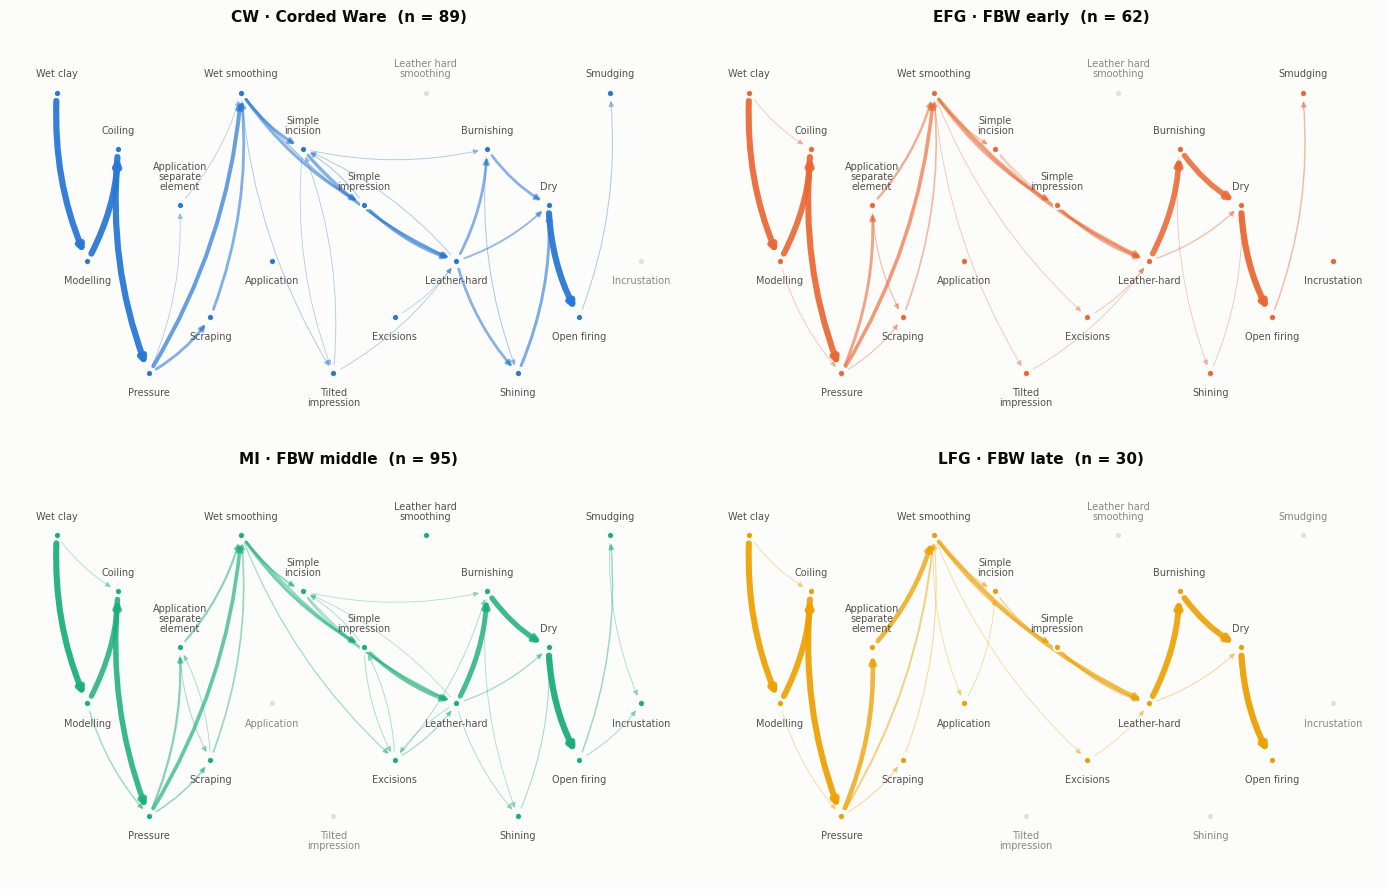

In [62]:
layout = pl.technique_layout(df["steps"])
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, b in zip(axes.flat, BOKS):
    chains = df.loc[df["bok"] == b, "steps"]
    pl.transition_graph(ax, chains, layout, pl.COLORS[b], title=f"{pl.label(b)}  (n = {len(chains)})")
fig.tight_layout(); pl.save(fig, "technique_networks"); plt.show()

### 10.2 Kroon's comparison and what it measures
Pathfinder (Kroon 2024, `module_compare_boks.py`) computes, for each of the 573 links of the technique network, the percentage of chains using it, and compares two BoKs with `scipy.stats.wasserstein_distance(weights_A, weights_B)`. Scipy reads the two lists as **samples of values**: the distance compares the *histograms* of edge usage and ignores **which** edge carries which weight. Relabelling the edges of one BoK leaves it unchanged:

In [63]:
links = pd.read_csv(ROOT / "data/clean/technique_links.csv")
edges = list(zip(links["source"], links["target"]))
groups = {b: list(df.loc[df["bok"] == b, "steps"]) for b in BOKS}
u, v = distances.edge_usage(groups["CW"], edges), distances.edge_usage(groups["MI"], edges)
from scipy.stats import wasserstein_distance
print(f"W(CW, MI)                        = {wasserstein_distance(u, v):.4f}")
print(f"W(CW, MI with edges relabelled)  = {wasserstein_distance(u, np.random.default_rng(1).permutation(v)):.4f}")

W(CW, MI)                        = 0.4392
W(CW, MI with edges relabelled)  = 0.4392


Next to it, two **edge-aware** statistics, each with a permutation test (labels shuffled between the two BoKs, 200 times): the Jensen–Shannon divergence between the two distributions over transitions (bits), and the symmetrised log-likelihood ratio of first-order Markov models fitted to each BoK — a plug-in estimate of the KL divergence between the two chain distributions (nats per chain).

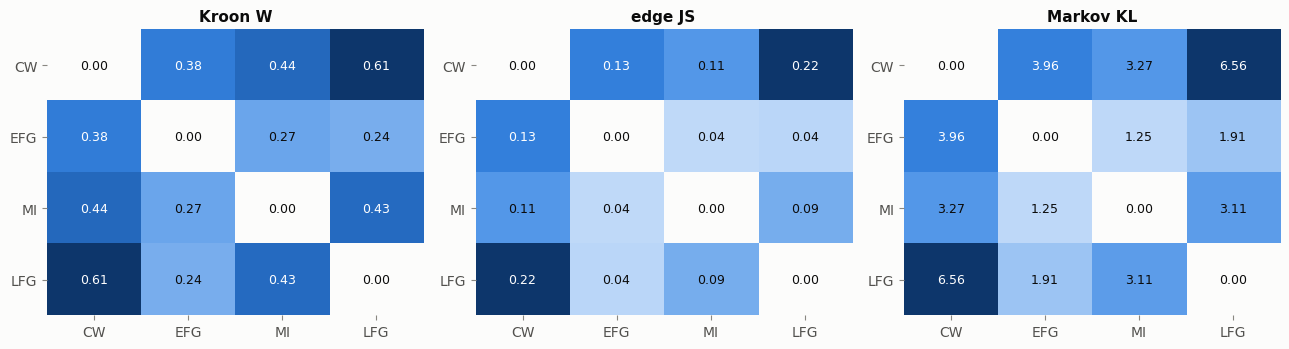

statistic,Kroon W,Markov KL,edge JS
pair,,,
CW–EFG,0.005,0.005,0.005
CW–LFG,0.005,0.005,0.005
CW–MI,0.005,0.005,0.005
EFG–LFG,0.030,0.015,0.055
EFG–MI,0.005,0.005,0.005
MI–LFG,0.005,0.005,0.005


In [64]:
make_markov = lambda chains: markov.MarkovChain(1, beta=2.0, vocab=vocab).fit(chains)
stats = {"Kroon W": lambda a, b: distances.kroon_wasserstein(a, b, edges),
         "edge JS": lambda a, b: distances.edge_js(a, b, edges),
         "Markov KL": lambda a, b: distances.markov_divergence(a, b, make_markov)}
rows = []
for i, a in enumerate(BOKS):
    for b in BOKS[i + 1:]:
        for name, stat in stats.items():
            obs, null, p = distances.permutation_test(stat, groups[a], groups[b], n_perm=200, seed=SEED)
            rows.append({"pair": f"{a}–{b}", "statistic": name, "value": obs, "p": p})
dist_table = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, name in zip(axes, stats):
    M = pd.DataFrame(0.0, index=BOKS, columns=BOKS)
    for r in dist_table[dist_table["statistic"] == name].itertuples():
        a, b = r.pair.split("–")
        M.loc[a, b] = M.loc[b, a] = r.value
    pl.heatmap(ax, M.values, BOKS, BOKS, fmt="{:.2f}"); ax.set_title(name)
fig.tight_layout(); pl.save(fig, "bok_distances"); plt.show()
dist_table.pivot(index="pair", columns="statistic", values="p").round(3)

**How to read it.**
- *Figure:* the three distances for each pair of BoKs.
- *Table:* the permutation p-value of each distance: the share of 200 random relabellings of the two BoKs' vessels giving a distance at least as large, computed as $(1+\#)/(1+200)$. The smallest possible value is $1/201=0.005$, so 0.005 means "never reached by chance in 200 tries".
- *Numbers:* every pair differs under every statistic except early vs late FBW under edge JS (p = 0.055).
- *Caveat:* the permutation shuffles vessels, not sites. Vessels of one site resemble each other, so for the FBW phases (7–14 sites) the p-values are somewhat optimistic.

The statistics agree on the ordering: **CW is farthest from late FBW, and the FBW phases are closest to each other**.

### 10.3 From the technique network to n-gram networks
**Definition.** For $n\ge1$, the *$n$-gram network* $G_n$ has the observed $n$-grams as nodes and an edge $g\to g'$ whenever $g'$ follows $g$ in some chain (the two overlap in $n-1$ steps). Its weight $N(g\to g')$ counts these occurrences, i.e. the $(n+1)$-gram that $g$ and $g'$ form. A start weight $N_{\rm start}(g)$ counts chains beginning with $g$, an end weight $N_{\rm end}(g)$ chains ending with it, and $N_{\rm out}(g)=\sum_{g'}N(g\to g')+N_{\rm end}(g)$. $G_1$ is Kroon's technique network; $G_2$ has pairs as nodes; $G_3$ is the "clustered" triplet graph of the legacy network notebook.

**Proposition 4 (walks on $G_n$ are order-$n$ Markov chains).** Consider the random walk that starts at $g$ with probability $N_{\rm start}(g)/M$ ($M$ chains), moves $g\to g'$ with probability $N(g\to g')/N_{\rm out}(g)$, and stops at $g$ with probability $N_{\rm end}(g)/N_{\rm out}(g)$. It gives every chain the probability of the maximum-likelihood Markov chain of order $n$, with contexts padded by a START symbol.

*Proof.* After emitting $x_t$ the walk is at $g=(x_{t-n+1},\dots,x_t)$. Every occurrence of $g$ is followed either by a step or by END, so $N_{\rm out}(g)$ is the count of the context $g$, and $N(g\to g')/N_{\rm out}(g)=N(x_{t-n+1}\dots x_{t+1})/N(x_{t-n+1}\dots x_t\,\cdot)=\hat p(x_{t+1}\mid x_{t-n+1},\dots,x_t)$ is the order-$n$ estimate; likewise for END. For the first $n$ steps, the count of the padded context $({\rm START}^{\,n-t+1},x_1,\dots,x_{t-1})$ is the number of chains beginning with $x_1\dots x_{t-1}$, so $\prod_{t=1}^{n}\hat p(x_t\mid{\rm START}^{\,n-t+1},x_{1:t-1})$ telescopes to $N_{\rm start}(x_1\dots x_n)/M$. $\square$

**Consequences.** Kroon's edge weights ($G_1$) define the first-order chain; a model of triplet *counts* is second order (walks on $G_2$); count-weighted walks on the legacy triplet graph $G_3$ are **third**-order chains. (With `type_edge_weight='probability'` the legacy code instead gave the $G_3$ edges the first-order weight $p(D\mid C)$.) By the Maximum-Caliber argument (auxiliary notebook, Part 3), walks on $G_n$ are also the Maximum-Caliber models constrained by $(n+1)$-gram counts. The proposition is checked below for $n=1,\dots,5$ on every chain, together with the structure of $G_n$ and of the walk it defines.

In [65]:
def ngram_graph(chains, n):
    """Weights of the n-gram network G_n: start, edge (= (n+1)-gram), end and out-weights."""
    start, edge, end = Counter(), Counter(), Counter()
    for s in chains:
        g = data.ngrams(s, n)
        start[g[0]] += 1; end[g[-1]] += 1
        edge.update(zip(g[:-1], g[1:]))
    out = Counter(end)
    for (a, _), c in edge.items():
        out[a] += c
    return {"start": start, "edge": edge, "end": end, "out": out, "M": len(chains)}

def walk_logprob(G, s, n):
    g = data.ngrams(s, n)
    lp = np.log(G["start"][g[0]] / G["M"]) + np.log(G["end"][g[-1]] / G["out"][g[-1]])
    return lp + sum(np.log(G["edge"][e] / G["out"][e[0]]) for e in zip(g[:-1], g[1:]))

observed_chains = set(map(tuple, df["steps"]))
rows = []
for n in range(1, 6):
    G = ngram_graph(df["steps"], n)
    mle = markov.MarkovChain(n, beta=0.0, alpha=0.0).fit(df["steps"])       # unsmoothed order-n chain
    gap = max(abs(walk_logprob(G, s, n) - mle.logprob(s)) for s in df["steps"])
    assert gap < 1e-9                                                       # Proposition 4
    successors = Counter(a for a, _ in G["edge"]) + Counter(G["end"].keys())    # distinct continuations (incl. END)
    paths, mass = markov.enumerate_paths(mle, max_len=30, min_prob=1e-9)
    rows.append({"n": n, "nodes": len(G["out"]), "edges": len(G["edge"]),
                 "mean continuations per node": np.mean(list(successors.values())),
                 "share of nodes with one continuation": np.mean([v == 1 for v in successors.values()]),
                 "distinct chains the walk produces (p > 1e-9)": len(paths),
                 "walk probability on the 101 observed chains": sum(p for s, p in paths if tuple(s) in observed_chains),
                 "max |log p_walk − log p_Markov|": gap})
pd.DataFrame(rows).set_index("n")

,nodes,edges,mean continuations per node,share of nodes with one continuation,distinct chains the walk produces (p > 1e-9),walk probability on the 101 observed chains,max |log p_walk − log p_Markov|
n,,,,,,,
1,20,52,2.750,0.200,171122,0.658,1.776e-15
2,52,96,1.942,0.538,3799,0.732,1.776e-15
3,96,164,1.781,0.562,1163,0.794,1.776e-15
4,164,235,1.518,0.689,472,0.856,1.776e-15
5,235,292,1.353,0.766,209,0.909,1.776e-15


**How to read it.** One row per $n$-gram network $G_n$. The columns give:
- the numbers of nodes and edges;
- the mean number of continuations per node;
- the share of nodes with a single continuation (no choice);
- how many distinct chains the walk can produce with probability above $10^{-9}$;
- the walk's total probability on the 101 observed chains;
- the largest difference between the walk's and the order-$n$ Markov chain's log-probabilities over all observed chains.

That last value, $1.8\times10^{-15}$, is zero to machine precision (Proposition 4).

Proposition 4 holds to machine precision for every chain and every $n$. As $n$ grows, $G_n$ gains nodes but loses branching: more nodes have a single continuation, and the walk concentrates on the observed chains. From 171 000 producible chains (66 % of the probability on the observed ones) at $n=1$, it falls to about 200 (91 %) at $n=5$ — the walk moves from *generalising* to *memorising*. The networks for CW and MI with techniques, pairs and triplets as nodes (edges used by at least 3 % of the chains; common layout per $n$):

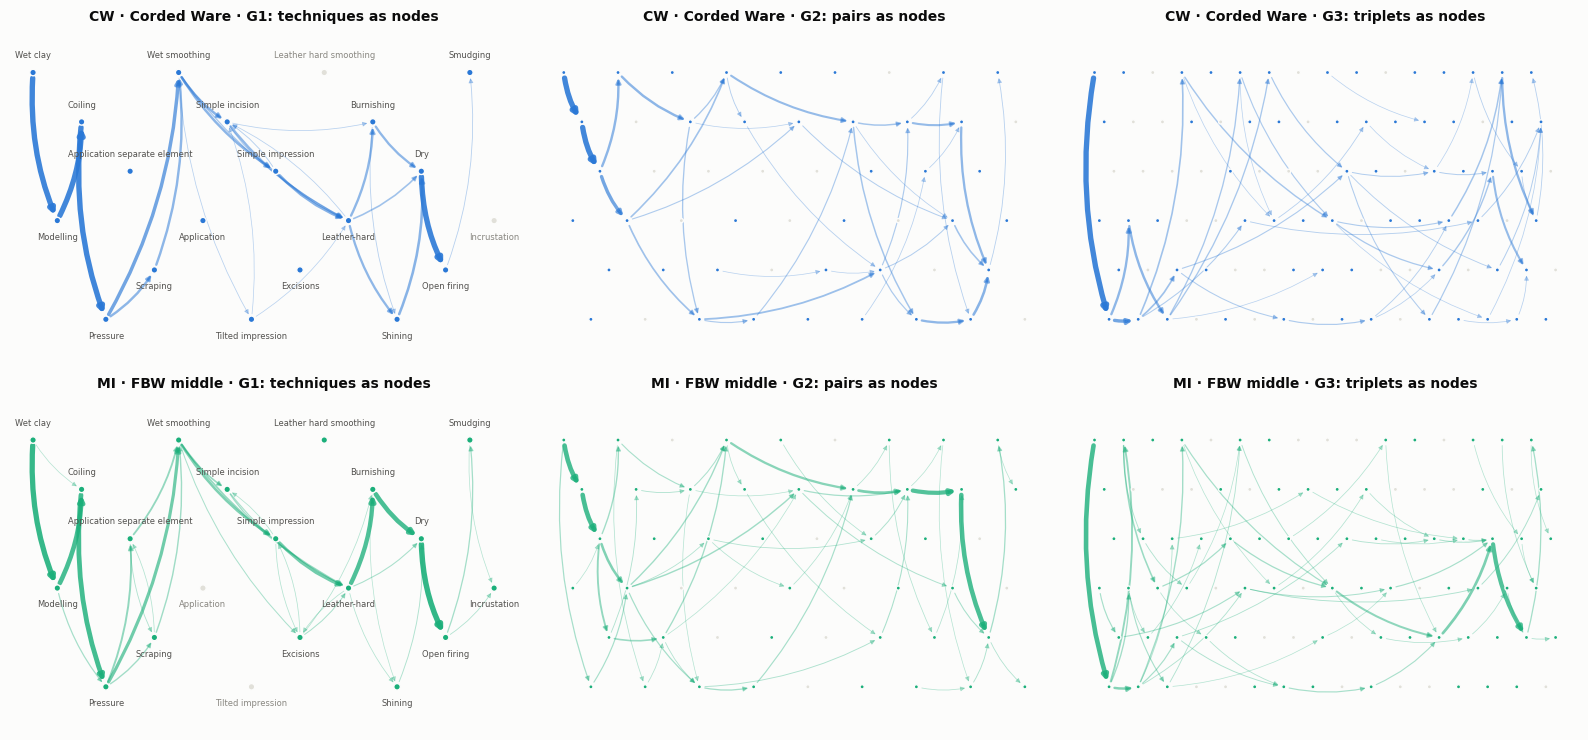

In [66]:
def draw_ngram_graph(ax, chains, layout, n, color, title, min_share=0.03):
    seqs = [data.ngrams(s, n) for s in chains]
    counts = Counter(e for g in seqs for e in zip(g[:-1], g[1:]))
    used = {x for g in seqs for x in g}
    ax.set_axis_off()
    for (a, b), c in counts.items():
        share = c / len(chains)
        if share >= min_share:
            (x0, y0), (x1, y1) = layout[a], layout[b]
            ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                        arrowprops=dict(arrowstyle="-|>", color=color, lw=0.4 + 3.5 * share, alpha=0.3 + 0.6 * share,
                                        shrinkA=4, shrinkB=4, connectionstyle="arc3,rad=0.12", mutation_scale=7))
    keys = list(layout)
    ax.scatter([layout[k][0] for k in keys], [layout[k][1] for k in keys], s=22 if n == 1 else 9, zorder=3,
               color=[color if k in used else pl.INK["grid"] for k in keys], edgecolor=pl.INK["surface"], linewidth=1)
    if n == 1:
        for k in keys:
            x, y = layout[k]
            ax.text(x, y + (0.1 if y >= 0 else -0.1), k[0], ha="center", va="bottom" if y >= 0 else "top",
                    fontsize=6, color=pl.INK["secondary"] if k in used else pl.INK["muted"])
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-1.35, 1.35); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for j, (n, word) in enumerate([(1, "techniques"), (2, "pairs"), (3, "triplets")]):
    layout_n = pl.technique_layout([data.ngrams(s, n) for s in df["steps"]])
    for i, b in enumerate(["CW", "MI"]):
        draw_ngram_graph(axes[i, j], groups[b], layout_n, n, pl.COLORS[b], f"{pl.label(b)} · G{n}: {word} as nodes")
fig.tight_layout(); plt.show()

**Entropy rate: memorisation vs structure.** Order $k$ corresponds to walks on $G_k$ ($k=0$: techniques drawn independently). The in-sample (plug-in) entropy rate $\hat h_k=-\frac1T\sum\log_2\hat p_k(x_t\mid\text{context})$ over all $T$ predicted symbols (END included) cannot increase with $k$. Under the empirical measure, with START padding, the order-$(k+1)$ context refines the order-$k$ context on the same positions, and conditioning cannot increase entropy (Cover & Thomas 2006, Thm 2.6.5). So $\hat h_k$ measures memorisation. The honest measure is the held-out cross-entropy (5-fold, smoothing $\beta$ chosen per order), without and with Kroon's grammar. The same held-out log-likelihoods give the paired comparison between orders in nats per chain.

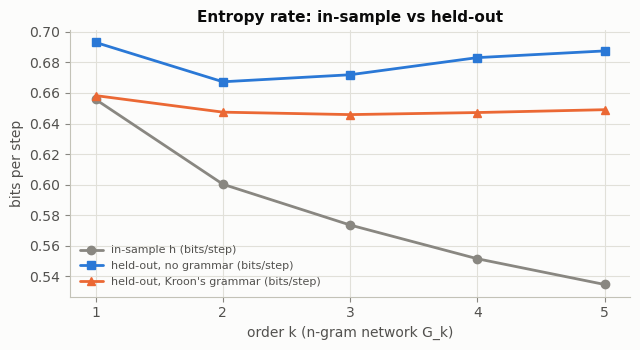

,in-sample h (bits/step),"held-out, no grammar (bits/step)","held-out, Kroon's grammar (bits/step)"
order k (walk on G_k),,,
0,3.864,3.867,1.294
1,0.656,0.693,0.658
2,0.600,0.667,0.647
3,0.574,0.672,0.646
4,0.551,0.683,0.647
5,0.535,0.688,0.649


,best beta,held-out log-lik / chain (nats),difference vs order 1,se of difference
order,,,,
0,0.5,-10.247,-5.033,0.135
1,8.0,-5.214,0.000,0.000
2,32.0,-5.128,0.086,0.026
3,32.0,-5.116,0.099,0.042
4,32.0,-5.126,0.088,0.054
5,32.0,-5.141,0.073,0.065


In [67]:
folds = ev.splits(df, "stratified", N_FOLDS, SEED)
T_sym = sum(len(s) + 1 for s in df["steps"])                 # predicted symbols, END included
heldout = {}                                                  # (order, grammar?, beta) -> held-out log-lik of every vessel
for k in range(0, 6):
    for use_grammar in (False, True):
        for beta in [0.5, 2, 8, 32, 128]:
            ll = np.zeros(len(df))
            for tr, te in folds:
                m = markov.MarkovChain(k, beta, grammar=grammar if use_grammar else None, vocab=vocab).fit(df["steps"].iloc[tr])
                ll[te] = [m.logprob(s) for s in df["steps"].iloc[te]]
            heldout[(k, use_grammar, beta)] = ll
best_beta = {(k, g_): max((b for (kk, gg, b) in heldout if (kk, gg) == (k, g_)), key=lambda b: heldout[(k, g_, b)].mean())
             for k in range(6) for g_ in (False, True)}
bits = lambda ll: -ll.sum() / T_sym / np.log(2)
h_in = [-sum(markov.MarkovChain(k, beta=0.0, alpha=0.0).fit(df["steps"]).logprob(s) for s in df["steps"]) / T_sym / np.log(2)
        for k in range(6)]
assert np.all(np.diff(h_in) <= 1e-12)                          # in-sample entropy rate is non-increasing in k
entropy = pd.DataFrame({"in-sample h (bits/step)": h_in,
                        "held-out, no grammar (bits/step)": [bits(heldout[(k, False, best_beta[(k, False)])]) for k in range(6)],
                        "held-out, Kroon's grammar (bits/step)": [bits(heldout[(k, True, best_beta[(k, True)])]) for k in range(6)]},
                       index=pd.Index(range(6), name="order k (walk on G_k)"))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for col, color, marker in zip(entropy.columns, [pl.INK["muted"], pl.COLORS["CW"], pl.COLORS["EFG"]], ["o", "s", "^"]):
    ax.plot(entropy.index[1:], entropy[col].iloc[1:], color=color, marker=marker, ms=6, label=col)
ax.set_xticks(range(1, 6)); ax.set_xlabel("order k (n-gram network G_k)"); ax.set_ylabel("bits per step")
ax.set_title("Entropy rate: in-sample vs held-out"); ax.legend(fontsize=8); fig.tight_layout(); plt.show()
ref = heldout[(1, True, best_beta[(1, True)])]
paired = pd.DataFrame([{"order": k, "best beta": best_beta[(k, True)],
                        "held-out log-lik / chain (nats)": heldout[(k, True, best_beta[(k, True)])].mean(),
                        "difference vs order 1": (heldout[(k, True, best_beta[(k, True)])] - ref).mean(),
                        "se of difference": (heldout[(k, True, best_beta[(k, True)])] - ref).std() / np.sqrt(len(df))}
                       for k in range(6)]).set_index("order")
display(entropy.round(4))
paired

The in-sample entropy rate falls monotonically, as it must, from 3.86 bits for independent techniques to 0.53 bits at order 5. The held-out cross-entropy instead has a minimum. Without the grammar it is lowest at order 2 (walks on $G_2$, triplet statistics); with Kroon's grammar, which already removes impossible continuations, orders 2–5 are nearly indistinguishable (0.646–0.649 bits per step). In the paired comparison, orders 2 and 3 gain 0.09–0.10 nats per chain over order 1, beyond two standard errors (order 2: 0.086 ± 0.026); orders 4 and 5 gain no more, with growing uncertainty. **Pairs capture most of the sequential structure; going beyond pairs adds about 0.1 nats per chain, and windows longer than triplets add nothing measurable.**

**Separation between BoKs as the window grows.** Divergence between the BoKs' transition distributions on $G_n$ (edge JS, as in 10.2), with a permutation null (labels shuffled, 200 times). Raw divergences grow with $n$ for every pair — including under the null, because the edges become sparser — so the comparison is made through the $z$-score $(\mathrm{JS}-\overline{\mathrm{JS}}_{\rm null})/\mathrm{sd}_{\rm null}$.

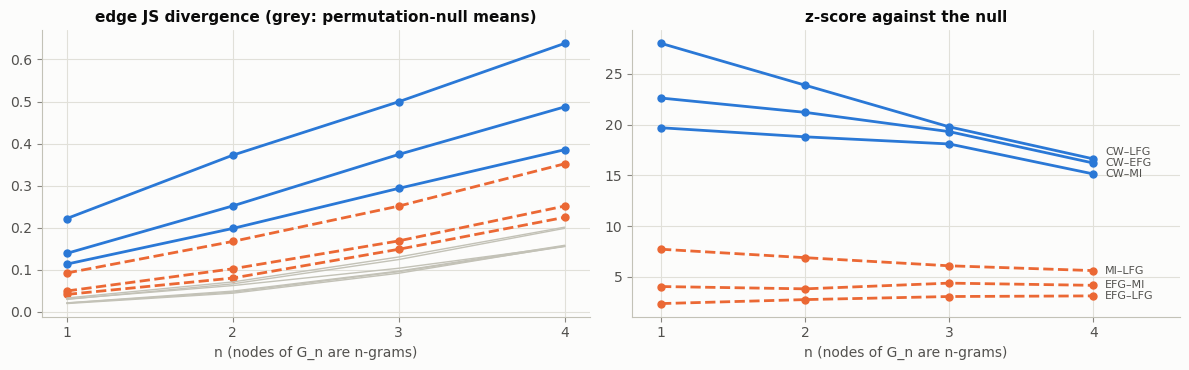

n,1,2,3,4
pair,,,,
CW–EFG,0.005,0.005,0.005,0.005
CW–LFG,0.005,0.005,0.005,0.005
CW–MI,0.005,0.005,0.005,0.005
EFG–LFG,0.025,0.010,0.005,0.005
EFG–MI,0.005,0.010,0.010,0.010
MI–LFG,0.005,0.005,0.005,0.005


In [68]:
rows = []
for n in range(1, 5):
    seqs = {b: [data.ngrams(s, n) for s in groups[b]] for b in BOKS}
    E = sorted({e for b in BOKS for g in seqs[b] for e in zip(g[:-1], g[1:])}, key=str)
    for i, a in enumerate(BOKS):
        for b in BOKS[i + 1:]:
            obs_js, null, p = distances.permutation_test(lambda A, B: distances.edge_js(A, B, E), seqs[a], seqs[b], 200, SEED)
            rows.append({"n": n, "pair": f"{a}–{b}", "JS (bits)": obs_js, "null mean": null.mean(),
                         "z": (obs_js - null.mean()) / null.std(), "p": p})
separation = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
label_y = {}
for pair, part in separation.groupby("pair", sort=False):
    fbw_internal = "CW" not in pair
    style = dict(color=pl.COLORS["EFG"] if fbw_internal else pl.COLORS["CW"], ls="--" if fbw_internal else "-", marker="o", ms=5)
    axes[0].plot(part["n"], part["JS (bits)"], **style)
    axes[0].plot(part["n"], part["null mean"], color=pl.INK["axis"], lw=1)
    axes[1].plot(part["n"], part["z"], **style)
    label_y[pair] = part["z"].iloc[-1]
placed = []                                                    # direct labels, spaced so they do not collide
for pair, y in sorted(label_y.items(), key=lambda kv: kv[1]):
    y = max(y, placed[-1] + 1.1) if placed else y
    placed.append(y)
    axes[1].text(4.08, y, pair, fontsize=8, va="center", color=pl.INK["secondary"])
axes[0].set_title("edge JS divergence (grey: permutation-null means)"); axes[1].set_title("z-score against the null")
for ax in axes:
    ax.set_xticks(range(1, 5)); ax.set_xlabel("n (nodes of G_n are n-grams)")
axes[1].set_xlim(0.8, 4.6); fig.tight_layout(); plt.show()
separation.pivot(index="pair", columns="n", values="p")

**How to read it.**
- *Left figure:* the edge-JS divergence of each pair of BoKs (blue solid: CW vs an FBW phase; orange dashed: two FBW phases) and the means of its permutation null (grey).
- *Right figure:* the separation $z$ of each pair, in standard deviations of its null.
- *Table:* the permutation p-values, as in 10.2 (0.005 = never reached in 200 permutations).
- *Numbers:* every pair is significant at every $n$ (largest p = 0.025, early vs late FBW at $n=1$). The CW pairs fall from $z$ = 20–28 to 15–17; the FBW pairs stay at 2.4–7.8.

Raw divergences grow with $n$, but so does the null. Against the null, the separation of CW from the FBW phases is strongest for single transitions and *decreases* with $n$, while the FBW phases stay weakly separated at every $n$. Longer windows do not reveal sharper cultural contrasts; they spread the same evidence over sparser edges.

### 10.4 Posterior predictive check
Walks from the fitted models, with an explicit `END` symbol and Kroon's grammar (the legacy walks stopped with the unconditional share of chains ending at a node, inverted in one version):

order 1: 70% of simulated chains were observed; 657 distinct simulated chains


order 2: 72% of simulated chains were observed; 581 distinct simulated chains


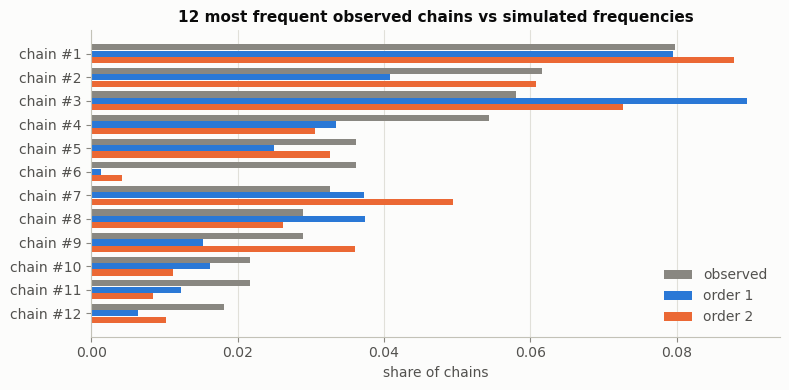

In [69]:
rng = np.random.default_rng(SEED)
emp = df["chain"].value_counts(normalize=True)
sim = {}
for order, beta in [(1, 2.0), (2, 8.0)]:
    m = markov.MarkovChain(order, beta, grammar=grammar, vocab=vocab).fit(df["steps"])
    walks = pd.Series([" > ".join(m.sample(rng)) for _ in range(5000)])
    sim[f"order {order}"] = walks.value_counts(normalize=True)
    print(f"order {order}: {walks.isin(set(df['chain'])).mean():.0%} of simulated chains were observed; "
          f"{walks.nunique()} distinct simulated chains")
top_chains = emp.index[:12]
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(top_chains))
ax.barh(y - 0.27, emp[top_chains], height=0.26, color=pl.INK["muted"], label="observed")
ax.barh(y, sim["order 1"].reindex(top_chains).fillna(0), height=0.26, color=pl.COLORS["CW"], label="order 1")
ax.barh(y + 0.27, sim["order 2"].reindex(top_chains).fillna(0), height=0.26, color=pl.COLORS["EFG"], label="order 2")
ax.set_yticks(y, [f"chain #{i + 1}" for i in range(len(top_chains))]); ax.invert_yaxis()
ax.set_xlabel("share of chains"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("12 most frequent observed chains vs simulated frequencies"); fig.tight_layout(); plt.show()

**How to read it.**
- *Printed lines:* 5000 chains sampled from the Markov models fitted to all vessels, within Kroon's grammar. 70 % (order 1) and 72 % (order 2) of them are chains that were actually observed; the rest are new but grammatical combinations.
- *Figure:* the 12 most frequent observed chains (grey) and how often each model produces them. Both models get most of the frequent chains roughly right. Chain #6 is almost never produced (0.1–0.4 %, against 3.6 % observed): its transitions are individually rare even though the whole chain is common.
- *Caveat:* this is an in-sample check, since the models were fitted on these chains.

### 10.5 Attribution from fragments
A Markov model scores an unfinished chain by marginalising over its continuations (`logprob(steps, complete=False)`). Accuracy when only the first $t$ steps are known (sites held out, order 1):

In [70]:
site_folds = ev.splits(df, "site", N_FOLDS, SEED)
rows = []
for t in [3, 4, 5, 6, 7, 8, None]:
    pred = np.zeros((len(df), len(BOKS)))
    for tr, te in site_folds:
        m = clf.MarkovClassifier(1, 2.0, grammar=grammar).fit(df.iloc[tr])
        part = df.iloc[te].copy()
        if t is not None:
            part["steps"] = part["steps"].map(lambda s: s[:t])
        pred[te] = m.predict_proba(part, complete=t is None)
    rows.append({"known steps": "all" if t is None else t, "accuracy": ev.scores(y_bok, pred)["accuracy"]})
pd.DataFrame(rows).set_index("known steps").T

known steps,3,4,5,6,7,8,all
accuracy,0.366,0.37,0.417,0.464,0.489,0.514,0.533


**How to read it.**
- *Shown:* accuracy when only the first $t$ steps of each held-out vessel are known (sites held out, seed 0, order-1 Markov model).
- *Numbers:* 0.37 with 3–4 steps (the majority rule gives 0.34), rising steadily to 0.51 with 8 steps and 0.53 with the whole chain.
- *Evidence:* with ± 0.04–0.05 per value the trend is clear, but the step-to-step differences are not.

The first three or four steps (wet clay, modelling, coiling, pressure) are shared by everyone and give the majority baseline; accuracy grows as finishing, decoration and surface treatment become known.

### 10.6 Reconstructing incomplete chains (Question 2)
Given the steps before and after a gap, the most probable fillers are found exactly by uniform-cost search (`MarkovChain.complete`), within Kroon's grammar (extended with the one observed transition absent from his link list, `Application separate element → Scraping`, 12 vessels). Masking experiment: for each held-out vessel (5-fold CV) hide a random block of $m=1,2,3$ steps and check whether the true block is the top-1 or among the top-3 proposals. Baseline: the most frequent training chains matching the known prefix and suffix.

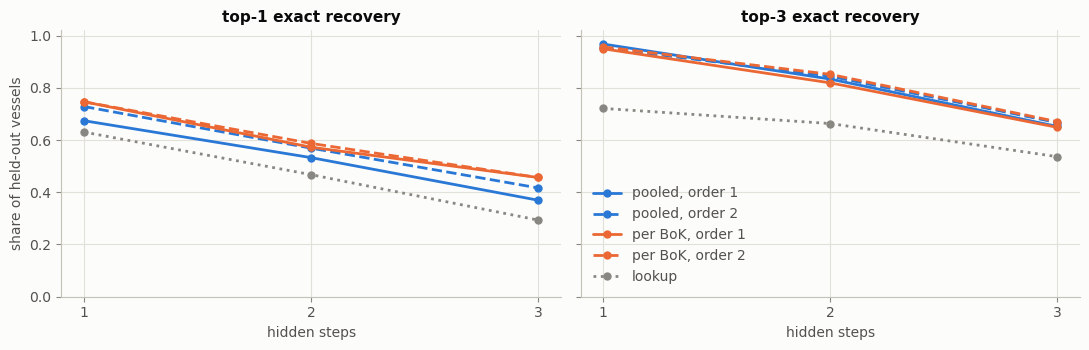

gap                   1             2             3       
metric            top-1  top-3  top-1  top-3  top-1  top-3
model                                                     
lookup            0.630  0.721  0.467  0.663  0.293  0.536
per BoK, order 1  0.746  0.949  0.572  0.819  0.457  0.649
per BoK, order 2  0.746  0.957  0.587  0.851  0.457  0.670
pooled, order 1   0.674  0.967  0.533  0.833  0.370  0.652
pooled, order 2   0.728  0.953  0.569  0.844  0.417  0.667

In [71]:
gaps = reconstruction.gap_experiment(df, grammar, ev.splits(df, "stratified", N_FOLDS, SEED), gap_sizes=(1, 2, 3), k=3, seed=SEED)
gap_table = reconstruction.summarise_gaps(gaps)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
styles = {"pooled, order 1": (pl.COLORS["CW"], "-"), "pooled, order 2": (pl.COLORS["CW"], "--"),
          "per BoK, order 1": (pl.COLORS["EFG"], "-"), "per BoK, order 2": (pl.COLORS["EFG"], "--"),
          "lookup": (pl.INK["muted"], ":")}
for ax, metric in zip(axes, ["top-1", "top-3"]):
    for name, (color, ls) in styles.items():
        ax.plot([1, 2, 3], gap_table.xs(metric, axis=1, level="metric").loc[name].values,
                color=color, ls=ls, marker="o", ms=5, label=name)
    ax.set_xticks([1, 2, 3]); ax.set_xlabel("hidden steps"); ax.set_title(f"{metric} exact recovery")
axes[0].set_ylabel("share of held-out vessels"); axes[0].set_ylim(0, 1.02); axes[1].legend(loc="lower left")
fig.tight_layout(); pl.save(fig, "reconstruction"); plt.show()
gap_table

**How to read it.**
- *Shown:* for held-out vessels (5-fold by vessel, seed 0), a random block of 1, 2 or 3 consecutive steps is hidden.
  - *top-1:* the model's best proposal is exactly the hidden block;
  - *top-3:* the hidden block is among the three best proposals.

  Rows: the lookup of matching training chains, and Markov models of order 1 and 2, either per BoK (true BoK known) or pooled.
- *Numbers:*
  - one hidden step: the Markov models score 0.67–0.75 top-1 and 0.95–0.97 top-3, against 0.63 / 0.72 for the lookup;
  - three hidden steps: 0.37–0.46 top-1 and 0.65–0.67 top-3, against 0.29 / 0.54.
- *Caveat:* vessels (not sites) are held out, so site-mates are in the training data. "Per BoK" uses the true BoK, an optimistic assumption for a new find.

In [72]:
# Worked example: a CW vessel whose decoration and surface treatment are hidden
v = df[df["bok"] == "CW"].iloc[1]
s = list(v["steps"])
i, j = s.index("Wet smoothing") + 1, s.index("Dry")
m_cw = markov.MarkovChain(1, 2.0, grammar=grammar, vocab=vocab).fit(
    df.loc[(df["bok"] == "CW") & (df["vessel_id"] != v["vessel_id"]), "steps"])
print("known  :", " > ".join(s[:i]), "> [ ? ] >", " > ".join(s[j:]))
print("hidden :", " > ".join(s[i:j]))
print("top-5 fillers from a CW model fitted without this vessel (probabilities renormalised over the 5):")
fills = m_cw.complete(s[:i], s[j:], k=5)
z = sum(np.exp(lp) for _, lp in fills)
for fill, lp in fills:
    print(f"  {np.exp(lp) / z:.2f}  {' > '.join(fill)}{'   <- true' if fill == s[i:j] else ''}")

known  : Wet clay > Modelling > Coiling > Pressure > Scraping > Wet smoothing > [ ? ] > Dry > Open firing
hidden : Simple impression > Leather-hard > Shining
top-5 fillers from a CW model fitted without this vessel (probabilities renormalised over the 5):
  0.23  Simple impression > Leather-hard > Shining   <- true
  0.21  Simple impression > Leather-hard > Burnishing
  0.21  Simple incision > Leather-hard > Shining
  0.19  Simple incision > Leather-hard > Burnishing
  0.15  Simple impression > Leather-hard


Knowing the BoK improves the first guess (one hidden step: 0.75 per BoK against 0.67–0.73 pooled), and order 2 helps the pooled model (0.67 → 0.73) but not the per-BoK one (0.75 both). All Markov models beat the lookup of matching training chains, which cannot propose unseen combinations. In practice: attribute first (Section 7), then complete with that BoK's model, or average over the BoK posterior.

### 10.7 Influence between the cultures, and time
**What "influence" would mean.** Take a technique $\tau$ typical of FBW, for example burnishing (88 % of FBW vessels, 43 % of CW). "FBW potters influenced CW potters" means that a CW vessel is more likely to carry $\tau$ when its makers were in contact with FBW potters:
$$\operatorname{logit}P(\tau_i=1\mid c_i=\mathrm{CW})=a+b\,E_i,\qquad H_0:\ b=0.$$
The *exposure* $E_i$ measures contact: FBW potters living at the same time and nearby. For example,
$$E_i=\sum_{j\in\mathrm{FBW}}K\!\left(d_{ij}/h\right)\,\mathbf 1\big[\,|t_i-t_j|<\Delta\,\big],$$
with $d_{ij}$ the distance between find spots, $t$ the date, $K$ a kernel of width $h$ and $\Delta$ a time window.

**Why similarity is not enough.** CW and FBW share chains (1.2) and topics (5.3). But write the CW practice as a mixture,
$$p_{\rm CW}=(1-\varepsilon)\,p^0_{\rm CW}+\varepsilon\,p_{\rm FBW},$$
where $p^0_{\rm CW}$ — CW without contact — is unknown. Then any $\varepsilon$ fits the data for a suitable $p^0_{\rm CW}$. As with survival (auxiliary notebook, Prop. 3), the effect is identified only against a reference without contact: earlier, or farther away. Shared function (beakers) and shared inheritance also produce similarity.

**Is time in the metadata?** Not per vessel.
- Relative time is only in the labels: EFG → MI → LFG are successive FBW phases, and CW is not subdivided.
- Kroon's Appendix A (`data/source/dans/Appendices/Appendix_A_Radiocarbon_dates/`) has 62 radiocarbon dates from 35 sites (16 CW, 44 FBW, 2 AOO). They are tied to sites and typochronological horizons, not to our vessels, and only 7 of their site names match ours exactly. Building $t_i$ means dating the sites, from these dates and the typochronology. 10.8 uses the dates at the level of the groups, where Kroon's models place them.

**What the data allow now: space only.** With $\Delta=\infty$, the exposure reduces to the distance from a CW vessel's site to the nearest FBW site. We use either all FBW phases, or late FBW only — the phase that co-existed with CW (Kroon et al. 2025, *Parallel societies*). For five techniques, the test correlates their presence in CW vessels with nearness (Spearman), and judges the correlation against 999 random reassignments of the CW site locations (site-level permutation).

In [73]:
from scipy.stats import spearmanr

def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km."""
    r = np.pi / 180
    a = np.sin((lat2 - lat1) * r / 2) ** 2 + np.cos(lat1 * r) * np.cos(lat2 * r) * np.sin((lon2 - lon1) * r / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

geo = df.dropna(subset=["latitude"])
cw = geo[geo["bok"] == "CW"]
rows, rng = [], np.random.default_rng(SEED)
for target, mask in [("any FBW site", geo["bok"] != "CW"), ("late-FBW site", geo["bok"] == "LFG")]:
    fbw = geo[mask].drop_duplicates("site_id")
    nearness = pd.Series([-haversine(la, lo, fbw["latitude"].values, fbw["longitude"].values).min()
                          for la, lo in zip(cw["latitude"], cw["longitude"])], index=cw.index)    # − km to the nearest
    per_site = nearness.groupby(cw["site_id"]).first()
    for tech in ["Burnishing", "Application separate element", "Scraping", "Shining", "Smudging"]:
        has = cw["steps"].map(lambda s, t=tech: t in s).astype(int)
        rho = spearmanr(has, nearness).correlation
        null = []
        for _ in range(999):                                      # shuffle locations between CW sites
            moved = dict(zip(per_site.index, rng.permutation(per_site.values)))
            null.append(spearmanr(has, cw["site_id"].map(moved)).correlation)
        rows.append({"technique": tech, "in CW": has.mean(),
                     "in FBW": df.loc[df["bok"] != "CW", "steps"].map(lambda s, t=tech: t in s).mean(),
                     "nearness to": target, "ρ": rho, "p": (1 + np.sum(np.array(null) >= rho)) / 1000})
influence = pd.DataFrame(rows).pivot(index=["technique", "in CW", "in FBW"], columns="nearness to", values=["ρ", "p"])
print(f"{len(cw)} CW vessels at {cw['site_id'].nunique()} sites; ρ > 0: the technique is more frequent closer to FBW")
influence.round(3)

86 CW vessels at 62 sites; ρ > 0: the technique is more frequent closer to FBW


ρ                \
nearness to                               any FBW site late-FBW site   
technique                    in CW in FBW                              
Application separate element 0.023 0.412         0.109         0.187   
Burnishing                   0.430 0.877         0.076         0.094   
Scraping                     0.395 0.187        -0.104        -0.182   
Shining                      0.430 0.048        -0.045        -0.106   
Smudging                     0.058 0.123        -0.090         0.034   

                                                     p                
nearness to                               any FBW site late-FBW site  
technique                    in CW in FBW                             
Application separate element 0.023 0.412         0.172         0.054  
Burnishing                   0.430 0.877         0.263         0.173  
Scraping                     0.395 0.187         0.815         0.938  
Shining                      0.430 0.048         0.673         0.785  
Smudging                     0.058 0.123         0.784         0.403

**How to read it.** One row per technique, with its share among CW vessels and among FBW vessels. $\rho$ is the rank correlation between "the CW vessel has the technique" and the nearness of its site to an FBW site; $p$ is the one-sided permutation p-value (a $\rho$ at least this large by chance).
- *Evidence:* no correlation is beyond chance. The smallest p, 0.05, is for separately applied elements near late-FBW sites — a technique found in only 2 of the 86 CW vessels, and one of 10 tests.
- *Direction:* the signs are those that influence would predict, but this is suggestive, not evidence.
  - The FBW-typical techniques (applied elements, burnishing) are slightly more frequent in CW vessels near FBW sites ($\rho$ = +0.08 to +0.19).
  - The CW-typical ones (scraping, shining) are slightly less frequent there ($\rho$ = −0.05 to −0.18).
- *Limits:*
  - There is no time: an early or middle FBW site nearby may be centuries older than the CW vessel.
  - The sample is 86 vessels at 62 sites.
  - Form and context are not controlled.

  A real test needs dated sites ($t_i$), a contact-free reference, and vessel form in the model.


### 10.8 Time: radiocarbon dates and which techniques moved
**Time in the data.** No vessel is dated. Kroon's Appendix A (`data/source/dans/.../Appendix_A_Radiocarbon_dates/`) has 62 radiocarbon dates from 35 sites. His Bayesian chronological models (OxCal; Appendix A, models 3 and 4) put every date in one of three groups:
- **EFG = early flat graves** (16 dates): graves with charred wooden structures and a broad spectrum of vessels;
- **LFG = late flat graves** (28 dates): cremation burials with large, complex bowls;
- **CW** (18 dates, 2 of them All-Over-Ornamented beakers).

So EFG and LFG are, by Kroon's definition, burial groups that follow each other in time; the time of a vessel is the time of its group. Middle FBW (MI, almost all from megaliths, which were used through the whole period) is not dated as a group.

Each date is calibrated with IntCal20 (Reimer et al. 2020; `data/source/intcal20/`): on a grid of calendar years $t$,
$$p(t\mid a\pm e)\propto\mathcal N\!\big(a;\ \mu(t),\ e^2+s(t)^2\big),$$
where $a\pm e$ is the radiocarbon age and $\mu(t)\pm s(t)$ the calibration curve (`chaine.chronology`, as OxCal's `R_Date`). The figure shows the dates of each group summed and divided by their number. This is a summary, not a model of the start and end of each group; for those we quote Kroon's OxCal models.

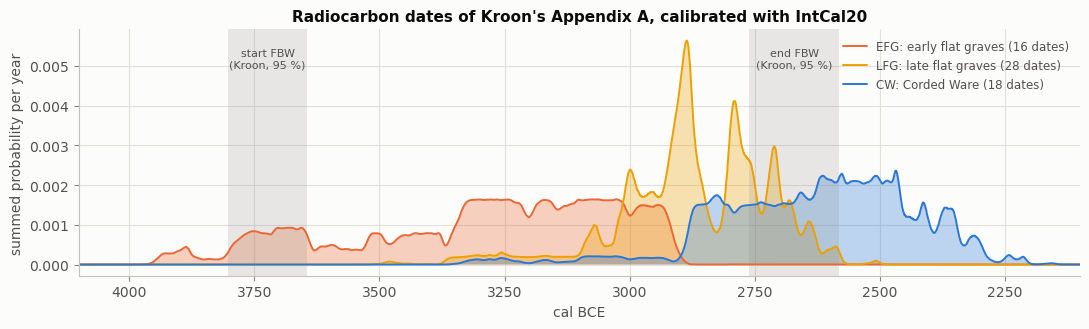

,dates,95 % of the summed dates (cal BCE),median (cal BCE)
group,,,
EFG,16,3865–2929,3243
LFG,28,3265–2631,2875
CW,18,3089–2311,2607


NameError: name 'df' is not defined

In [10]:
from chaine import chronology as chron
dates = chron.load_dates()
years = np.arange(2000, 4301)                                         # cal BCE
curve = chron.load_curve()
cal = np.array([chron.calibrate(a, e, years, curve) for a, e in zip(dates["age"], dates["error"])])
names108 = {"EFG": "early flat graves", "LFG": "late flat graves", "CW": "Corded Ware"}
fig, ax = plt.subplots(figsize=(11, 3.4))
rows = []
for g in ["EFG", "LFG", "CW"]:
    m = (dates["kroon_group"] == g).to_numpy()
    spd = cal[m].mean(0)
    ax.fill_between(years, spd, color=pl.COLORS[g], alpha=0.3, lw=0)
    ax.plot(years, spd, color=pl.COLORS[g], lw=1.4, label=f"{g}: {names108[g]} ({m.sum()} dates)")
    lo, hi = chron.interval(years, spd)
    rows.append({"group": g, "dates": m.sum(), "95 % of the summed dates (cal BCE)": f"{lo}–{hi}",
                 "median (cal BCE)": chron.interval(years, spd, 0.0)[0]})
for name, (lo, hi) in chron.KROON_BOUNDARIES.items():
    ax.axvspan(hi, lo, color=pl.INK["muted"], alpha=0.18, lw=0)
    ax.text((lo + hi) / 2, ax.get_ylim()[1] * 0.92, f"{name}\n(Kroon, 95 %)", ha="center", va="top", fontsize=8, color=pl.INK["secondary"])
ax.set_xlim(4100, 2100); ax.set_xlabel("cal BCE"); ax.set_ylabel("summed probability per year")
ax.legend(loc="upper right", fontsize=8.5); ax.set_title("Radiocarbon dates of Kroon's Appendix A, calibrated with IntCal20")
fig.tight_layout(); pl.save(fig, "chronology"); plt.show()
display(pd.DataFrame(rows).set_index("group"))

# our sites that carry dates themselves (names matched by hand; the dated context is not necessarily our vessels' grave)
same_site = {"Dalfsen": (["Dalfsen"], ["Dalfsen"]), "Angelslo": (["Angelslo"], ["Angelslo", "Emmen-Angelslo"]),
             "Noordbarge": (["Noordbarge"], ["Noordbarge"]), "Uddelermeer": (["Uddelermeer"], ["Uddelermeer"]),
             "D32a, D32d": (["D32a", "D32d"], ["D32"]), "Hijkerveld": (["Hijkerveld"], ["Hijkerveld"]),
             "Noordbarge-Hoge Loo": (["Noordbarge-Hoge Loo"], ["Noordbarge-Hoge Loo", "Noorbarge-Hoge Loo"]),
             "Annen-Holtkampen": (["Annen-Holtkampen"], ["Annen-Holtkampen"])}
rows = []
for label, (ours, theirs) in same_site.items():
    sub = dates[dates["site"].isin(theirs)]
    lo, hi = chron.interval(years, cal[sub.index].mean(0))
    rows.append({"our site": label, "vessels": " ".join(f"{b} {n}" for b, n in df.loc[df["site_name"].isin(ours), "bok"].astype(str).value_counts().items() if n),
                 "dates": len(sub), "horizon / CW phase": ", ".join(sorted(sub["typochronology"].unique())),
                 "95 % (cal BCE)": f"{lo}–{hi}"})
pd.DataFrame(rows).set_index("our site")

**How to read it.**
- *Figure and first table:* 95 % of the summed calibrated dates of each group. Early flat graves 3865–2929 cal BCE (median 3243), late flat graves 3265–2631 (median 2875), CW 3089–2311 (median 2607). Grey bands: Kroon's modelled start and end of FBW, 3802–3645 and 2761–2581 cal BCE.
- *Overlap:* CW dates begin around 2950 cal BCE and FBW ends 2761–2581, so the late flat graves and CW co-existed for about **250 years, some ten generations**. The early flat graves lie mostly before CW.
- *Second table, our sites with dates of their own:*
  - The late-flat-grave cemeteries of Dalfsen (14 vessels, 2890–2662) and Angelslo (6 vessels) fall in the overlap.
  - Uddelermeer's date (early flat graves, 9 vessels) comes from a cremation with horizon-5 pottery, 3091–2921, at the late end of its group.
  - For CW only Hijkerveld (6 vessels, phase 3–4, 2569–2352) and Annen-Holtkampen (1 vessel; the date is contested) are CW dates at CW sites. At Noordbarge and Noordbarge-Hoge Loo the names match but the cultures do not: our CW vessels are at Noordbarge, whose date comes from a late flat grave, and vice versa.
- *Consequence:* CW vessels cannot be ordered in time. Time enters only through the groups: early flat graves before CW, late flat graves beside it.

**The test.** If FBW potters took techniques from CW neighbours while they lived side by side, the late flat graves should differ from the early ones *in the direction of CW*. For technique $i$ let $f_{\rm EFG}(i)$, $f_{\rm LFG}(i)$, $f_{\rm CW}(i)$ be the shares of vessels using it.
- Shift of technique $i$: $\Delta_i=f_{\rm LFG}(i)-f_{\rm EFG}(i)$. Transfer predicts $\operatorname{sign}\Delta_i=\operatorname{sign}\big(f_{\rm CW}(i)-f_{\rm EFG}(i)\big)$ for the transferred techniques.
- Overall: $r=\operatorname{corr}_i\big(f_{\rm LFG}-f_{\rm EFG},\ f_{\rm CW}-f_{\rm EFG}\big)$ over the 12 techniques that vary between vessels; $r>0$ means the late flat graves moved toward CW.
- **Null:** early and late are exchangeable *as cemeteries*. The 15 sites (8 EFG, 7 LFG) are re-divided into 8 and 7 in all $\binom{15}{7}=6435$ ways; the p-value is the share of divisions with a statistic at least as large (exact permutation test).
- **What it cannot tell:** the direction. CW potters learning from their contemporaries (LFG rather than EFG) gives the same sign. A common regional trend would too.

r = corr(LFG − EFG, CW − EFG) = -0.50; exact p (r ≥ observed) = 0.79, p (r ≤ observed) = 0.21  [6435 divisions of the 15 cemeteries]
L1 distance to CW over the 12 techniques:  EFG 2.19   MI 1.99   LFG 2.65


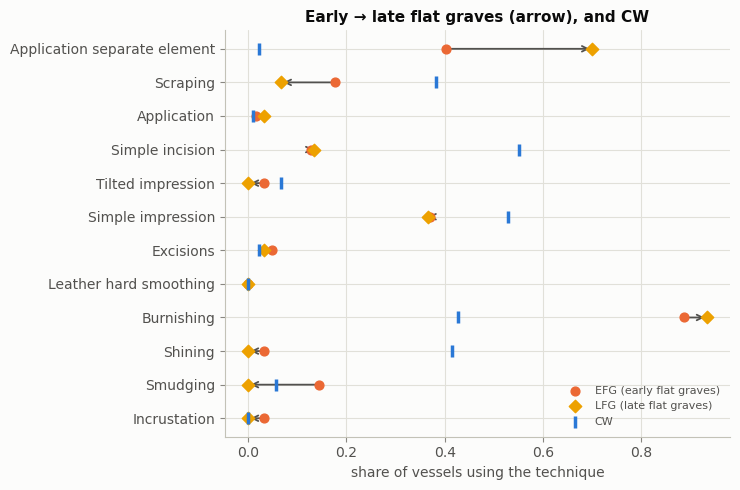

,EFG,MI,LFG,CW,LFG − EFG,"p (exact, sites)"
Application separate element,0.403,0.326,0.700,0.022,0.297,0.145
Scraping,0.177,0.232,0.067,0.382,-0.111,0.395
Application,0.016,0.000,0.033,0.011,0.017,0.567
Simple incision,0.129,0.284,0.133,0.551,0.004,0.949
Tilted impression,0.032,0.000,0.000,0.067,-0.032,0.887
Simple impression,0.371,0.611,0.367,0.528,-0.004,0.973
Excisions,0.048,0.179,0.033,0.022,-0.015,0.802
Leather hard smoothing,0.000,0.011,0.000,0.000,0.000,1.000
Burnishing,0.887,0.853,0.933,0.427,0.046,0.623
Shining,0.032,0.074,0.000,0.416,-0.032,0.865


In [75]:
ef = np.isin(y_bok, ["EFG", "LFG"])
site_ef = df.loc[ef, "site_id"].to_numpy()
X_ef = in_vessel.loc[ef, variable].to_numpy()
share = in_vessel[variable].groupby(y_bok).mean().T[["EFG", "MI", "LFG", "CW"]]
toward = (share["CW"] - share["EFG"]).to_numpy()
lfg_sites = np.unique(df.loc[y_bok == "LFG", "site_id"])
divisions = [np.isin(site_ef, comb) for comb in itertools.combinations(np.unique(site_ef), len(lfg_sites))]
shift = lambda late: X_ef[late].mean(0) - X_ef[~late].mean(0)
obs = shift(np.isin(site_ef, lfg_sites))
null = np.array([shift(late) for late in divisions])
r_obs, r_null = np.corrcoef(obs, toward)[0, 1], np.array([np.corrcoef(d, toward)[0, 1] for d in null])
share["LFG − EFG"] = obs
share["p (exact, sites)"] = (np.abs(null) >= np.abs(obs) - 1e-12).mean(0)
print(f"r = corr(LFG − EFG, CW − EFG) = {r_obs:+.2f}; exact p (r ≥ observed) = {(r_null >= r_obs - 1e-12).mean():.2f}, "
      f"p (r ≤ observed) = {(r_null <= r_obs + 1e-12).mean():.2f}  [{len(divisions)} divisions of the 15 cemeteries]")
print(f"L1 distance to CW over the {len(variable)} techniques:  EFG", f"{np.abs(share.EFG - share.CW).sum():.2f}",
      "  MI", f"{np.abs(share.MI - share.CW).sum():.2f}", "  LFG", f"{np.abs(share.LFG - share.CW).sum():.2f}")
fig, ax = plt.subplots(figsize=(7.5, 5))
yy = np.arange(len(variable))
for i, t in enumerate(variable):
    ax.annotate("", xy=(share.loc[t, "LFG"], i), xytext=(share.loc[t, "EFG"], i),
                arrowprops=dict(arrowstyle="->", color=pl.INK["secondary"], lw=1.3))
ax.scatter(share["EFG"], yy, color=pl.COLORS["EFG"], s=40, zorder=3, label="EFG (early flat graves)")
ax.scatter(share["LFG"], yy, color=pl.COLORS["LFG"], s=40, marker="D", zorder=3, label="LFG (late flat graves)")
ax.scatter(share["CW"], yy, color=pl.COLORS["CW"], s=70, marker="|", linewidths=2.5, zorder=3, label="CW")
ax.set_yticks(yy, variable); ax.invert_yaxis(); ax.set_xlabel("share of vessels using the technique")
ax.set_title("Early → late flat graves (arrow), and CW"); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); pl.save(fig, "transfer_shift"); plt.show()
share.round(3)

**How to read it.**
- *Figure:* for each technique, the arrow goes from its share in the early flat graves to its share in the late ones; the blue bar is CW. Transfer from CW would make the arrows point at the blue bars.
- *Numbers:* they mostly point away. $r=-0.50$: the late flat graves moved *away* from CW (p = 0.79 for a move toward CW; p = 0.21 for a move away, so not significant either). Their distance to CW grows from 2.19 to 2.65 (sum of share differences over the 12 techniques).
  - Separately applied elements 40 → 70 % (CW 2 %, p = 0.15) — the large, complex bowls that define the late flat graves;
  - smudging 15 → 0 % (p = 0.12) and scraping 18 → 7 % (CW 38 %, p = 0.40);
  - shining, CW's surface treatment (42 %), stays absent (3 → 0 %).
- *Power:* with 8 and 7 cemeteries even the 30-point rise of applied elements gives p = 0.15. Only very large shifts could be detected; small borrowings would go unseen.

**Bags of technology.** A transfer may concern a combination rather than single techniques. Two checks:
1. **Bags.** The BTM of 7.7, fitted to the 12 variable techniques of all 276 vessels (5 topics). Each topic is a *bag*: techniques used together. Its prevalence in a group is the mean of $p(\text{bag}\mid\text{vessel})$; the same exact test compares early and late flat graves.
2. **How a shared technique is used.** For burnishing and the other techniques found in both cultures, the distribution of its context $(x_{t-1},x_{t+1})$ — the steps just before and after it. If CW potters learned a technique from contemporaries, CW's contexts should be closer to LFG's than to EFG's: $\mathrm{JS}(\mathrm{CW},\mathrm{EFG})-\mathrm{JS}(\mathrm{CW},\mathrm{LFG})>0$, tested with the same 6435 divisions.

In [76]:
bag_docs = [[t for t in s if t not in always] for s in df["steps"]]
bags = BTM(5, n_iter=500, seed=SEED).fit(bag_docs)
theta_bag = bags.transform(bag_docs)
prev = pd.DataFrame(theta_bag).groupby(y_bok).mean().T[["EFG", "MI", "LFG", "CW"]]
d_obs = theta_bag[ef][np.isin(site_ef, lfg_sites)].mean(0) - theta_bag[ef][~np.isin(site_ef, lfg_sites)].mean(0)
d_null = np.array([theta_bag[ef][late].mean(0) - theta_bag[ef][~late].mean(0) for late in divisions])
prev["LFG − EFG"] = d_obs
prev["p (exact, sites)"] = (np.abs(d_null) >= np.abs(d_obs) - 1e-12).mean(0)
prev.insert(0, "bag: most probable techniques", [", ".join(f"{bags.vocab[i]} {bags.phi[k, i]:.2f}" for i in np.argsort(-bags.phi[k])[:4])
                                                for k in range(bags.K)])
prev.index = [f"bag {k}" for k in range(bags.K)]
display(prev.round(3))

def contexts(steps, tau):
    s = ["START"] + list(steps) + ["END"]
    return [f"{s[i - 1]} › {s[i + 1]}" for i in range(1, len(s) - 1) if s[i] == tau]
def context_dist(mask, tau, keys):
    c = Counter(k for steps in df.loc[mask, "steps"] for k in contexts(steps, tau))
    v = np.array([c[k] for k in keys], float)
    return v / v.sum() if v.sum() else None
rows = []
ef_idx = np.where(ef)[0]
for tau in ["Burnishing", "Simple impression", "Simple incision", "Scraping", "Application separate element"]:
    keys = sorted({k for steps in df["steps"] for k in contexts(steps, tau)})
    p_cw = context_dist(y_bok == "CW", tau, keys)
    def closer(late):
        p_l = context_dist(np.isin(np.arange(len(df)), ef_idx[late]), tau, keys)
        p_e = context_dist(np.isin(np.arange(len(df)), ef_idx[~late]), tau, keys)
        return np.nan if p_l is None or p_e is None else tm.js_divergence(p_cw, p_e) - tm.js_divergence(p_cw, p_l)
    o, nl = closer(np.isin(site_ef, lfg_sites)), np.array([closer(late) for late in divisions])
    nl = nl[~np.isnan(nl)]
    rows.append({"technique": tau, **{f"uses in {b}": sum(len(contexts(s, tau)) for s in df.loc[y_bok == b, "steps"]) for b in ["EFG", "LFG", "CW"]},
                 "JS(CW, EFG) − JS(CW, LFG)": o, "p (exact, sites)": (nl >= o - 1e-12).mean()})
pd.DataFrame(rows).set_index("technique").round(3)

,bag: most probable techniques,EFG,MI,LFG,CW,LFG − EFG,"p (exact, sites)"
bag 0,"Burnishing 0.30, Application separate element 0.22, Simple impression 0.20, Smudging 0.15",0.233,0.199,0.265,0.061,0.032,0.556
bag 1,"Burnishing 0.33, Simple impression 0.27, Simple incision 0.23, Application separate element 0.16",0.113,0.120,0.148,0.085,0.036,0.072
bag 2,"Shining 0.32, Simple incision 0.28, Scraping 0.26, Simple impression 0.14",0.014,0.032,0.007,0.165,-0.008,0.316
bag 3,"Simple impression 0.23, Burnishing 0.21, Scraping 0.15, Simple incision 0.14",0.261,0.244,0.129,0.417,-0.131,0.011
bag 4,"Burnishing 0.25, Simple impression 0.20, Application separate element 0.17, Scraping 0.13",0.380,0.405,0.451,0.272,0.071,0.096


,uses in EFG,uses in LFG,uses in CW,"JS(CW, EFG) − JS(CW, LFG)","p (exact, sites)"
technique,,,,,
Burnishing,55,28,38,-0.049,0.606
Simple impression,23,11,47,-0.035,0.522
Simple incision,8,4,49,-0.504,0.995
Scraping,11,2,34,0.348,0.269
Application separate element,25,21,2,0.132,0.171


**How to read it.**
- *Bags (first table):* the five BTM topics on the variable techniques.
  - **Bag 2 is CW's bag** (shining, simple incision, scraping): 16.5 % of CW, 1.4 % of the early and 0.7 % of the late flat graves. It was not adopted.
  - Bag 3 (simple impression, burnishing, scraping, incision; 42 % in CW) *falls* from 26 % to 13 % ($p$ = 0.011 by the exact test; with 5 bags tested the Bonferroni threshold is 0.01): away from CW.
  - The FBW bags with applied elements (0 and 4) grow (23 → 27 %, 38 → 45 %; p = 0.56, 0.10).
- *Contexts (second table):* CW uses burnishing and simple impression in contexts that are *not* closer to the late flat graves than to the early ones ($p$ = 0.61, 0.52). The two positive values rest on 2 uses (scraping in the late flat graves, applied elements in CW).

**What was transferred?** In these data, no bag of technology moved from CW into the late flat graves during some 250 years side by side: they diverged, toward more applied elements and less scraping and smudging. This fits Kroon's *parallel societies*: two communities that co-existed but kept their own bodies of knowledge. The one technique that could have moved the other way is burnishing in CW (43 %). But it sits in CW's own contexts, without FBW's companions (7.7), and with undated CW vessels its timing cannot be tested.

**Limits.** Time per group, not per vessel; 15 cemeteries; the direction of a shared shift is not identified; middle FBW (megaliths) is not placed in time. Dating CW graves — even by Drenth & Lanting's CW phases — would allow the reverse test: do early CW vessels, contemporary with the late flat graves, carry more FBW techniques than late CW vessels?

## 11 · Critical assessment

Issues found in the legacy notebooks, their effect, and where they are addressed.

| # | Legacy function / step | Issue | Effect | Here |
|---|---|---|---|---|
| 1 | `create_resampled_documents` (cell 5) | pools vessels of the same label; unseeded | label information enters an unsupervised model; results change every run | seeded; built from training vessels only; permutation control (7.1) |
| 2 | evaluation (cells 29, 83–85) | tested on vessels inside the training pseudo-documents; no site grouping | optimistic, irreproducible accuracy | held-out sites (3) and cross-validation (7.3) |
| 3 | `remove_common_triplets` (cell 3) | computed on all vessels; edited documents in place — the two held-out vessels per culture kept the stop triplets; deletes the most frequent triplets, which are informative | leakage; train and test featurised differently; signal deleted | computed on training vessels; copies returned; information of every triplet (4.1); deletion by frequency vs information (7.4) |
| 4 | empirical distributions (cells 11, 18, 61, 80) | recomputed four times over three vocabulary orders, including held-out vessels | inconsistent comparisons | `get_empirical_word_distribution`, one vocabulary |
| 5 | `matching_empirical` (cell 24) | independent argmin per culture | two cultures on one topic | one-to-one Hungarian matching (4.3) |
| 6 | `classify_new_vessel` (cell 29) | mapping looked up the wrong way round | always returned "Topic_k" | fixed (4.7) |
| 7 | `LDA_manual.transform` (cell 14) | random Dirichlet start | predictions changed between calls | uniform start |
| 8 | `sbmtm.fit` only (cell 35) | one start, no refinement | a sub-optimal partition read as the result | several starts + merge-split refinement (5.1) |
| 9 | "combination of topics" (cells 64–69) | compared 0/1 group memberships with binarised word sets, greedy search | not a probabilistic comparison | $p(w\mid c)=\sum_t p(w\mid t)p(t\mid c)$ (5.3) |
| 10 | soft memberships (cell 44), overlapping SBM (cell 36) | hard partition read as membership; overlapping fit failed | no uncertainty | posterior marginals (5.4); overlapping model on single vessels + MDL comparison (7.2) |
| 11 | `infer_new_doc_membership` (cell 86) | edited the fitted graph in place; wrong state size; never run | — | fold-in by description length (5.5), tested against full recomputation |
| 12 | `classify_vessel_simple` (cell 84) | overlapping triplets as independent evidence | over-confident ("High, 100 %") | calibration reported (7.3) |
| 13 | seeds | `gt.seed_rng(0)` means *random* in graph-tool; global numpy seeds | irreproducible fits | seed offset in `fit_hsbm`; local generators; tests |
| 14 | `cluster_nodes` (network notebook) | with `'probability'` weights the triplet graph carries the first-order $p(D\mid C)$; with count weights its walks are *third*-order chains | the "triplet" model is not of the order it appears to be | walks on $G_n$ = order-$n$ chains, proved and verified (10.3) |
| 15 | random walks (network notebook) | unconditional end frequencies, inverted in one version | wrong path distribution | END symbol and grammar (10.4) |
| 16 | "transfer entropy" (network notebook) | not a transfer entropy | — | edge-JS and Markov KL with permutation tests (10.2) |
| 17 | Kroon's Wasserstein | invariant to relabelling edges | cannot tell which techniques differ | edge-aware distances (10.2) |
| 18 | labels | BoK confounded with vessel form and burial context | accuracy may reflect form or context | form baselines (7.5); context as a selection model, with its assumptions (auxiliary notebook, 2.4–2.5); form, place and context as extra words in the topic models (8) |
| 19 | class-balanced bootstrap + symmetric Dirichlet | discards the survivor proportions $p(c\mid S=1)$; implicitly optimises balanced accuracy | lower accuracy; selection ignored | selection-consistent priors, prior shift, find context (auxiliary notebook, Part 2) |
| 20 | triplets only | window length never examined | — | n = 1…5 in the topic models (9) and n-gram networks (10.3) |
| 21 | records as complete chains | eroded steps read as never made | biased practice estimates; weaker attribution of eroded vessels | deletion channel, survival per site by EM (auxiliary notebook, Part 4) |
| 22 | labels EFG, LFG | read as early and late FBW *phases*; Kroon (Appendix A) defines them as early and late *flat graves* | time and burial type are one variable | dates per group, transfer test (10.8) |

**Limits no method removes.** 276 vessels and 101 distinct chains; identical chains across BoKs cap accuracy at about 73 % (4 classes) and 89 % (CW vs FBW); FBW phase is confounded with burial context; chains are recorded macroscopically; survival and selection cannot be identified from the survivors alone (auxiliary notebook, Prop. 3 and Cor. 5).

## 12 · Conclusions, next steps, data and references

1. **Replication.** Once seeded and fitted on training vessels only, the legacy procedures run consistently and reproduce the legacy in-sample figure (hSBM cluster classifier 0.62 vs 0.64; 7.3 shows the two confusion matrices). The corrected functions and the graph-tool workflow (several starts, refinement, posterior sampling, fold-in by description length) make the hSBM results reproducible and interpretable.
2. **Solidity.** Moving from in-sample to held-out sites costs 7–9 points under cross-validation; pooled pseudo-documents produce a large part of the cultural separation the topic models display (7.1); single vessels show only weak cultural structure (7.2).
3. **Attribution works, modestly.** ≈ 0.5 accuracy for four BoKs and ≈ 0.8 for CW vs FBW on unseen sites, close to what vessel form alone gives; the chain adds information beyond form, mainly within FBW. Report baselines (majority, form, ceiling) and leave-sites-out results with every attribution claim.
4. **Which model for what.** For attribution, a supervised sequence model (Markov, 0.54) is at least as good as the topic models (0.50–0.53) and needs no bootstrap. Combining LDA with the Markov chain gives the best accuracy (0.56), and learning a weight for each transition (maximum entropy) the best-calibrated probabilities (7.6). The hSBM is the better *description*: it infers the number of topics, shows which technique groups are shared or specific, and quantifies the uncertainty of its partition.
5. **Survival and selection** (auxiliary notebook, Part 2). A survival probability depending on the chain cancels from attribution (Prop. 1) and, token-wise, is absorbed exactly by the topics (Theorem 2.3): no survival model can raise the best accuracy for vessels selected like the training ones, and survival is not identifiable from survivors (Prop. 3). LDA improves when the selection is *used* rather than discarded — survivor proportions a little, the find context as a selection model a lot — under stated assumptions.
6. **Window length.** For n ≥ 2 a bag of n-grams determines the chain (Lemma 9); accuracy hardly depends on n, while bag-of-n-gram likelihoods grow more over-confident with n. Walks on n-gram networks are order-n Markov chains (Prop. 4); held-out, pairs and triplets suffice and longer windows memorise.
7. **Pairs are (almost) enough, and reconstruction works.** First-order Markov chains — Kroon's edge weights, and the MaxCal model constrained by transition counts — capture nearly all the sequential structure; the true completion of a short gap is usually among the top three proposals.
8. **Richer data, not more resampling.** Metadata as extra words lift both topic models (hSBM 0.52 → 0.60, LDA 0.50 → 0.56 with sites held out), but only to the level of the metadata alone (0.56). With the site type, the metadata alone (0.73) beat LDA and match the hSBM; the topic models' gains are within noise. For attribution, different kinds of evidence are best combined in a log-linear (maximum-entropy) model: 0.69 with chain, location and form (auxiliary notebook, Part 6).
9. **Which triplets to delete.** The five legacy "stop" triplets all carry information about the BoK; two of them are the strongest CW-vs-FBW signal. A triplet without information cannot change an attribution (Lemma, 4.1). Deletion rules change accuracy by at most a point or two, and not robustly across fold layouts; keeping only the significant triplets loses (−0.05 ± 0.02; 7.4). Every triplet is kept here (`STOP_K = 0`).
10. **Influence between cultures** is a statement about contact in time and space, not about similarity: shared traits are equally explained by shared function or inheritance unless a contact-free reference exists. The metadata carry no time per vessel. In space alone, no FBW-typical technique is significantly more frequent in CW vessels near FBW sites (10.7). Dating the sites (Appendix A) is the next step.
11. **Co-occurrence** (7.7). The culture is in *which* techniques a vessel uses: learned weights on the set of techniques (0.54) do as well as order-aware models, and co-occurring pairs add nothing. The biterm topic model needs no pseudo-documents, but its unsupervised topics do not line up with the BoKs (0.44); with a learned read-out it equals LDA (0.52).
12. **Time and transfer** (10.8). Calibrated with IntCal20, Kroon's dates place the early flat graves before CW and the late flat graves beside it for about 250 years. In that time the late flat graves moved *away* from CW: no CW technique or bag of techniques was adopted. Burnishing in CW is the only candidate for the reverse, and it sits in CW's own contexts.

**Next steps.** (i) fit the tripartite hSBM of Section 8 to single vessels, or a layered SBM, instead of pooled pseudo-documents; (ii) join petrography and radiocarbon dates from Kroon's deposit; (iii) model vessel form jointly with the chain; (iv) a hierarchical model CW / FBW → phases sharing strength between phases; (v) MaxCal with feature constraints, phase trajectories and a CW–FBW interaction term (auxiliary notebook, Part 3); (vi) validate chain → group inference on ethnographic data where group identity is known; (vii) date CW graves (phases of Drenth & Lanting) to test transfer from FBW to CW.

### Richer data
- **Kroon (2024) full deposit** – [doi:10.17026/AR/FAXIOW](https://doi.org/10.17026/AR/FAXIOW): radiocarbon dates, site coordinates, petrography (fabric recipes: an independent line of evidence), photographs, simulated sister/out-groups (Vlaardingen, Odisha).
- *Parallel societies: evidence for the co-existence of Late Funnel Beaker West and Early Corded Ware communities* (2025) – [Leiden University repository](https://scholarlypublications.universiteitleiden.nl/access/item:4247653/download).
- **Dolbunova et al. (2023)**, *Nature Human Behaviour* 7: 171–183 – hunter-gatherer pottery technology, morphology and decoration with sites and dates; [Zenodo 6619101](https://zenodo.org/records/6619101) (CC-BY). Attribute vectors rather than full sequences.
- **Manem (2020)**, *J. Archaeol. Method Theory* 27: 992–1039 – Bronze Age chaînes opératoires coded for phylogenetics ([article](https://link.springer.com/article/10.1007/s10816-019-09434-w)).
- **Ceramics & Society project** (Gosselain, ULB / AfricaMuseum) – ethnographic chaînes of about 1000 potters in about 100 linguistic groups with *known* group identity: the best test of chain → group inference (on request).
- Portals: DANS Data Station Archaeology, Archaeology Data Service, Open Context, tDAR, [open-archaeo](https://open-archaeo.info/).

### References
- Blei, Ng & Jordan (2003). Latent Dirichlet allocation. *JMLR* 3: 993–1022.
- Bronk Ramsey (2009). Bayesian analysis of radiocarbon dates. *Radiocarbon* 51: 337–360.
- Gerlach, Peixoto & Altmann (2018). A network approach to topic models. *Science Advances* 4: eaaq1360.
- Griffiths & Steyvers (2004). Finding scientific topics. *PNAS* 101: 5228–5235.
- Grootendorst (2022). BERTopic: neural topic modeling with a class-based TF-IDF procedure. arXiv:2203.05794.
- Cover & Thomas (2006). *Elements of Information Theory*, 2nd ed. Wiley.
- Hyland, Tao, Azizi, Gerlach, Peixoto & Altmann (2021). Multilayer networks for text analysis with multiple data types. *EPJ Data Science* 10. doi:10.1140/epjds/s13688-021-00288-5
- Horvitz & Thompson (1952). A generalization of sampling without replacement from a finite universe. *JASA* 47: 663–685.
- Jaynes (1980). The minimum entropy production principle. *Annu. Rev. Phys. Chem.* 31: 579–601.
- Kroon (2024). *Serial Learners.* Sidestone Press, Leiden. doi:10.59641/4e367hq
- Lindsay (1988). Composite likelihood methods. *Contemporary Mathematics* 80: 221–239.
- MacKay & Peto (1995). A hierarchical Dirichlet language model. *Natural Language Engineering* 1: 289–308.
- Patil & Rao (1978). Weighted distributions and size-biased sampling with applications to wildlife populations and human families. *Biometrics* 34: 179–189.
- Peixoto (2014). Hierarchical block structures and high-resolution model selection in large networks. *Phys. Rev. X* 4: 011047.
- Peixoto (2017). Nonparametric Bayesian inference of the microcanonical stochastic block model. *Phys. Rev. E* 95: 012317.
- Peixoto (2020). Merge-split Markov chain Monte Carlo for community detection. *Phys. Rev. E* 102: 012305.
- Peixoto (2021). Revealing consensus and dissensus between network partitions. *Phys. Rev. X* 11: 021003.
- Pressé, Ghosh, Lee & Dill (2013). Principles of maximum entropy and maximum caliber in statistical physics. *Rev. Mod. Phys.* 85: 1115–1141.
- Reimer et al. (2020). The IntCal20 Northern Hemisphere radiocarbon age calibration curve (0–55 cal kBP). *Radiocarbon* 62: 725–757.
- Roux (2019). *Ceramics and Society: A Technological Approach to Archaeological Assemblages.* Springer.
- Saerens, Latinne & Decaestecker (2002). Adjusting the outputs of a classifier to new a priori probabilities: a simple procedure. *Neural Computation* 14: 21–41.
- Varin, Reid & Firth (2011). An overview of composite likelihood methods. *Statistica Sinica* 21: 5–42.
- Yan, Guo, Lan & Cheng (2013). A biterm topic model for short texts. *Proc. WWW 2013*: 1445–1456.